# PneuNet E5 — 3-Level Lung Segmentation × ROI Treatment × Preprocessing

**Full ablation:** 2 pretrained segmenter (HybridGNet/CheXmask vs U-Net ResNet34) × 3 penggunaan lung mask (ROI crop / mask / crop+mask) × 3 pipeline intensitas, ditambah tiga kontrol tanpa segmentasi = **21 konfigurasi per seed**.

**Perbaikan alur eksperimen:** setiap konfigurasi mempunyai model PneuNet E5 yang **dilatih dari awal sendiri**, dengan data preprocessing sesuai ID-nya. Setelah checkpoint terbaik *konfigurasi itu* dipilih berdasarkan **validation loss minimum**, notebook mengukur **train, validation, dan test** dan menyimpan ketiganya pada folder run yang sama. Ini mengikuti pola notebook factorial E5 pembanding, bukan memakai satu checkpoint E5 untuk seluruh eksperimen.

**Perhatian metodologis:** Metrik test seluruh 21 kondisi tersedia untuk analisis ablation / generalization gap. Pemilihan konfigurasi unggulan untuk klaim generalisasi independen tetap sebaiknya berdasarkan validation, bukan ranking test. Tidak ada ground-truth mask paru: downstream Macro-F1 **bukan** Dice segmentasi.

**Eksekusi yang dianjurkan:** Smoke mask → audit visual → generate full mask → training full 21 kondisi + evaluasi test per run → ringkasan & Grad-CAM. Smoke **tidak** menyentuh test.


## 0. Persiapan lingkungan dan pretrained weights

Diperlukan: CUDA PyTorch, torchvision, scipy, NumPy, OpenCV, pandas, scikit-learn, matplotlib, tqdm, PIL; `torch-geometric` untuk HybridGNet; `lungs-segmentation` untuk U-Net ResNet34.

Jalankan perintah di bawah memakai interpreter kernel aktif (`sys.executable`), bukan Python environment lain.

Jalankan pada environment GPU yang kompatibel. Setup paket dapat berbeda antara versi PyTorch/CUDA. Periksa dokumentasi [PyG](https://pytorch-geometric.readthedocs.io/en/latest/install/installation.html); **jangan sembarang memasang versi lama** yang dapat merusak environment E5.

```bash
python -m pip install torch-geometric==2.4.0
# Paket lungs-segmentation mendeklarasikan dependency lama (torch 1.7.1).
# Pakai runtime PyTorch/torchvision/NumPy/OpenCV yang sudah tersedia:
python -m pip install --no-deps lungs-segmentation==1.1.2
git clone https://github.com/ngaggion/CheXmask-Database.git third_party/CheXmask-Database
```

**Unduh weights asli CheXmask** dari tautan yang diberikan [README resmi](https://github.com/ngaggion/CheXmask-Database) (Google Drive, `bestMSE.pt`) dan simpan pada `third_party/CheXmask-Database/Weights/SegmentationModel/bestMSE.pt`. **Notebook tidak mengarang atau membuat checkpoint itu.**

`lungs-segmentation` akan mengunduh bobot `resnet34.pth` versi resmi via `create_model("resnet34")` saat pertama diminta.

Urutan eksekusi yang disarankan: konfigurasi → data/split → *mask smoke* → QC visual → *training smoke* → generate semua mask → QC → 21 full runs → pilih validation → final test. Jika output file sudah ada dan fingerprint checkpoint tidak cocok, notebook akan menolak menggunakannya.

### Konfigurasi yang disarankan

**Smoke (uji inferensi, training satu update, val & Grad-CAM val jika diaktifkan; TANPA test):**

```python
GENERATE_MASKS = True; MASK_MODE = 'smoke'
RUN_TRAINING = True; MODELING_RUN_MODE = 'smoke'
RUN_FINAL_TEST = False; RUN_GRADCAM = True
MASK_QC_APPROVED = False
SELECTED_EXPERIMENT_IDS = None  # 3 contoh: kontrol, HybridGNet, U-Net
```

**Full (21 model E5 + evaluasi test setiap run):** setelah melihat audit mask, gunakan:

```python
GENERATE_MASKS = True; MASK_MODE = 'full'
RUN_TRAINING = True; MODELING_RUN_MODE = 'full'
SELECTED_EXPERIMENT_IDS = None; SEEDS = (42,)
MASK_QC_APPROVED = True  # HANYA setelah QC mask sendiri
EVALUATE_TEST_AFTER_EACH_FULL_RUN = True
EVALUATE_TRAIN_AFTER_EACH_FULL_RUN = True
RUN_FINAL_TEST = False  # Tidak perlu: test sudah dilakukan per run
RUN_GRADCAM = True       # Opsional; ID kosong -> seluruh 21 kondisi
```

Jika seluruh mask sudah ada, set `GENERATE_MASKS=False` untuk menghindari inferensi ulang. `RUN_FINAL_TEST=True` hanya untuk backfill dari `best.pt` full run yang belum memiliki test. **Jangan gunakan smoke checkpoint sebagai hasil penelitian.**

**Format unduhan:** release CheXmask adalah ZIP berisi beberapa model. Ekstrak hanya `SegmentationModel/bestMSE.pt` ke `HYBRID_WEIGHTS`; jangan mengganti ekstensi ZIP menjadi `.pt` atau memakai bobot `IndividualRCA`.

PyG 2.4.0 dipakai untuk kompatibilitas subclass `ChebConv` HybridGNet; PyG 2.7.0 memicu `propagate() got an unexpected keyword argument x` pada kode upstream ini.


In [1]:
from pathlib import Path
from datetime import datetime
import sys, os, re, gc, math, json, time, random, hashlib, tempfile, traceback
import numpy as np

# Edit manual bila kernel dijalankan dari subfolder yang bukan bagian workspace Pneumonia.
WORKSPACE_OVERRIDE = None  # Contoh: Path('/mnt/extended-home/.../Pneumonia')
WORKSPACE = (Path(WORKSPACE_OVERRIDE).resolve() if WORKSPACE_OVERRIDE else next(
    (p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
     if (p/'Datasets'/'chest_xray').is_dir()), Path.cwd().resolve()))
ROOT = WORKSPACE/'Datasets'/'chest_xray'
THIRD_PARTY = WORKSPACE/'third_party'/'CheXmask-Database'
HYBRID_WEIGHTS = THIRD_PARTY/'Weights'/'SegmentationModel'/'bestMSE.pt'
CACHE_ROOT = WORKSPACE/'tmp'/'pneunet_e5_segmentation_3level'
OUTPUT_ROOT = WORKSPACE/'output_pneunet_e5_segmentation_3level'

# TAHAP INFERENSI MASK
GENERATE_MASKS = True       
MASK_MODE = 'full'          # 'smoke': 16 gambar per kelas per split train/val; 'full': semua gambar
MASK_SEGMENTERS = ('hybridgnet','unet_resnet34')

# TAHAP MODELING
RUN_TRAINING = True
MODELING_RUN_MODE = 'full'  # 'smoke' hanya 1 epoch, batch 32; 'full' semua config
SEEDS = (42,)               # Ulangi dengan seed tambahan untuk ketidakpastian statistik
SELECTED_EXPERIMENT_IDS = None  # None=21 full; smoke=3 contoh (kontrol + kedua segmenter)

# EVALUASI TERINTEGRASI — paling penting untuk full ablation
# Saat mode='full', SETIAP run secara otomatis: train -> best validation checkpoint
# -> evaluasi train + val + test -> simpan CSV/JSON untuk run tersebut.
EVALUATE_TEST_AFTER_EACH_FULL_RUN = True
EVALUATE_TRAIN_AFTER_EACH_FULL_RUN = True

# Evaluasi terpisah (opsional, backfill/recheck checkpoint full yang sudah ada).
# Jika False, ringkasan di Cell 11 TETAP membaca seluruh hasil test yang sudah tersimpan.
RUN_FINAL_TEST = False
FINAL_TEST_EXPERIMENT_IDS = ()  # Kosong -> semua 21 experiment IDs
FINAL_TEST_SEED = 42           # Bila SEEDS berisi beberapa seed, Cell 11 akan memakai SEMUA SEEDS

# Grad-CAM: smoke pada validation; full pada test. Kosong -> ID yang dijalankan.
RUN_GRADCAM = True
GRADCAM_EXPERIMENT_IDS = ()
GRADCAM_SAMPLES_PER_CLASS = 2

# QUALITY CONTROL
MASK_QC_APPROVED = True    
MIN_MASK_AREA_FRAC = 0.03   # Flag QC, bukan filter ke model/classifier
MAX_MASK_AREA_FRAC = 0.85
QC_VISUAL_SAMPLES_PER_CLASS = 4
ROI_MARGIN = 0.10
UNET_THRESHOLD = 0.20   # default contoh API resmi, bukan dioptimasi berdasarkan test

SEED = 42
IMG_SIZE = 224
EXPECTED_COUNTS = {'train':4646,'val':586,'test':624}
SPLITS = ('train','val','test')
CLASS_NAMES = ('NORMAL','PNEUMONIA')
CLASS_TO_ID = {v:i for i,v in enumerate(CLASS_NAMES)}
IMAGE_EXTENSIONS = {'.jpeg','.jpg','.png','.bmp','.tif','.tiff','.webp'}
CLAHE_CLIP_LIMIT = 2.5
CLAHE_TILE_GRID_SIZE = (8,8)
ROTATION_MAX_DEGREES = 15.
GAUSSIAN_SIGMA_RANGE = (.5,1.5)
AUGMENTATION_PROBS = (.5,.25,.25)  # Original / Rotation / Blur pada train
CPU_THREADS = 2
ARCH_VERSION = 'PneuNet_E5_segmentation_3level_v1'
LOSS_VERSION = 'inverse_frequency_weighted_bce_v1'
DETERMINISTIC = True
DEVICE_REQUEST = 'cuda:0'
CUBLAS_WORKSPACE = ':4096:8'

TRAIN_CONFIG = dict(seed=SEED,image_size=224,batch_size=32,epochs=50,
    learning_rate=.001,beta_1=.9,beta_2=.999,epsilon=1e-7,
    dropout=.3,l2=.001,early_stopping_patience=7,
    bn_eps=.001,bn_momentum=.01,threshold=.5,initial_weights=None,
    use_class_weighting=True, loss_version=LOSS_VERSION)

assert MASK_MODE in ('smoke','full') and MODELING_RUN_MODE in ('smoke','full')
assert ROI_MARGIN >= 0 and 0 < UNET_THRESHOLD < 1
print('Workspace:', WORKSPACE)
print('Data folder:', ROOT)
print('Weights HybridGNet:',HYBRID_WEIGHTS)
print('Status generate masks:', GENERATE_MASKS,'| train:',RUN_TRAINING, '| per-run test:',EVALUATE_TEST_AFTER_EACH_FULL_RUN, '| test backfill:',RUN_FINAL_TEST)

Workspace: /home/arsyadmuhammad/AI Project/Pneumonia
Data folder: /home/arsyadmuhammad/AI Project/Pneumonia/Datasets/chest_xray
Weights HybridGNet: /home/arsyadmuhammad/AI Project/Pneumonia/third_party/CheXmask-Database/Weights/SegmentationModel/bestMSE.pt
Status generate masks: True | train: True | per-run test: True | test backfill: False


In [2]:
import cv2, torch, pandas as pd, matplotlib.pyplot as plt
from torch import nn
from torch.nn import functional as F
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from tqdm.auto import tqdm
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, average_precision_score, accuracy_score
from IPython.display import display
import scipy.sparse as sp

os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', CUBLAS_WORKSPACE)
cv2.setNumThreads(CPU_THREADS)
CACHE_ROOT.mkdir(parents=True,exist_ok=True)
OUTPUT_ROOT.mkdir(parents=True,exist_ok=True)
DEVICE = torch.device(DEVICE_REQUEST if torch.cuda.is_available() else 'cpu')
PIN_MEMORY = torch.cuda.is_available()
print('PyTorch',torch.__version__,'| CUDA',torch.cuda.is_available(),'| device',DEVICE)
if not ROOT.is_dir():
    raise FileNotFoundError('Dataset belum ada. Set WORKSPACE_OVERRIDE ke proyek berisi Datasets/chest_xray.')

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)

def configure_pytorch(seed):
    if not torch.cuda.is_available(): raise RuntimeError('Training PneuNet E5 memerlukan CUDA.')
    set_seed(seed)
    torch.set_num_threads(CPU_THREADS)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = DETERMINISTIC
    torch.backends.cuda.matmul.allow_tf32 = False
    torch.backends.cudnn.allow_tf32 = False
    torch.use_deterministic_algorithms(DETERMINISTIC)

def hash_file(path, chunk_size=2**20):
    digest=hashlib.sha256()
    with open(path,'rb') as f:
        for part in iter(lambda:f.read(chunk_size),b''): digest.update(part)
    return digest.hexdigest()

def to_json(path, object_):
    path=Path(path); path.parent.mkdir(parents=True,exist_ok=True)
    tmp=path.with_name(path.name+'.tmp')
    tmp.write_text(json.dumps(object_,indent=2,default=str),encoding='utf-8')
    tmp.replace(path)

def read_gray(path):
    image=cv2.imread(str(path),cv2.IMREAD_GRAYSCALE)
    if image is None or image.ndim != 2: raise ValueError(f'Gagal membaca gambar: {path}')
    return image

def check_segmentation_dependencies(segmenters):
    import importlib.util
    import importlib
    import shlex
    importlib.invalidate_caches()
    packages = {'hybridgnet': ('torch_geometric', 'torch-geometric==2.4.0'),
                'unet_resnet34': ('lungs_segmentation', '--no-deps lungs-segmentation==1.1.2')}
    missing = []
    for segmenter in segmenters:
        module, requirement = packages[segmenter]
        if importlib.util.find_spec(module) is None:
            missing.append(f'{shlex.quote(sys.executable)} -m pip install {requirement}')
    if missing:
        raise RuntimeError('Dependency segmentasi belum tersedia di kernel ' + sys.executable
                           + '. Jalankan pada terminal:\n' + '\n'.join(missing)
                           + '\nKemudian jalankan ulang sel import; PyTorch/CUDA yang ada tetap dipakai.')

if GENERATE_MASKS:
    check_segmentation_dependencies(MASK_SEGMENTERS)


PyTorch 2.8.0+cu126 | CUDA True | device cuda:0


## 1. Inventaris data, split dan rancangan 21 eksperimen

P1: `raw → letterbox → /255`; P2: `CLAHE → letterbox` (uint8 0–255); P3: `CLAHE → letterbox → augmentasi statis` (uint8 0–255, hanya train). Ketika cropping/masking digunakan, segmentasi/ROI diterapkan **sebelum** CLAHE; mask biner diterapkan **sesudah** CLAHE agar background hard-mask tetap nol. Transformasi geometris label dan mask dijaga selaras.

In [3]:
rows=[]
for split in SPLITS:
    for label in CLASS_NAMES:
        folder=ROOT/split/label
        if not folder.is_dir(): raise FileNotFoundError(folder)
        for path in sorted(folder.rglob('*')):
            if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS:
                rows.append({'path':str(path.resolve()),'split':split,'label':label,'y':CLASS_TO_ID[label],
                             'relpath':str(path.relative_to(ROOT))})
df=pd.DataFrame(rows)
assert not df.empty and df.path.is_unique
for s in SPLITS:
    assert int((df.split==s).sum())==EXPECTED_COUNTS[s], (s,(df.split==s).sum(),EXPECTED_COUNTS[s])
    assert set(df[df.split==s].y)=={0,1}
df['file_size']=[Path(p).stat().st_size for p in df.path]
df['mtime_ns']=[Path(p).stat().st_mtime_ns for p in df.path]
SOURCE_FINGERPRINT=hashlib.sha256(df[['relpath','split','y','file_size','mtime_ns']].to_json(orient='records').encode()).hexdigest()
print('Dataset fingerprint:',SOURCE_FINGERPRINT)
display(pd.crosstab(df.split,df.label,margins=True))

PREPROCESS_PIPELINES = {
 'P1': {'label':'Normalisasi /255', 'clahe':False,'augment':False,'normalize':True},
 'P2': {'label':'CLAHE, tanpa /255','clahe':True,'augment':False,'normalize':False},
 'P3': {'label':'CLAHE + Aug, tanpa /255','clahe':True,'augment':True,'normalize':False},
}
SEGMENTERS=('hybridgnet','unet_resnet34')
METHODS=('crop','mask','crop_mask')
CONTROL_VARIANT='original'
EXPERIMENTS=[{'id':f'S0__{p}', 'segmenter':'none','method':'original','variant':CONTROL_VARIANT,
              'pipeline':p} for p in PREPROCESS_PIPELINES]
EXPERIMENTS += [dict(id=f'{s}__{m}__{p}',segmenter=s,method=m,variant=f'{s}__{m}',pipeline=p)
                for s in SEGMENTERS for m in METHODS for p in PREPROCESS_PIPELINES]
assert len(EXPERIMENTS)==21 and len({e['id'] for e in EXPERIMENTS})==21
EXP_BY_ID={e['id']:e for e in EXPERIMENTS}
display(pd.DataFrame(EXPERIMENTS))

Dataset fingerprint: 1b2659478762a3b10383240e87ad8edbec2b94facec6f77cad242653bbbc2a46


label,NORMAL,PNEUMONIA,All
split,,,
test,234,390,624
train,1198,3448,4646
val,151,435,586
All,1583,4273,5856


,id,segmenter,method,variant,pipeline
0,S0__P1,none,original,original,P1
1,S0__P2,none,original,original,P2
2,S0__P3,none,original,original,P3
3,hybridgnet__crop__P1,hybridgnet,crop,hybridgnet__crop,P1
4,hybridgnet__crop__P2,hybridgnet,crop,hybridgnet__crop,P2
5,hybridgnet__crop__P3,hybridgnet,crop,hybridgnet__crop,P3
6,hybridgnet__mask__P1,hybridgnet,mask,hybridgnet__mask,P1
7,hybridgnet__mask__P2,hybridgnet,mask,hybridgnet__mask,P2
8,hybridgnet__mask__P3,hybridgnet,mask,hybridgnet__mask,P3
9,hybridgnet__crop_mask__P1,hybridgnet,crop_mask,hybridgnet__crop_mask,P1


## 2. Dua pretrained segmenter — inference, **bukan training**

`HybridGNet`: menggunakan arsitektur dan matriks graph `genMatrixesLungsHeart` resmi, input 1024×1024 grayscale float32, kontur 44 titik kanan + 50 titik kiri (jantung diabaikan). Output mask dikembalikan ke koordinat resolusi asli dengan inversi letterbox. **Area jantung tidak disertakan**.

`U-Net ResNet34`: menggunakan `create_model('resnet34')` dari paket resmi, input RGB hasil duplikasi grayscale yang di-min-max-normalize dan resize 512×512, output dua channel dan threshold 0.2 seperti contoh resmi. Output mask dikembalikan ke resolusi asli dengan nearest-neighbor.

*Perbedaan preprocessing segmenter mengikuti pipeline resmi masing-masing model, bukan preprocessing PneuNet.*

In [4]:
def pad_to_square(image, side):
    h,w=image.shape
    scale=side/max(h,w)
    nh=max(1,min(side,int(round(h*scale))))
    nw=max(1,min(side,int(round(w*scale))))
    interp=cv2.INTER_AREA if scale<1 else cv2.INTER_LINEAR
    resized=cv2.resize(image,(nw,nh),interpolation=interp)
    top=(side-nh)//2; left=(side-nw)//2
    canvas=np.zeros((side,side),dtype=image.dtype)
    canvas[top:top+nh,left:left+nw]=resized
    return canvas,dict(top=top,left=left,nh=nh,nw=nw,original_h=h,original_w=w)

def unpad_mask(square_mask,geo):
    t,l,nh,nw=geo['top'],geo['left'],geo['nh'],geo['nw']
    roi=square_mask[t:t+nh,l:l+nw]
    assert roi.size
    return cv2.resize(roi.astype(np.uint8),(geo['original_w'],geo['original_h']),
                      interpolation=cv2.INTER_NEAREST)>0

class HybridGNetPredictor:
    def __init__(self):
        if not THIRD_PARTY.is_dir():
            raise FileNotFoundError('Clone CheXmask-Database ke: '+str(THIRD_PARTY))
        if not HYBRID_WEIGHTS.is_file():
            raise FileNotFoundError('Unduh bestMSE.pt asli dari README CheXmask ke: '+str(HYBRID_WEIGHTS))
        check_segmentation_dependencies(('hybridgnet',))
        hybrid_module_dir=str(THIRD_PARTY/'HybridGNet')
        if hybrid_module_dir not in sys.path: sys.path.insert(0,hybrid_module_dir)
        try:
            from models.HybridGNet2IGSC import Hybrid
            from utils.utils import scipy_to_torch_sparse, genMatrixesLungsHeart
        except Exception as error:
            raise RuntimeError(f'Gagal import HybridGNet pada {sys.executable}: {type(error).__name__}: {error}') from error
        A,AD,D,U=genMatrixesLungsHeart()
        n1,n2=A.shape[0],AD.shape[0]
        def sparse_matrix(a): return scipy_to_torch_sparse(sp.csc_matrix(a).tocoo()).to(DEVICE)
        adj=[A,A,A,AD,AD,AD]
        A_t=[sparse_matrix(a) for a in adj]
        D_t=[sparse_matrix(D)]
        U_t=[sparse_matrix(U)]
        f=32
        cfg=dict(n_nodes=[n1,n1,n1,n2,n2,n2],latents=64,inputsize=1024,
                 filters=[2,f,f,f,f//2,f//2,f//2],skip_features=f)
        self.model=Hybrid(cfg,D_t,U_t,A_t).to(DEVICE)
        # The release download is a ZIP containing multiple different models.
        # A ZIP renamed bestMSE.pt is not the segmentation state_dict.
        import zipfile
        if zipfile.is_zipfile(HYBRID_WEIGHTS):
            with zipfile.ZipFile(HYBRID_WEIGHTS) as archive:
                if 'SegmentationModel/bestMSE.pt' in archive.namelist():
                    raise RuntimeError('HYBRID_WEIGHTS menunjuk arsip release, bukan checkpoint. '
                                       'Ekstrak member SegmentationModel/bestMSE.pt dari ZIP tersebut '
                                       'ke path HYBRID_WEIGHTS; jangan gunakan checkpoint IndividualRCA.')
        state=torch.load(HYBRID_WEIGHTS,map_location=DEVICE,weights_only=True)
        self.model.load_state_dict(state,strict=True)
        self.model.eval()
        self.identity=hash_file(HYBRID_WEIGHTS)
        self.source_sha256=hash_file(THIRD_PARTY/'HybridGNet'/'models'/'HybridGNet2IGSC.py')

    # Sparse graph transpose in upstream Pool needs normal tensor version counters.
    @torch.no_grad()
    def predict(self, gray):
        padded,geometry=pad_to_square(gray,1024)
        arr=padded.astype(np.float32)/255.
        image=torch.from_numpy(arr.copy())[None,None].to(DEVICE)
        output=self.model(image)
        if isinstance(output,(tuple,list)): output=output[0]
        landmarks=output.detach().cpu().numpy().reshape(-1,2)
        if len(landmarks)<94: raise RuntimeError('HybridGNet tidak menghasilkan kontur paru lengkap')
        coords=np.rint(landmarks*1024).astype(np.int32)
        square_mask=np.zeros((1024,1024),np.uint8)
        cv2.fillPoly(square_mask,[coords[:44].reshape(-1,1,2),coords[44:94].reshape(-1,1,2)],1)
        return unpad_mask(square_mask,geometry)

class UNetResNet34Predictor:
    def __init__(self):
        check_segmentation_dependencies(('unet_resnet34',))
        try:
            from lungs_segmentation.pre_trained_models import create_model
        except Exception as exc:
            raise RuntimeError(f'Gagal import U-Net pada {sys.executable}: {type(exc).__name__}: {exc}') from exc
        self.model=create_model('resnet34').to(DEVICE).eval()
        # Fingerprint parameter efektif; bukan inferensi state checkpoint yang belum diunduh.
        sha=hashlib.sha256()
        for key,tensor in self.model.state_dict().items():
            sha.update(key.encode()); sha.update(tensor.cpu().numpy().tobytes())
        self.identity=sha.hexdigest()
        release=Path(torch.hub.get_dir())/'checkpoints'/'resnet34.pth'
        self.release_weights_sha256=hash_file(release) if release.is_file() else None
        self.source_sha256=None

    @torch.inference_mode()
    def predict(self,gray):
        rgb=cv2.cvtColor(gray,cv2.COLOR_GRAY2RGB).astype(np.float32)
        lo,hi=rgb.min(),rgb.max()
        rgb=(rgb-lo)/(hi-lo) if hi>lo else np.zeros_like(rgb)
        # Resizing direct 512x512 meniru Compose.Resize pada repo resmi.
        rgb=cv2.resize(rgb,(512,512),interpolation=cv2.INTER_LINEAR)
        tensor=torch.from_numpy(rgb.transpose(2,0,1).copy())[None].float().to(DEVICE)
        channels=torch.sigmoid(self.model(tensor))[0].detach().cpu().numpy()
        if channels.ndim!=3 or channels.shape[0]!=2:
            raise ValueError('Checkpoint U-Net bukan segmentasi dua paru: '+str(channels.shape))
        union=np.any(channels>UNET_THRESHOLD,axis=0).astype(np.uint8)
        return cv2.resize(union,(gray.shape[1],gray.shape[0]),interpolation=cv2.INTER_NEAREST).astype(bool)

SEGMENTER_BUILDERS={'hybridgnet':HybridGNetPredictor,'unet_resnet34':UNetResNet34Predictor}

## 3. Cache mask asli, provenance, dan audit tanpa ground-truth

Mask output disimpan sebagai PNG biner resolusi asli; manifest mencatat **SHA256 bobot aktual**, checksum dataset, parameter segmentasi, serta aturan mask. Kegagalan inferensi atau mask kosong tidak boleh diganti dengan mask syntetik/ground-truth yang tidak tersedia. Threshold/parameter QC tidak diubah berdasarkan nilai test PneuNet.

In [ ]:
def mask_dir(segmenter): return CACHE_ROOT/'masks'/segmenter

def mask_path(segmenter, source_index):
    row=df.iloc[int(source_index)]
    key=hashlib.sha256(row.relpath.encode()).hexdigest()[:24]
    return mask_dir(segmenter)/row['split']/row['label']/(key+'.png')

def validate_mask(mask, source_index=None):
    mask=np.asarray(mask)
    if mask.ndim!=2 or mask.dtype!=np.bool_ and mask.dtype!=np.uint8:
        raise ValueError('Mask harus binary grayscale numpy array')
    area=float((mask>0).mean())
    if area<=0 or area>=1: raise RuntimeError(f'Mask kosong/penuh pada {source_index}')
    return dict(area_ratio=area, suspicious=(area<MIN_MASK_AREA_FRAC or area>MAX_MASK_AREA_FRAC))

def mask_indices_for_mode(mode):
    if mode=='full': return list(range(len(df)))
    if mode!='smoke': raise ValueError(mode)
    selected=[]
    for split in ('train','val'):
        for yvalue in (0,1):
            selected.extend(df.index[(df.split==split)&(df.y==yvalue)][:16].tolist())
    return selected

def mask_provenance(segmenter):
    file=mask_dir(segmenter)/'_provenance.json'
    return json.loads(file.read_text(encoding='utf-8')) if file.is_file() else None

def generate_masks_for(segmenter,indices):
    predictor=SEGMENTER_BUILDERS[segmenter]()
    directory=mask_dir(segmenter)
    provenance=dict(segmenter=segmenter,checkpoint_sha256=predictor.identity,
                    release_weights_sha256=getattr(predictor,'release_weights_sha256',None),
                    source_sha256=getattr(predictor,'source_sha256',None),
                    dataset_fingerprint=SOURCE_FINGERPRINT,
                    threshold=UNET_THRESHOLD if segmenter=='unet_resnet34' else None,
                    geometry='original_size_binary_png', method='official_architecture_python_inference_v1')
    previous=mask_provenance(segmenter)
    if previous and any(previous.get(k)!=v for k,v in provenance.items()):
        raise RuntimeError(f'Provenance mask {segmenter} tidak cocok dengan checkpoint/dataset; gunakan cache terpisah.')
    directory.mkdir(parents=True,exist_ok=True)
    to_json(directory/'_provenance.json',provenance)
    records=[]
    for idx in tqdm(indices,desc=f'Inference {segmenter}'):
        out=mask_path(segmenter,idx)
        image=read_gray(df.iloc[idx].path)
        if out.is_file():
            stored=cv2.imread(str(out),cv2.IMREAD_UNCHANGED)
            if stored is None or stored.shape!=image.shape or not np.isin(np.unique(stored),[0,255]).all():
                raise RuntimeError(f'Cached mask invalid: {out}')
            mask=stored>0
        else:
            mask=predictor.predict(image)
            if mask.shape!=image.shape: raise RuntimeError('Dimensi mask harus sama seperti original CXR')
            validate_mask(mask,idx)
            out.parent.mkdir(parents=True,exist_ok=True)
            if not cv2.imwrite(str(out),mask.astype(np.uint8)*255): raise IOError(out)
        records.append({'source_index':idx,'segmenter':segmenter,'path':str(out),
                        'split':df.iloc[idx]['split'],'class':df.iloc[idx]['label'],
                        **validate_mask(mask,idx)})
    del predictor
    if torch.cuda.is_available(): torch.cuda.empty_cache()
    pd.DataFrame(records).to_csv(directory/f'qc_{MASK_MODE}.csv',index=False)
    return pd.DataFrame(records)

mask_generation_reports={}
if GENERATE_MASKS:
    indexes=mask_indices_for_mode(MASK_MODE)
    for segmenter in MASK_SEGMENTERS:
        mask_generation_reports[segmenter]=generate_masks_for(segmenter,indexes)
    print('Mask generation selesai:',{k:len(v) for k,v in mask_generation_reports.items()})
else:
    print('Inferensi mask tidak dijalankan. Aktifkan GENERATE_MASKS setelah memasang checkpoint asli.')

SNAPSHOT FILE HASIL — 2026-11-18 04:54:32 UTC
Dibaca dari disk tanpa menjalankan ulang sel atau training.
Jumlah file mask tersimpan; bukan ukuran akurasi segmentasi atau persetujuan QC.


segmenter,split,class,mask_png_tersimpan
hybridgnet,train,NORMAL,1198
hybridgnet,train,PNEUMONIA,3448
hybridgnet,val,NORMAL,151
hybridgnet,val,PNEUMONIA,435
hybridgnet,test,NORMAL,234
hybridgnet,test,PNEUMONIA,390
unet_resnet34,train,NORMAL,1198
unet_resnet34,train,PNEUMONIA,3448
unet_resnet34,val,NORMAL,151
unet_resnet34,val,PNEUMONIA,435


In [ ]:
def get_mask(segmenter,idx,require=True):
    file=mask_path(segmenter,idx)
    if not file.is_file():
        if require: raise FileNotFoundError(f'Mask {segmenter} tidak tersedia: {file}; jalankan GENERATE_MASKS.')
        return None
    mask=cv2.imread(str(file),cv2.IMREAD_GRAYSCALE)
    original=read_gray(df.iloc[int(idx)].path)
    if mask is None or mask.shape!=original.shape or not np.isin(np.unique(mask),[0,255]).all():
        raise ValueError(f'Mask cached tidak valid: {file}')
    validate_mask(mask,idx)
    return mask>0

def require_masks(segmenter,indices):
    meta=mask_provenance(segmenter)
    if meta is None or meta.get('dataset_fingerprint')!=SOURCE_FINGERPRINT:
        raise RuntimeError(f'Provenance {segmenter} hilang atau checksum data berbeda. Generate mask dulu.')
    if segmenter=='hybridgnet':
        if not HYBRID_WEIGHTS.is_file() or hash_file(HYBRID_WEIGHTS)!=meta.get('checkpoint_sha256') or (
            not (THIRD_PARTY/'HybridGNet'/'models'/'HybridGNet2IGSC.py').is_file() or
            hash_file(THIRD_PARTY/'HybridGNet'/'models'/'HybridGNet2IGSC.py')!=meta.get('source_sha256')):
            raise RuntimeError('HybridGNet mask checkpoint tidak cocok atau tidak tersedia.')
    else:
        # Saat menjalankan training, cek sumber checkpoint versi resmi dan hash yang tersimpan.
        cache_path=Path(torch.hub.get_dir())/'checkpoints'/'resnet34.pth'
        if not cache_path.is_file() or hash_file(cache_path)!=meta.get('release_weights_sha256'):
            raise RuntimeError('Weights file U-Net ResNet34 hilang atau SHA256 berbeda dari saat mask dibuat.')
        if abs(float(meta.get('threshold',-.1))-UNET_THRESHOLD)>1e-12:
            raise RuntimeError('Threshold U-Net berbeda dari mask yang dicache.')
    missing=[idx for idx in indices if not mask_path(segmenter,int(idx)).is_file()]
    if missing: raise FileNotFoundError(f'{segmenter}: {len(missing)} mask belum dibuat, contoh: {missing[:5]}')
    return True

def quick_mask_qc(segmenter,indices):
    values=[]
    for idx in indices:
        mask=get_mask(segmenter,idx)
        values.append({'source_index':idx,'split':df.iloc[idx]['split'],
                       'class':df.iloc[idx]['label'], **validate_mask(mask,idx)})
    table=pd.DataFrame(values)
    print(segmenter,'n=',len(table),'suspicious=',int(table.suspicious.sum()))
    display(table.groupby(['split','class'])['area_ratio'].agg(['count','mean','min','max']))
    return table

preview_indices=mask_indices_for_mode('smoke')
if all(mask_provenance(s) and all(mask_path(s,i).is_file() for i in preview_indices) for s in SEGMENTERS):
    for seg in SEGMENTERS:
        _=quick_mask_qc(seg,preview_indices)
    visual=[]
    for label in (0,1):
        visual.extend(df.index[(df.split=='val')&(df.y==label)][:QC_VISUAL_SAMPLES_PER_CLASS].tolist())
    fig,axes=plt.subplots(len(visual),3,figsize=(12,len(visual)*3),squeeze=False)
    for r,i in enumerate(visual):
        im=read_gray(df.iloc[i].path)
        axes[r,0].imshow(im,cmap='gray'); axes[r,0].set_title(f"{df.iloc[i].label} | original")
        for j,seg in enumerate(SEGMENTERS,1):
            m=get_mask(seg,i)
            axes[r,j].imshow(im,cmap='gray'); axes[r,j].imshow(m,cmap='Reds',alpha=m.astype(float)*0.4)
            axes[r,j].set_title(f'{seg} | area {m.mean():.1%}')
        for axis in axes[r]: axis.axis('off')
    fig.tight_layout(); fig.savefig(OUTPUT_ROOT/'mask_visual_quality_control.png',dpi=150)
    plt.show()
    # Kesepakatan antar-segmenter: diagnostik tanpa GT, BUKAN Dice/IoU akurasi segmentasi.
    agreement=[]
    for i in preview_indices:
        m1=get_mask('hybridgnet',i);m2=get_mask('unet_resnet34',i)
        inter=np.logical_and(m1,m2).sum();union=np.logical_or(m1,m2).sum()
        agreement.append(dict(source_index=i,split=df.iloc[i]['split'],label=df.iloc[i]['label'],
                              mask_agreement_iou=float(inter/max(union,1))))
    pd.DataFrame(agreement).to_csv(OUTPUT_ROOT/'mask_intermodel_agreement_not_accuracy.csv',index=False)
    display(pd.DataFrame(agreement).groupby(['split','label']).mask_agreement_iou.agg(['count','mean','std']))
else:
    print('Panel QC menunggu kedua pretrained mask pada indeks smoke.')

## 4. Rencana augmentasi identik dan preprocessing ROI

Komposisi **per kelas** adalah 50% original / 25% rotasi (`±15°`) / 25% Gaussian blur (`σ∈[0.5,1.5]`). Assignment dan parameter dihasilkan **sekali menggunakan seed 42**, identik untuk P3 pada setiap segmenter dan metode. Tidak ada rotasi/blur pada validation/test.

ROI cropping = bounding box union kedua paru + margin 10% dari dimensi box, clipping ke tepi. Masking = set pixel di luar paru ke 0; crop+mask = crop diikuti masking. Tidak ada perubahan mask berdasarkan label kelas.

In [ ]:
def apply_clahe(img):
    """CLAHE standar khusus jalur CLAHE, sebelum padding."""
    if img.ndim != 2 or img.dtype != np.uint8 or img.size == 0:
        raise ValueError("CLAHE membutuhkan citra grayscale uint8 yang tidak kosong.")
    transform = cv2.createCLAHE(
        clipLimit=CLAHE_CLIP_LIMIT, tileGridSize=CLAHE_TILE_GRID_SIZE,
    )
    return transform.apply(img)


def letterbox(img, size=IMG_SIZE, pad_value=0):
    """Skalakan citra grayscale secara isotropik dan pusatkan pada kanvas persegi."""
    if img.ndim != 2 or img.size == 0:
        raise ValueError("Letterbox membutuhkan citra grayscale dua dimensi yang tidak kosong.")
    if size <= 0:
        raise ValueError("Ukuran target harus positif.")
    h, w = img.shape
    scale = size / max(h, w)
    new_w = max(1, min(size, int(round(w * scale))))
    new_h = max(1, min(size, int(round(h * scale))))
    interpolation = cv2.INTER_AREA if scale < 1 else cv2.INTER_LINEAR
    resized = cv2.resize(img, (new_w, new_h), interpolation=interpolation)
    canvas = np.full((size, size), pad_value, dtype=img.dtype)
    top = (size - new_h) // 2
    left = (size - new_w) // 2
    canvas[top:top + new_h, left:left + new_w] = resized
    return canvas

In [ ]:
def gaussian_blur(img, sigma=1.0):
    """Sama dengan full ablation E0–E6: border replicate."""
    if sigma <= 0:
        raise ValueError('Sigma Gaussian harus positif.')
    return cv2.GaussianBlur(img, (0, 0), sigmaX=float(sigma), sigmaY=float(sigma),
                            borderType=cv2.BORDER_REPLICATE)


def rotate_image(img, angle):
    """Sama dengan full ablation E0–E6: pusat (w/2,h/2), padding hitam."""
    height, width = img.shape
    matrix = cv2.getRotationMatrix2D((width / 2, height / 2), float(angle), 1.0)
    return cv2.warpAffine(img, matrix, (width, height), flags=cv2.INTER_LINEAR,
                          borderMode=cv2.BORDER_CONSTANT, borderValue=0)


def augmentation_counts(n):
    """Kuota 50:25:25 dengan largest-remainder rounding, sesuai full ablation."""
    raw_counts = n * np.asarray(AUGMENTATION_PROBS)
    counts = np.floor(raw_counts).astype(int)
    remaining = int(n - counts.sum())
    order = np.argsort(-(raw_counts - counts), kind='stable')
    counts[order[:remaining]] += 1
    return counts

In [ ]:
def make_augmentation_plan_3level(source_frame,seed=SEED):
    plan=source_frame[['path','split','label','y']].copy()
    plan['aug_mode']=0;plan['rotation_degrees']=0.;plan['gaussian_sigma']=0.
    train_idx=plan.index[plan.split=='train'].to_numpy()
    labels=plan.loc[train_idx,'y'].to_numpy()
    rng=np.random.default_rng(seed)
    modes=np.empty(len(labels),dtype=np.uint8)
    for class_id in np.unique(labels):
        ix=rng.permutation(np.flatnonzero(labels==class_id))
        quotas=augmentation_counts(len(ix))
        modes[ix]=np.repeat(np.arange(3,dtype=np.uint8),quotas)
    plan.loc[train_idx,'aug_mode']=modes.astype(int)
    for i,global_index in enumerate(train_idx):
        if modes[i]==1:
            plan.at[global_index,'rotation_degrees']=float(rng.uniform(-ROTATION_MAX_DEGREES,ROTATION_MAX_DEGREES))
        elif modes[i]==2:
            plan.at[global_index,'gaussian_sigma']=float(rng.uniform(*GAUSSIAN_SIGMA_RANGE))
    assert (plan.loc[plan.split!='train','aug_mode']==0).all()
    return plan
augmentation_plan=make_augmentation_plan_3level(df)
augmentation_plan.to_csv(OUTPUT_ROOT/'static_augmentation_plan.csv',index=False)
display(pd.crosstab(df.loc[df.split=='train','label'],augmentation_plan.loc[df.split=='train','aug_mode']))

In [ ]:
def box_from_mask(mask,margin=ROI_MARGIN):
    ys,xs=np.where(mask)
    if len(xs)==0: raise RuntimeError('Mask kosong tidak boleh dipakai untuk ROI')
    h,w=mask.shape
    x1,x2=int(xs.min()),int(xs.max())+1
    y1,y2=int(ys.min()),int(ys.max())+1
    dx=math.ceil((x2-x1)*margin);dy=math.ceil((y2-y1)*margin)
    return (max(0,x1-dx),min(w,x2+dx),max(0,y1-dy),min(h,y2+dy))

def transformed_source(variant,idx):
    source=read_gray(df.iloc[int(idx)].path)
    if variant=='original':
        # No anatomical mask for control; this image is not re-centered by a segmenter.
        return source,None
    segmenter,method=variant.split('__')
    mask=get_mask(segmenter,idx)
    if method in ('crop','crop_mask'):
        x1,x2,y1,y2=box_from_mask(mask)
        source=source[y1:y2,x1:x2]
        mask=mask[y1:y2,x1:x2]
    elif method!='mask': raise ValueError(method)
    return source,mask

def processed_image_uint8(variant,idx,clahe):
    image,mask=transformed_source(variant,idx)
    if clahe: image=apply_clahe(image)
    if variant!='original':
        method=variant.split('__')[1]
        if method in ('mask','crop_mask'):
            image=np.where(mask,image,0).astype(np.uint8)
    return letterbox(image,IMG_SIZE)

def get_display_mask(variant,idx):
    if variant=='original':
        return np.zeros((IMG_SIZE,IMG_SIZE),dtype=np.uint8)
    _,mask=transformed_source(variant,idx)
    return letterbox((mask.astype(np.uint8)*255),IMG_SIZE)>0

def get_padding_mask(variant,idx):
    image,_=transformed_source(variant,idx)
    foreground=np.ones(image.shape,dtype=np.uint8)*255
    return letterbox(foreground,IMG_SIZE)==0

## 5. Lazy cache uint8 per variant (7 varian)

Hanya membuat cache ketika diperlukan oleh full run: `original`, `hybridgnet__crop`, `hybridgnet__mask`, `hybridgnet__crop_mask`, dan tiga varian U-Net. Setiap varian punya dua memmap `raw` dan `clahe` ukuran `[N,224,224]`. Saat smoke, preprocessing langsung dilakukan pada sampel kecil sehingga **tidak perlu menghasilkan seluruh cache**.

In [ ]:
def cache_variant_paths(variant):
    key=hashlib.sha256((SOURCE_FINGERPRINT+'|'+variant+'|'+str(ROI_MARGIN)+'|'+str(CLAHE_CLIP_LIMIT)+'|'+str(CLAHE_TILE_GRID_SIZE)).encode()).hexdigest()[:12]
    folder=CACHE_ROOT/'preprocessed'/f'{variant}__{key}'
    return folder,folder/'raw.npy',folder/'clahe.npy',folder/'_metadata.json'

def ensure_variant_cache(variant):
    folder,raw_path,clahe_path,meta_path=cache_variant_paths(variant)
    if raw_path.is_file() and clahe_path.is_file() and meta_path.is_file():
        meta=json.loads(meta_path.read_text())
        if meta.get('fingerprint')!=SOURCE_FINGERPRINT or meta.get('variant')!=variant:
            raise RuntimeError('Preprocessing cache fingerprint mismatch')
        expected_provenance=mask_provenance(variant.split('__')[0]) if variant!='original' else None
        if meta.get('mask_provenance')!=expected_provenance:
            raise RuntimeError('Mask checkpoint provenance changed; jangan reuse cache preprocessing.')
        return (np.load(raw_path,mmap_mode='r'),np.load(clahe_path,mmap_mode='r'))
    folder.mkdir(parents=True,exist_ok=True)
    if variant!='original':
        require_masks(variant.split('__')[0],range(len(df)))
    tmp_raw=folder/'raw.incomplete.npy';tmp_clahe=folder/'clahe.incomplete.npy'
    n=len(df)
    a=np.lib.format.open_memmap(tmp_raw,mode='w+',dtype=np.uint8,shape=(n,IMG_SIZE,IMG_SIZE))
    b=np.lib.format.open_memmap(tmp_clahe,mode='w+',dtype=np.uint8,shape=(n,IMG_SIZE,IMG_SIZE))
    for idx in tqdm(range(n),desc=f'Cache {variant}'):
        a[idx]=processed_image_uint8(variant,idx,False)
        b[idx]=processed_image_uint8(variant,idx,True)
    a.flush();b.flush();del a,b
    tmp_raw.replace(raw_path);tmp_clahe.replace(clahe_path)
    provenance=mask_provenance(variant.split('__')[0]) if variant!='original' else None
    to_json(meta_path,dict(fingerprint=SOURCE_FINGERPRINT,variant=variant,mask_provenance=provenance,
                           clahe_clip=CLAHE_CLIP_LIMIT,clahe_grid=CLAHE_TILE_GRID_SIZE,roi_margin=ROI_MARGIN))
    return np.load(raw_path,mmap_mode='r'),np.load(clahe_path,mmap_mode='r')

class E5ConditionDataset(Dataset):
    def __init__(self,variant,pipeline,source_indices,use_cache=True):
        assert pipeline in PREPROCESS_PIPELINES
        self.variant,self.pipeline=variant,pipeline
        self.source_indices=np.asarray(list(source_indices),dtype=int)
        self.flags=PREPROCESS_PIPELINES[pipeline]
        self.cached=(ensure_variant_cache(variant) if use_cache else None)
        self.labels=df.iloc[self.source_indices].y.to_numpy(np.float32)
    def __len__(self):return len(self.source_indices)
    def __getitem__(self,pos):
        idx=int(self.source_indices[pos])
        if self.cached is not None:
            original,clahe=self.cached
            arr=np.asarray(clahe[idx] if self.flags['clahe'] else original[idx],dtype=np.uint8)
        else:
            arr=processed_image_uint8(self.variant,idx,self.flags['clahe'])
        if self.flags['augment'] and df.iloc[idx]['split']=='train':
            row=augmentation_plan.iloc[idx]
            if row.aug_mode==1:arr=rotate_image(arr,row.rotation_degrees)
            if row.aug_mode==2:arr=gaussian_blur(arr,row.gaussian_sigma)
        x=arr.astype(np.float32)
        if self.flags['normalize']:x/=255.
        if x.shape!=(IMG_SIZE,IMG_SIZE) or not np.isfinite(x).all():raise RuntimeError('Invalid preprocessing input')
        if x.min()<0 or x.max()>(1.001 if self.flags['normalize'] else 255.001):raise RuntimeError('Invalid preprocessing range')
        return torch.from_numpy(x.copy()[None]),torch.tensor([self.labels[pos]],dtype=torch.float32)

def experiment_indices(experiment,split,mode='full'):
    ix=df.index[df.split==split].to_numpy()
    if mode=='full':return ix
    if split not in ('train','val'):return np.array([],dtype=int)
    return np.concatenate([ix[df.loc[ix,'y'].to_numpy()==v][:16] for v in (0,1)])

def prepare_dataset(exp,split,mode='full'):
    selected=experiment_indices(exp,split,mode)
    if exp['segmenter']!='none':require_masks(exp['segmenter'],selected)
    return E5ConditionDataset(exp['variant'],exp['pipeline'],selected,use_cache=(mode=='full'))

def make_dataloader(ds,shuffle=False,seed=42):
    return DataLoader(ds,batch_size=TRAIN_CONFIG['batch_size'],shuffle=shuffle,
                      num_workers=0,pin_memory=torch.cuda.is_available(),drop_last=False,
                      generator=torch.Generator().manual_seed(seed))

## 6. Audit data sebelum training

Lakukan audit ini sebelum full training. **Mask dengan area ganjil ditandai, bukan dihapus otomatis**; distribusi failure/abnormal tiap kelas ikut dilaporkan. Jangan memutuskan parameter mask berdasarkan test classification.

In [ ]:
def audit_preprocessing_smoke():
    # Hanya memeriksa tensor dan label, tidak membuat mask palsu untuk penelitian.
    have_both=all(mask_provenance(s) and all(mask_path(s,i).is_file() for i in mask_indices_for_mode('smoke')) for s in SEGMENTERS)
    variations=[EXP_BY_ID[f'S0__{p}'] for p in PREPROCESS_PIPELINES]
    if have_both:
        variations += [EXP_BY_ID[f'{s}__{m}__{p}'] for s in SEGMENTERS for m in METHODS for p in PREPROCESS_PIPELINES]
    rows=[]
    for exp in variations:
        ds=prepare_dataset(exp,'val',mode='smoke')
        x,y=ds[0]
        rows.append(dict(experiment=exp['id'],shape=tuple(x.shape),range_min=float(x.min()),
                         range_max=float(x.max()),dtype=str(x.dtype),label=int(y.item())))
        assert x.shape==(1,224,224) and torch.isfinite(x).all()
        assert x.max()<=(1.001 if exp['pipeline']=='P1' else 255.001)
        assert not PREPROCESS_PIPELINES[exp['pipeline']]['augment'] or all(augmentation_plan.loc[df.split=='val','aug_mode']==0)
    result=pd.DataFrame(rows)
    display(result.head(21))
    return result
preprocessing_audit=audit_preprocessing_smoke()

## 7. PneuNet E5: arsitektur **identik** dengan notebook sumber

Diambil dari definisi notebook E5 sebelumnya: stem; detail 2× residual 32; parallel depthwise branches + SE; downsample; ASPP; context 2× residual 128; **normalized learnable spatial pooling**; classifier satu logit. Target parameter trainable **785.192**.

In [ ]:
class GrayToRGB(nn.Module):
    def forward(self, inputs):
        if inputs.ndim != 4 or inputs.shape[1] != 1:
            raise ValueError("Expected NCHW grayscale input.")
        return inputs.repeat(1, 3, 1, 1)


class SamePadConv2d(nn.Conv2d):
    """SAME padding, including asymmetric padding for stride 2."""
    def forward(self, inputs):
        height, width = inputs.shape[-2:]
        kh, kw = self.kernel_size
        sh, sw = self.stride
        dh, dw = self.dilation
        ph = max(0, (math.ceil(height / sh) - 1) * sh + dh * (kh - 1) + 1 - height)
        pw = max(0, (math.ceil(width / sw) - 1) * sw + dw * (kw - 1) + 1 - width)
        x = F.pad(inputs, (pw // 2, pw - pw // 2, ph // 2, ph - ph // 2))
        return F.conv2d(x, self.weight, self.bias, self.stride, 0, self.dilation, self.groups)


class ConvBNReLU(nn.Module):
    def __init__(self, in_channels, out_channels, kernel, stride=1, dilation=1,
                 depthwise=False, config=TRAIN_CONFIG):
        super().__init__()
        self.conv = SamePadConv2d(in_channels, out_channels, kernel, stride=stride,
                                 dilation=dilation, groups=in_channels if depthwise else 1, bias=True)
        self.bn = nn.BatchNorm2d(out_channels, eps=config["bn_eps"], momentum=config["bn_momentum"])
        self.relu = nn.ReLU(inplace=False)

    def forward(self, x):
        return self.relu(self.bn(self.conv(x)))


class SEBlock(nn.Module):
    def __init__(self, channels, reduction=16):
        super().__init__()
        self.reduce = nn.Linear(channels, max(1, channels // reduction))
        self.expand = nn.Linear(max(1, channels // reduction), channels)

    def forward(self, x):
        gate = x.mean(dim=(2, 3))
        gate = torch.sigmoid(self.expand(F.relu(self.reduce(gate))))
        return x * gate[:, :, None, None]


class ConcatenateChannels(nn.Module):
    def forward(self, branches):
        return torch.cat(branches, dim=1)


class DepthwiseSeparableBlock(nn.Module):
    def __init__(self, in_channels=32, out_channels=32, config=None):
        super().__init__()

        config = TRAIN_CONFIG if config is None else config

        self.depthwise = ConvBNReLU(
            in_channels,
            in_channels,
            3,
            depthwise=True,
            config=config
        )

        self.pointwise = ConvBNReLU(
            in_channels,
            out_channels,
            1,
            config=config
        )

        # SE setelah Depthwise Separable Conv
        self.se = SEBlock(
            out_channels,
            reduction=16
        )

        self.dropout = nn.Dropout(config["dropout"])

    def forward(self, x):
        x = self.depthwise(x)
        x = self.pointwise(x)
        x = self.se(x)
        return self.dropout(x)






class LearnableSpatialPooling(nn.Module):
    """Reconstruction hypothesis matching Table 1's 16,641 trainable weights.

    128->128 and 128->1 Conv1x1 give 16,512 + 129 parameters. The paper
    describes a single 1x1 conv and sigmoid; the extra projection is inferred.
    No BatchNorm here, because it would change the table's 16,641 count.
    """
    def __init__(self, channels=128, config=None):
        super().__init__()
        self.attention_hidden = nn.Conv2d(channels, channels, 1, bias=True)
        self.attention_activation = nn.ReLU(inplace=False)
        self.attention_conv = nn.Conv2d(channels, 1, 1, bias=True)

    def forward(self, inputs):
        attention = torch.sigmoid(self.attention_conv(
            self.attention_activation(self.attention_hidden(inputs))
        ))
        return (inputs * attention).sum(dim=(2, 3))


def initialize_pneunet(module):
    if isinstance(module, (nn.Conv2d, nn.Linear)):
        nn.init.xavier_uniform_(module.weight)
        if module.bias is not None:
            nn.init.zeros_(module.bias)
    elif isinstance(module, nn.BatchNorm2d):
        nn.init.ones_(module.weight)
        nn.init.zeros_(module.bias)

In [ ]:
class PneuNet(nn.Module):
    def __init__(self, config=None):
        super().__init__()
        config = dict(TRAIN_CONFIG if config is None else config)
        self.gray_to_rgb = GrayToRGB()
        self.stem = ConvBNReLU(3, 32, 3, config=config)
        self.pointwise_branch0 = ConvBNReLU(32, 32, 1, config=config)
        self.depthwise_branches = nn.ModuleList([
            DepthwiseSeparableBlock(32, 32, config=config)
            for _ in range(3)
        ])
        self.feature_concat = ConcatenateChannels()
        
        self.downsample = nn.Sequential(
            ConvBNReLU(128, 128, 3, stride=2, depthwise=True, config=config),
            nn.Dropout(config["dropout"]),
        )
        self.aspp_1x1 = ConvBNReLU(128, 32, 1, config=config)
        self.aspp_atrous = nn.ModuleList([
            ConvBNReLU(128, 32, 3, dilation=rate, config=config) for rate in (1, 3, 6)
        ])
        self.aspp_fuse = ConvBNReLU(128, 128, 1, config=config)
        self.learnable_pooling = LearnableSpatialPooling(128, config)
        self.classifier_dropout = nn.Dropout(config["dropout"])
        self.classifier = nn.Linear(128, 1)
        self.apply(initialize_pneunet)

    def forward(self, inputs):
        stem = self.stem(self.gray_to_rgb(inputs))
        branches = [self.pointwise_branch0(stem)] + [
            branch(stem) for branch in self.depthwise_branches
        ]

        x = self.feature_concat(branches)
        x = self.downsample(x)
        x = self.aspp_fuse(torch.cat([self.aspp_1x1(x)] + [branch(x) for branch in self.aspp_atrous], dim=1))
        return self.classifier(self.classifier_dropout(self.learnable_pooling(x)))

In [ ]:
class BasicResidualBlock(nn.Module):
    def __init__(self,channels,config):
        super().__init__()
        self.conv1=nn.Conv2d(channels,channels,3,stride=1,padding=1,bias=False)
        self.bn1=nn.BatchNorm2d(channels,eps=config["bn_eps"],momentum=config["bn_momentum"])
        self.relu1=nn.ReLU(inplace=False)
        self.conv2=nn.Conv2d(channels,channels,3,stride=1,padding=1,bias=False)
        self.bn2=nn.BatchNorm2d(channels,eps=config["bn_eps"],momentum=config["bn_momentum"])
        self.relu_out=nn.ReLU(inplace=False)
    def forward(self,x):
        residual=self.bn2(self.conv2(self.relu1(self.bn1(self.conv1(x)))))
        return self.relu_out(x+residual)

In [ ]:
class ResidualBottleneckFusion(nn.Module):
    def __init__(self,config):
        super().__init__()
        self.conv1=nn.Conv2d(128,32,1,bias=False)
        self.bn1=nn.BatchNorm2d(32,eps=config["bn_eps"],momentum=config["bn_momentum"])
        self.relu1=nn.ReLU(inplace=False)
        self.conv2=nn.Conv2d(32,32,3,stride=1,padding=1,bias=False)
        self.bn2=nn.BatchNorm2d(32,eps=config["bn_eps"],momentum=config["bn_momentum"])
        self.relu2=nn.ReLU(inplace=False)
        self.conv3=nn.Conv2d(32,128,1,bias=False)
        self.bn3=nn.BatchNorm2d(128,eps=config["bn_eps"],momentum=config["bn_momentum"])
        self.relu_out=nn.ReLU(inplace=False)
    def forward(self,x):
        residual=self.bn3(self.conv3(self.relu2(self.bn2(self.conv2(self.relu1(self.bn1(self.conv1(x))))))))
        return self.relu_out(x+residual)

In [ ]:
E5_FLAGS={'detail':True,'fusion':False,'context':True,'normalized':True}
ABLATION_CONFIGS={'E5':dict(E5_FLAGS)}

def reset_model_state(seed):
    gc.collect()
    if torch.cuda.is_available():torch.cuda.empty_cache()
    set_seed(seed)

In [ ]:
class ConfigurableLearnableSpatialPooling(LearnableSpatialPooling):
    def __init__(self,channels=128,normalized=False,config=None):
        super().__init__(channels,config)
        self.normalized=bool(normalized)
    def attention(self,x):
        return torch.sigmoid(self.attention_conv(self.attention_activation(self.attention_hidden(x))))
    def forward(self,x):
        a=self.attention(x)
        z=(x*a).sum(dim=(2,3))
        return z/a.sum(dim=(2,3)).clamp_min(1e-6) if self.normalized else z


class PneuNetAblation(PneuNet):
    def __init__(self,experiment,config,seed):
        if experiment not in ABLATION_CONFIGS:raise ValueError(experiment)
        # All common parameters are created/initialized before optional layers.
        super().__init__(config)
        self.experiment=experiment
        self.flags=dict(ABLATION_CONFIGS[experiment])
        # Preserve freshly initialized baseline attention tensors, never trained weights.
        initial_pool=self.learnable_pooling.state_dict()
        with torch.random.fork_rng(devices=[]):
            self.learnable_pooling=ConfigurableLearnableSpatialPooling(128,self.flags["normalized"],config)
        self.learnable_pooling.load_state_dict(initial_pool,strict=True)
        self.detail_refine=nn.Sequential(*[BasicResidualBlock(32,config) for _ in range(2)]) if self.flags["detail"] else nn.Identity()
        self.bottleneck_fusion=ResidualBottleneckFusion(config) if self.flags["fusion"] else nn.Identity()
        self.context_refine=nn.Sequential(*[BasicResidualBlock(128,config) for _ in range(2)]) if self.flags["context"] else nn.Identity()
        for name in ("detail_refine","bottleneck_fusion","context_refine"):
            # Stable per-block seed; no trained weights transferred between models.
            derived=(int(seed)+int(hashlib.sha256(name.encode()).hexdigest()[:8],16))%(2**31)
            with torch.random.fork_rng(devices=[]):
                torch.manual_seed(derived)
                getattr(self,name).apply(initialize_pneunet)
    def forward(self,inputs):
        x=self.detail_refine(self.stem(self.gray_to_rgb(inputs)))
        branches=[self.pointwise_branch0(x)]+[branch(x) for branch in self.depthwise_branches]
        x=self.bottleneck_fusion(self.feature_concat(branches))
        x=self.downsample(x)
        x=self.aspp_fuse(torch.cat([self.aspp_1x1(x)]+[branch(x) for branch in self.aspp_atrous],dim=1))
        x=self.context_refine(x)
        return self.classifier(self.classifier_dropout(self.learnable_pooling(x)))


def build_ablation(experiment,seed,config=None):
    set_seed(seed)
    return PneuNetAblation(experiment,dict(TRAIN_CONFIG if config is None else config),seed)

In [ ]:
def build_pneunet(config=None):
    current = dict(TRAIN_CONFIG if config is None else config)
    return build_ablation('E5', current['seed'], current)

def inspect_ablation_stages(model):
    names=["gray_to_rgb","stem.relu","detail_refine","pointwise_branch0.relu",
        *[f"depthwise_branches.{i}.se" for i in range(3)],"feature_concat","bottleneck_fusion",
        "downsample.0.relu","aspp_fuse.relu","context_refine","learnable_pooling","classifier"]
    expected={"gray_to_rgb":[1,3,224,224],"stem.relu":[1,32,224,224],
        "detail_refine":[1,32,224,224],"pointwise_branch0.relu":[1,32,224,224],
        **{f"depthwise_branches.{i}.se":[1,32,224,224] for i in range(3)},
        "feature_concat":[1,128,224,224],"bottleneck_fusion":[1,128,224,224],
        "downsample.0.relu":[1,128,112,112],"aspp_fuse.relu":[1,128,112,112],
        "context_refine":[1,128,112,112],"learnable_pooling":[1,128],"classifier":[1,1]}
    captured={"input":[1,1,224,224]};handles=[];was_training=model.training
    try:
        for name in names:
            def hook(module,args,output,name=name):captured[name]=list(output.shape)
            handles.append(model.get_submodule(name).register_forward_hook(hook))
        model.eval()
        with torch.inference_mode():logits=model(torch.zeros(1,1,224,224,device=next(model.parameters()).device))
        assert logits.shape==(1,1) and torch.isfinite(logits).all()
        for name,shape in expected.items():assert captured[name]==shape,(name,captured.get(name),shape)
        return captured
    finally:
        for h in handles:h.remove()
        model.train(was_training)


def pooling_unit_test():
    original=ConfigurableLearnableSpatialPooling(128,False)
    normalized=ConfigurableLearnableSpatialPooling(128,True)
    normalized.load_state_dict(original.state_dict(),strict=True)
    assert sum(p.numel() for p in original.parameters())==sum(p.numel() for p in normalized.parameters())==16641
    assert original.state_dict().keys()==normalized.state_dict().keys()
    x=torch.randn(2,128,5,7,requires_grad=True)
    a=original.attention(x)
    torch.testing.assert_close(a,normalized.attention(x),rtol=0,atol=0)
    torch.testing.assert_close(original(x),(x*a).sum((2,3)))
    torch.testing.assert_close(normalized(x),(x*a).sum((2,3))/a.sum((2,3)).clamp_min(1e-6))
    for pool in [original,normalized]:
        output=pool(x);assert output.shape==(2,128) and torch.isfinite(output).all()
        output.square().mean().backward(retain_graph=True)
        assert all(p.grad is not None and torch.isfinite(p.grad).all() for p in pool.parameters())
    assert torch.isfinite(x.grad).all()
    for p in normalized.parameters():nn.init.zeros_(p)
    # Attention = 0.5 everywhere; explicit manual weighted mean.
    for h,w in [(5,7),(10,14)]:
        y=torch.randn(2,128,h,w,requires_grad=True)
        attention=torch.full((2,1,h,w),0.5)
        expected=(y*attention).sum((2,3))/attention.sum((2,3))
        torch.testing.assert_close(normalized(y),expected)
        torch.testing.assert_close(normalized(y),y.mean((2,3)))
    return {"status":"PASS","pooling_parameters":16641,"constant_attention_manual_mean":"PASS","gradient":"PASS"}

def inspect_pneunet_stages(model):
    return inspect_ablation_stages(model)

In [ ]:
set_seed(SEED)
model_audit=build_pneunet(TRAIN_CONFIG).cpu().eval()
assert sum(p.numel() for p in model_audit.parameters() if p.requires_grad)==785192
assert sum(p.numel() for p in model_audit.learnable_pooling.parameters())==16641
assert model_audit.flags==E5_FLAGS
print('E5 parameters:',sum(p.numel() for p in model_audit.parameters()))
# Audit forward CPU tanpa training
with torch.no_grad():
    output=model_audit(torch.zeros((1,1,224,224),dtype=torch.float32))
assert tuple(output.shape)==(1,1) and torch.isfinite(output).all()
del model_audit

## 8. Weighted BCE, optimizer, dan metrik klasifikasi

Weighted BCE versi sumber: `BCEWithLogitsLoss(reduction='none')` × class weight inverse-frequency per-sampel, lalu mean. Penalti **L2 eksplisit 0.001 pada Conv/Linear** dipertahankan; bukan AdamW/weight_decay. LR Adam 0.001, β=(0.9,0.999), ε=1e-7. Seed di-reset **setelah** pembuatan model/optimizer, **sebelum** loop epoch sesuai perbaikan notebook E5.

In [ ]:
def weighted_loss_config(config, train_labels):
    labels = np.asarray(train_labels).reshape(-1)
    if not len(labels) or not np.isfinite(labels).all() or not np.isin(labels, [0, 1]).all():
        raise ValueError("Label train harus 0=NORMAL atau 1=PNEUMONIA.")
    counts = np.bincount(labels.astype(np.int64), minlength=2)
    if np.any(counts == 0):
        raise ValueError("Class weighting memerlukan kedua kelas pada data train.")
    inverse = len(labels) / (2.0 * counts.astype(np.float64))
    result = dict(config)
    enabled = bool(result.get("use_class_weighting", True))
    result.update({"class_counts": counts.astype(int).tolist(),
                   "class_weights": inverse.tolist() if enabled else [1.0, 1.0],
                   "class_weight_source": "complete_training_split_only",
                   "class_weighting": "inverse_frequency_balanced" if enabled else "none",
                   "loss_reduction": "mean_over_samples"})
    return result


def make_bce_components(config, device):
    weights = torch.tensor(config["class_weights"], dtype=torch.float32, device=device)
    if weights.shape != (2,) or not torch.isfinite(weights).all() or not (weights > 0).all():
        raise ValueError("Dibutuhkan dua class weight positif berurutan NORMAL, PNEUMONIA.")
    return nn.BCEWithLogitsLoss(reduction="none"), weights


def weighted_bce_loss(logits, targets, criterion, class_weights):
    logits = logits.reshape(-1)
    targets = targets.float().reshape(-1)
    if logits.shape != targets.shape or not ((targets == 0) | (targets == 1)).all():
        raise ValueError("Bentuk logit/target harus sama dan label harus biner.")
    loss_per_sample = criterion(logits, targets)
    sample_weights = class_weights[targets.long()]
    return (loss_per_sample * sample_weights).mean()

In [ ]:
def binary_report(labels, probabilities, threshold=0.5):
    labels = np.asarray(labels).reshape(-1).astype(int)
    probabilities = np.asarray(probabilities).reshape(-1)
    if len(labels) != len(probabilities) or not np.isfinite(probabilities).all():
        raise ValueError("Invalid predictions.")
    predictions = (probabilities >= threshold).astype(int)
    report = classification_report(labels, predictions, labels=[0, 1],
                                   target_names=["NORMAL", "PNEUMONIA"],
                                   output_dict=True, zero_division=0)
    matrix = confusion_matrix(labels, predictions, labels=[0, 1])
    metrics = {"accuracy": float(accuracy_score(labels, predictions)),
               "precision_pneumonia": report["PNEUMONIA"]["precision"],
               "recall_pneumonia": report["PNEUMONIA"]["recall"],
               "f1_pneumonia": report["PNEUMONIA"]["f1-score"],
               "precision_normal": report["NORMAL"]["precision"],
               "recall_normal": report["NORMAL"]["recall"],
               "f1_normal": report["NORMAL"]["f1-score"],
               "macro_f1": report["macro avg"]["f1-score"],
               "roc_auc": float(roc_auc_score(labels, probabilities)) if len(np.unique(labels)) == 2 else None,
               "pr_auc": float(average_precision_score(labels, probabilities)) if len(np.unique(labels)) == 2 else None,
               "samples": len(labels), "threshold": float(threshold)}
    return metrics, report, matrix, predictions


@torch.inference_mode()
def predict_loader(model, loader):
    model.eval()
    pieces = []
    for images, _ in loader:
        logits = model(images.to(DEVICE, non_blocking=PIN_MEMORY))
        pieces.append(torch.sigmoid(logits).cpu().numpy().reshape(-1))
    return np.concatenate(pieces)

In [ ]:
def kernel_l2(model,config):
    terms=[module.weight.square().sum() for module in model.modules() if isinstance(module,(nn.Conv2d,nn.Linear))]
    return float(config['l2'])*torch.stack(terms).sum()

def build_optimizer(model,config):
    return torch.optim.Adam(model.parameters(),lr=config['learning_rate'],
                            betas=(config['beta_1'],config['beta_2']),eps=config['epsilon'])

def initial_weight_fingerprint(model):
    digest=hashlib.sha256()
    for key,value in model.state_dict().items():
        digest.update(key.encode());digest.update(value.detach().cpu().numpy().tobytes())
    return digest.hexdigest()

def balance_weights_for_training():
    arr=df[df.split=='train'].y.to_numpy()
    counts=np.bincount(arr,minlength=2).astype(np.float64)
    return dict(class_counts=counts.astype(int).tolist(),class_weights=(len(arr)/(2*counts)).tolist())
CLASS_WEIGHT_INFO=balance_weights_for_training()
TRAIN_CONFIG.update(CLASS_WEIGHT_INFO)
print('Class weight NORMAL/PNEUMONIA:',TRAIN_CONFIG['class_weights'])

## 9. Train + validation + test pada **masing-masing** ablasi

Setiap kombinasi `experiment_id` dan seed memiliki **PneuNet E5 tersendiri** dengan inisialisasi acak terkontrol (bukan transfer bobot antar-ablasi). Training menggunakan Weighted BCE dan early stopping. Checkpoint `best.pt` dipilih menurut **validation loss minimum** pada run tersebut. Setelah training selesai, checkpoint **run tersebut** dipakai untuk evaluasi train, validation, dan test, lalu menyimpan `*_predictions.csv`, `*_confusion_matrix.csv`, `*_classification_report.json`, `*_metrics.json` dan `result.json` untuk setiap eksperimen.

`RUN_TRAINING=True`, `MODELING_RUN_MODE='full'`, `EVALUATE_TEST_AFTER_EACH_FULL_RUN=True` → seluruh 21 kondisi dievaluasi pada test otomatis (jika `SELECTED_EXPERIMENT_IDS=None`). Test tidak digunakan untuk update bobot atau pemilihan epoch. Mode `smoke`: satu update, tanpa test; hanya pemeriksaan pipeline teknis.

**Resume:** jika full training sudah COMPLETE namun test belum dievaluasi, notebook akan melakukan *backfill* test untuk checkpoint tersebut, **bukan melatih ulang**. Jika test sudah dievaluasi lengkap, hasil hanya dibaca ulang. Konfigurasi/model yang berbeda tidak boleh mencampur cache/checkpoint.


In [ ]:
def train_one_epoch(model,loader,optimizer,config,max_batches=None):
    model.train();criterion,weights=make_bce_components(config,DEVICE)
    loss_total=0.;count=0;updates=0
    for j,(x,y) in enumerate(loader):
        if max_batches is not None and j>=max_batches:break
        x=x.to(DEVICE,non_blocking=True);y=y.to(DEVICE,non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        loss=weighted_bce_loss(model(x),y,criterion,weights)+kernel_l2(model,config)
        if not torch.isfinite(loss):raise RuntimeError('Non finite train loss')
        loss.backward();optimizer.step()
        loss_total+=float(loss.detach())*len(x);count+=len(x);updates+=1
    return loss_total/max(1,count),updates

@torch.inference_mode()
def evaluate(model,loader,config,max_batches=None):
    model.eval();criterion,weights=make_bce_components(config,DEVICE)
    total=0.;count=0;labels=[];probabilities=[]
    penalty=float(kernel_l2(model,config).detach())
    for j,(x,y) in enumerate(loader):
        if max_batches is not None and j>=max_batches:break
        x=x.to(DEVICE,non_blocking=True);y=y.to(DEVICE,non_blocking=True)
        logits=model(x)
        value=float(weighted_bce_loss(logits,y,criterion,weights).detach())+penalty
        total+=value*len(x);count+=len(x)
        labels.extend(y.cpu().numpy().reshape(-1));probabilities.extend(torch.sigmoid(logits).cpu().numpy().reshape(-1))
    if count==0:raise RuntimeError('Empty loader')
    metric,report,matrix,preds=binary_report(np.asarray(labels,dtype=int),np.asarray(probabilities),config['threshold'])
    return (total/count,metric,np.asarray(labels,dtype=int),np.asarray(probabilities),matrix,preds,report)

def result_directory(exp_id, seed, mode='full'):
    return OUTPUT_ROOT / 'runs' / mode / f'{exp_id}__seed_{seed}'


def saved_metadata_matches(out, exp, seed, mode):
    file = out / 'result.json'
    if not file.is_file():
        return None
    info = json.loads(file.read_text())
    if info.get('status') != 'COMPLETE' or info.get('mode') != mode or info.get('architecture_version') != ARCH_VERSION:
        raise RuntimeError(f'Result metadata tidak cocok: {file}')
    if info.get('seed') != seed or info.get('experiment_id') != exp['id'] or info.get('source_fingerprint') != SOURCE_FINGERPRINT:
        raise RuntimeError(f'Result metadata mismatch: {file}')
    if info.get('config') != dict(TRAIN_CONFIG, seed=seed) or (
        info.get('mask_provenance') != (mask_provenance(exp['segmenter']) if exp['segmenter'] != 'none' else None)
    ):
        raise RuntimeError('Train config atau mask provenance berubah, jangan reuse run lama.')
    if not (out / 'best.pt').is_file() or not (out / 'val_predictions.csv').is_file():
        raise RuntimeError('Result belum lengkap, periksa direktori sebelum resume')
    return info


def save_evaluated_split(model, exp, seed, config, split, directory, mode='full'):
    """Evaluasi 1 split dari checkpoint model yang sedang dimuat, tanpa training.

    Simpan semua hasil per gambar. Loader wajib tidak shuffle supaya
    source_index / label / path selalu tepat satu sama lain.
    """
    dataset = prepare_dataset(exp, split, mode=mode)
    loader = make_dataloader(dataset, shuffle=False, seed=seed)
    loss, metrics, labels, probabilities, cm, preds, report = evaluate(model, loader, config)
    source_indices = np.asarray(dataset.source_indices, dtype=np.int64)
    truth = df.iloc[source_indices].y.to_numpy(dtype=np.int64)
    assert len(labels) == len(source_indices) == len(probabilities) == len(preds)
    np.testing.assert_array_equal(labels, truth, err_msg=f'Loader order mismatch: {exp["id"]}/{split}')
    if not np.isfinite(probabilities).all():
        raise RuntimeError(f'Nonfinite prediction: {exp["id"]}/{split}')
    table = pd.DataFrame({
        'source_index': source_indices,
        'y_true': labels,
        'probability': probabilities,
        'prediction': preds,
        'source_path': df.iloc[source_indices].path.to_numpy(),
    })
    directory.mkdir(parents=True, exist_ok=True)
    table.to_csv(directory / f'{split}_predictions.csv', index=False)
    pd.DataFrame(cm, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(directory / f'{split}_confusion_matrix.csv')
    to_json(directory / f'{split}_classification_report.json', report)
    to_json(directory / f'{split}_metrics.json', metrics)
    del dataset, loader
    return float(loss), metrics


def checkpoint_is_valid(checkpoint, exp_id, seed):
    for key, expected in (
        ('architecture_version', ARCH_VERSION),
        ('experiment_id', exp_id),
        ('seed', seed),
    ):
        if checkpoint.get(key) != expected:
            raise RuntimeError(f'Checkpoint {key} mismatch: expected {expected!r}, got {checkpoint.get(key)!r}')


def test_artifacts_complete(directory):
    needed = ('test_metrics.json', 'test_predictions.csv',
              'test_confusion_matrix.csv', 'test_classification_report.json')
    return all((directory / name).is_file() for name in needed)


def evaluate_saved_full_run(exp_id, seed, force=False):
    """Evaluasi test checkpoint PER EXPERIMENT (untuk backfill atau Cell 11).

    Tidak pernah load checkpoint dari experiment lain.
    """
    exp = EXP_BY_ID[exp_id]
    directory = result_directory(exp_id, seed, 'full')
    info = saved_metadata_matches(directory, exp, seed, 'full')
    if info is None:
        raise FileNotFoundError(f'Tidak ada full training untuk {exp_id}/seed_{seed}: {directory}')
    if not force and info.get('test_evaluated') and test_artifacts_complete(directory):
        return info
    cfg = dict(TRAIN_CONFIG, seed=seed)
    model = build_pneunet(cfg).to(DEVICE)
    blob = torch.load(directory / 'best.pt', map_location='cpu', weights_only=True)
    checkpoint_is_valid(blob, exp_id, seed)
    model.load_state_dict(blob['state_dict'], strict=True)
    model.eval()
    print(f'  TEST BACKFILL {exp_id} seed={seed} from own best.pt', flush=True)
    try:
        test_loss, test_metrics = save_evaluated_split(model, exp, seed, cfg, 'test', directory, 'full')
        info.update(test_evaluated=True, test_loss=test_loss, test_metrics=test_metrics)
        to_json(directory / 'result.json', info)
        return info
    finally:
        del model
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()


def run_one(exp, seed, mode='smoke'):
    assert mode in ('smoke', 'full')
    config = dict(TRAIN_CONFIG, seed=seed)
    if config['batch_size'] != 32 or config['initial_weights'] is not None:
        raise RuntimeError('Eksperimen mengharuskan random init + physical batch 32')
    if mode == 'full' and exp['segmenter'] != 'none' and not MASK_QC_APPROVED:
        raise RuntimeError('Lakukan QC mask lalu set MASK_QC_APPROVED=True sebelum full training')
    out = result_directory(exp['id'], seed, mode)
    out.mkdir(parents=True, exist_ok=True)
    info = saved_metadata_matches(out, exp, seed, mode)
    if info is not None:
        if mode == 'full' and EVALUATE_TEST_AFTER_EACH_FULL_RUN and (
            not info.get('test_evaluated') or not test_artifacts_complete(out)
        ):
            return evaluate_saved_full_run(exp['id'], seed)
        print('SKIP COMPLETE', exp['id'], seed,
              '| TEST' if info.get('test_evaluated') else '| NO TEST', flush=True)
        return info

    set_seed(seed)
    train_ds = prepare_dataset(exp, 'train', mode)
    val_ds = prepare_dataset(exp, 'val', mode)
    train_loader = make_dataloader(train_ds, shuffle=True, seed=seed)
    val_loader = make_dataloader(val_ds, shuffle=False, seed=seed)
    model = build_pneunet(config).to(DEVICE)
    assert sum(p.numel() for p in model.parameters() if p.requires_grad) == 785192
    optimizer = build_optimizer(model, config)
    init_hash = initial_weight_fingerprint(model)
    best_loss = float('inf'); best_epoch = None; stale = 0; updates = 0; history = []
    checkpoint_path = out / 'best.pt'
    # Reset RNG persis sebelum training, sesuai full-ablation E5 terdahulu.
    set_seed(seed)
    epochs = 1 if mode == 'smoke' else config['epochs']
    for epoch in range(epochs):
        tl, u = train_one_epoch(model, train_loader, optimizer, config,
                                max_batches=1 if mode == 'smoke' else None)
        vl, vm, *_ = evaluate(model, val_loader, config,
                             max_batches=1 if mode == 'smoke' else None)
        updates += u
        history.append(dict(epoch=epoch + 1, train_loss=tl, val_loss=vl,
                            val_macro_f1=vm['macro_f1'],
                            val_recall_normal=vm['recall_normal'],
                            val_recall_pneumonia=vm['recall_pneumonia']))
        pd.DataFrame(history).to_csv(out / 'history.csv', index=False)
        if vl < best_loss:
            best_loss = vl; best_epoch = epoch + 1; stale = 0
            torch.save(dict(state_dict={k: v.detach().cpu().clone() for k, v in model.state_dict().items()},
                            config=config, architecture_version=ARCH_VERSION,
                            experiment_id=exp['id'], seed=seed, epoch=best_epoch), checkpoint_path)
        else:
            stale += 1
        print(f"  {exp['id']} seed={seed} epoch={epoch + 1}: train={tl:.5f} val={vl:.5f} val_macroF1={vm['macro_f1']:.4f}",
              flush=True)
        if stale >= config['early_stopping_patience'] and mode == 'full':
            break

    blob = torch.load(checkpoint_path, map_location='cpu', weights_only=True)
    checkpoint_is_valid(blob, exp['id'], seed)
    model.load_state_dict(blob['state_dict'], strict=True)
    model.eval()

    # Validation dinilai menggunakan best.pt dari EXPERIMENT INI.
    val_loss, val_metrics = save_evaluated_split(model, exp, seed, config, 'val', out, mode)
    info = dict(status='COMPLETE', mode=mode, architecture_version=ARCH_VERSION,
                experiment_id=exp['id'], seed=seed, source_fingerprint=SOURCE_FINGERPRINT,
                segmenter=exp['segmenter'], method=exp['method'], pipeline=exp['pipeline'],
                checkpoint=str(checkpoint_path), initial_weight_sha256=init_hash,
                best_epoch=best_epoch, epochs_ran=len(history), optimizer_updates=updates,
                val_loss=val_loss, val_metrics=val_metrics, class_weights=config['class_weights'],
                model_parameters=785192, config=config, test_evaluated=False,
                mask_provenance=mask_provenance(exp['segmenter']) if exp['segmenter'] != 'none' else None)
    to_json(out / 'result.json', info)

    # FULL: selalu evaluasi train/test dengan checkpoint terbaik run masing-masing.
    if mode == 'full':
        if EVALUATE_TRAIN_AFTER_EACH_FULL_RUN:
            train_loss, train_metrics = save_evaluated_split(model, exp, seed, config, 'train', out, 'full')
            info.update(train_loss=train_loss, train_metrics=train_metrics)
            to_json(out / 'result.json', info)
        if EVALUATE_TEST_AFTER_EACH_FULL_RUN:
            test_loss, test_metrics = save_evaluated_split(model, exp, seed, config, 'test', out, 'full')
            info.update(test_loss=test_loss, test_metrics=test_metrics, test_evaluated=True)
            to_json(out / 'result.json', info)
            print(f"  FULL {exp['id']}: VAL macro-F1={val_metrics['macro_f1']:.4f} "
                  f"| TEST macro-F1={test_metrics['macro_f1']:.4f} "
                  f"| own checkpoint best epoch={best_epoch}", flush=True)

    del model, optimizer, train_ds, val_ds, train_loader, val_loader
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return info


SNAPSHOT FILE HASIL — 2026-11-18 04:54:32 UTC
Dibaca dari disk tanpa menjalankan ulang sel atau training.


experiment,seed,status,epoch_tercatat,train_loss_terakhir,val_loss_terakhir,history_updated_utc
S0__P1,42,COMPLETE,20,0.176545,0.701198,2026-11-16 07:41:48 UTC
S0__P2,42,COMPLETE,15,0.175967,0.292027,2026-11-16 09:19:09 UTC
S0__P3,42,COMPLETE,25,0.185024,0.793651,2026-11-16 11:50:11 UTC
hybridgnet__crop__P1,42,COMPLETE,31,0.172231,0.454754,2026-11-16 15:19:36 UTC
hybridgnet__crop__P2,42,COMPLETE,18,0.224950,3.426508,2026-11-16 16:55:17 UTC
hybridgnet__crop__P3,42,COMPLETE,21,0.214327,0.300410,2026-11-16 18:45:47 UTC
hybridgnet__mask__P1,42,COMPLETE,15,0.288765,0.917307,2026-11-16 20:33:32 UTC
hybridgnet__mask__P2,42,COMPLETE,16,0.259009,0.966722,2026-11-16 22:09:55 UTC
hybridgnet__mask__P3,42,COMPLETE,20,0.237943,0.462737,2026-11-17 00:07:04 UTC
hybridgnet__crop_mask__P1,42,COMPLETE,13,0.284702,2.076721,2026-11-17 01:46:05 UTC


S0__P1 | seed=42 | COMPLETE | history: 2026-11-16 07:41:48 UTC
epoch 1: train_loss=1.338621, val_loss=7.685672, val_macro_f1=0.426053
epoch 2: train_loss=0.840357, val_loss=8.328278, val_macro_f1=0.426053
epoch 3: train_loss=0.606911, val_loss=6.688542, val_macro_f1=0.426053
epoch 4: train_loss=0.480611, val_loss=2.331062, val_macro_f1=0.446789
epoch 5: train_loss=0.402045, val_loss=0.895958, val_macro_f1=0.677908
epoch 6: train_loss=0.352624, val_loss=1.474951, val_macro_f1=0.578792
epoch 7: train_loss=0.323865, val_loss=0.591074, val_macro_f1=0.845651
epoch 8: train_loss=0.295533, val_loss=0.299967, val_macro_f1=0.925440
epoch 9: train_loss=0.269611, val_loss=0.519377, val_macro_f1=0.902216
epoch 10: train_loss=0.238950, val_loss=2.411721, val_macro_f1=0.446789
epoch 11: train_loss=0.242341, val_loss=3.127738, val_macro_f1=0.426053
epoch 12: train_loss=0.234523, val_loss=0.412301, val_macro_f1=0.852974
epoch 13: train_loss=0.221485, val_loss=0.227387, val_macro_f1=0.932158
epoch 14: 

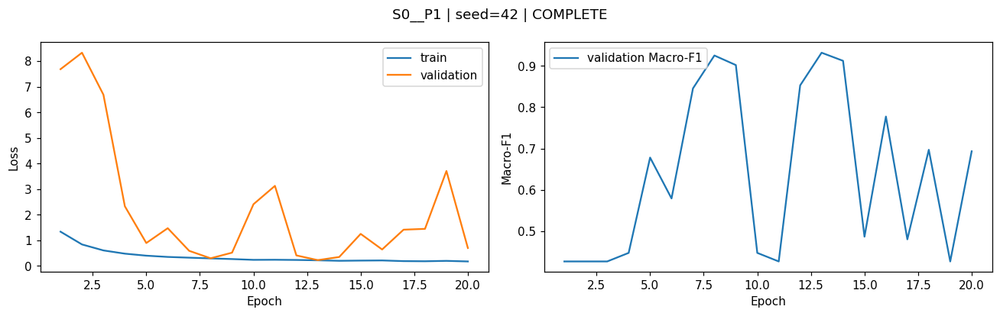

S0__P2 | seed=42 | COMPLETE | history: 2026-11-16 09:19:09 UTC
epoch 1: train_loss=1.295778, val_loss=9.669178, val_macro_f1=0.426053
epoch 2: train_loss=0.777228, val_loss=6.862928, val_macro_f1=0.426053
epoch 3: train_loss=0.537633, val_loss=4.654024, val_macro_f1=0.426053
epoch 4: train_loss=0.426779, val_loss=2.306960, val_macro_f1=0.460201
epoch 5: train_loss=0.359149, val_loss=0.448601, val_macro_f1=0.820746
epoch 6: train_loss=0.298836, val_loss=0.589878, val_macro_f1=0.818454
epoch 7: train_loss=0.274138, val_loss=0.254145, val_macro_f1=0.949666
epoch 8: train_loss=0.256649, val_loss=0.220615, val_macro_f1=0.928295
epoch 9: train_loss=0.221359, val_loss=1.294925, val_macro_f1=0.573452
epoch 10: train_loss=0.203584, val_loss=0.740173, val_macro_f1=0.777715
epoch 11: train_loss=0.219762, val_loss=3.190512, val_macro_f1=0.426053
epoch 12: train_loss=0.204862, val_loss=0.306953, val_macro_f1=0.864196
epoch 13: train_loss=0.194976, val_loss=0.282162, val_macro_f1=0.950501
epoch 14: 

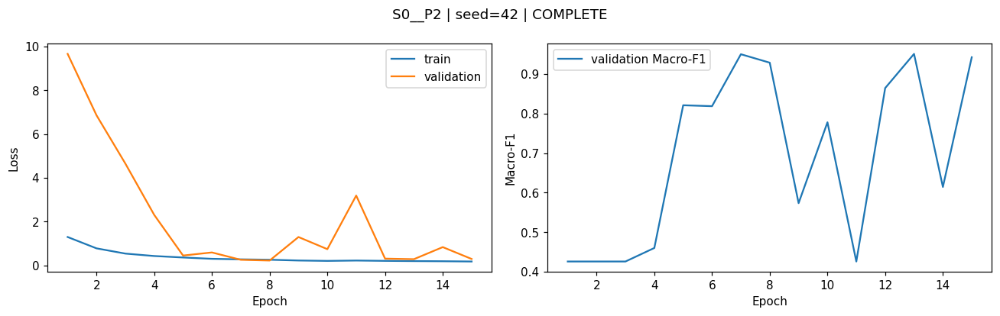

S0__P3 | seed=42 | COMPLETE | history: 2026-11-16 11:50:11 UTC
epoch 1: train_loss=1.315589, val_loss=9.090215, val_macro_f1=0.426053
epoch 2: train_loss=0.796646, val_loss=7.064637, val_macro_f1=0.426053
epoch 3: train_loss=0.562185, val_loss=1.123132, val_macro_f1=0.637405
epoch 4: train_loss=0.447281, val_loss=1.478848, val_macro_f1=0.516825
epoch 5: train_loss=0.366512, val_loss=0.884956, val_macro_f1=0.578792
epoch 6: train_loss=0.322967, val_loss=0.797989, val_macro_f1=0.781247
epoch 7: train_loss=0.303308, val_loss=0.386066, val_macro_f1=0.860395
epoch 8: train_loss=0.282531, val_loss=3.791627, val_macro_f1=0.426053
epoch 9: train_loss=0.252982, val_loss=1.812879, val_macro_f1=0.439961
epoch 10: train_loss=0.222810, val_loss=1.107723, val_macro_f1=0.661948
epoch 11: train_loss=0.227995, val_loss=1.121597, val_macro_f1=0.426053
epoch 12: train_loss=0.212866, val_loss=0.207843, val_macro_f1=0.940507
epoch 13: train_loss=0.207956, val_loss=3.063807, val_macro_f1=0.426053
epoch 14: 

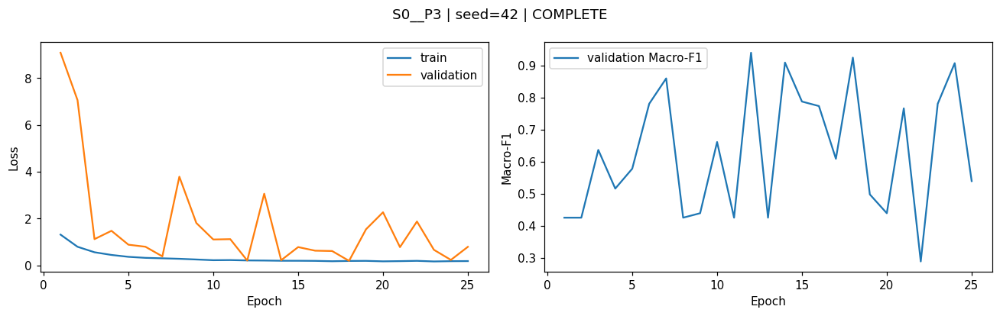

hybridgnet__crop__P1 | seed=42 | COMPLETE | history: 2026-11-16 15:19:36 UTC
epoch 1: train_loss=1.362403, val_loss=6.230163, val_macro_f1=0.426053
epoch 2: train_loss=0.899323, val_loss=8.035556, val_macro_f1=0.426053
epoch 3: train_loss=0.646357, val_loss=5.390062, val_macro_f1=0.426053
epoch 4: train_loss=0.548971, val_loss=0.803990, val_macro_f1=0.725115
epoch 5: train_loss=0.469979, val_loss=0.933034, val_macro_f1=0.762338
epoch 6: train_loss=0.391108, val_loss=1.877020, val_macro_f1=0.374781
epoch 7: train_loss=0.363633, val_loss=1.023128, val_macro_f1=0.608226
epoch 8: train_loss=0.325769, val_loss=1.374353, val_macro_f1=0.544678
epoch 9: train_loss=0.296273, val_loss=2.028341, val_macro_f1=0.486092
epoch 10: train_loss=0.281004, val_loss=0.392568, val_macro_f1=0.835992
epoch 11: train_loss=0.288461, val_loss=1.439090, val_macro_f1=0.498594
epoch 12: train_loss=0.254500, val_loss=1.813466, val_macro_f1=0.426053
epoch 13: train_loss=0.255059, val_loss=3.230423, val_macro_f1=0.426

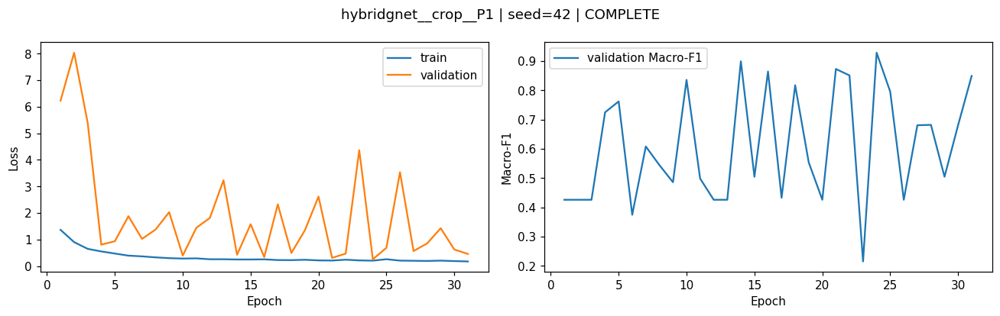

hybridgnet__crop__P2 | seed=42 | COMPLETE | history: 2026-11-16 16:55:17 UTC
epoch 1: train_loss=1.320208, val_loss=13.834516, val_macro_f1=0.426053
epoch 2: train_loss=0.795443, val_loss=4.506696, val_macro_f1=0.426053
epoch 3: train_loss=0.573523, val_loss=5.977521, val_macro_f1=0.426053
epoch 4: train_loss=0.454334, val_loss=0.569027, val_macro_f1=0.890997
epoch 5: train_loss=0.381522, val_loss=1.012645, val_macro_f1=0.613184
epoch 6: train_loss=0.326596, val_loss=0.733084, val_macro_f1=0.766956
epoch 7: train_loss=0.310530, val_loss=0.329930, val_macro_f1=0.880674
epoch 8: train_loss=0.294569, val_loss=1.881405, val_macro_f1=0.426053
epoch 9: train_loss=0.274794, val_loss=1.306140, val_macro_f1=0.498594
epoch 10: train_loss=0.247954, val_loss=0.359526, val_macro_f1=0.921207
epoch 11: train_loss=0.262749, val_loss=0.297625, val_macro_f1=0.871468
epoch 12: train_loss=0.233468, val_loss=0.524273, val_macro_f1=0.855510
epoch 13: train_loss=0.264698, val_loss=1.445541, val_macro_f1=0.42

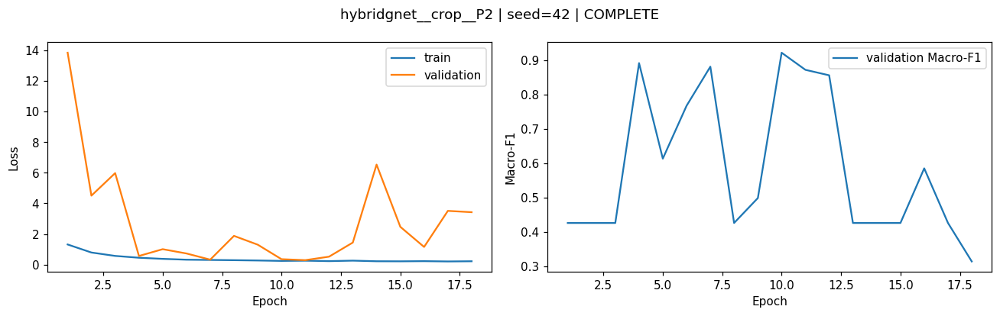

hybridgnet__crop__P3 | seed=42 | COMPLETE | history: 2026-11-16 18:45:47 UTC
epoch 1: train_loss=1.340422, val_loss=10.364446, val_macro_f1=0.426053
epoch 2: train_loss=0.836260, val_loss=1.061428, val_macro_f1=0.679486
epoch 3: train_loss=0.604458, val_loss=1.282244, val_macro_f1=0.431497
epoch 4: train_loss=0.510758, val_loss=0.532650, val_macro_f1=0.818167
epoch 5: train_loss=0.429157, val_loss=0.796563, val_macro_f1=0.735132
epoch 6: train_loss=0.375035, val_loss=1.114182, val_macro_f1=0.599619
epoch 7: train_loss=0.336422, val_loss=1.164235, val_macro_f1=0.589311
epoch 8: train_loss=0.319237, val_loss=0.420058, val_macro_f1=0.900699
epoch 9: train_loss=0.291454, val_loss=1.699939, val_macro_f1=0.486092
epoch 10: train_loss=0.274344, val_loss=0.420557, val_macro_f1=0.796966
epoch 11: train_loss=0.276726, val_loss=3.534578, val_macro_f1=0.426053
epoch 12: train_loss=0.243121, val_loss=1.135466, val_macro_f1=0.557093
epoch 13: train_loss=0.251099, val_loss=2.186984, val_macro_f1=0.42

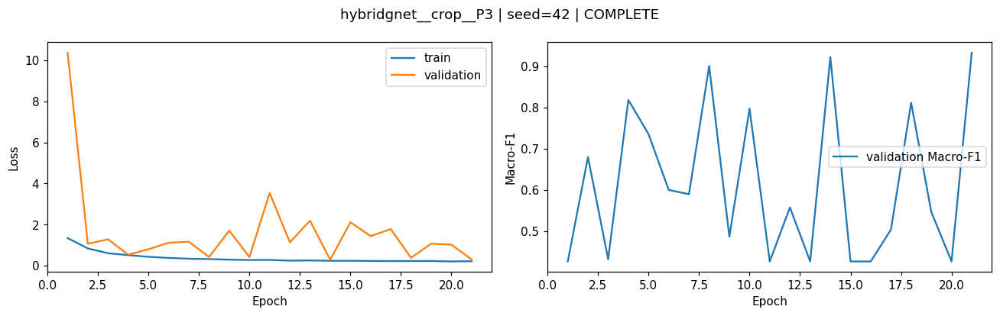

hybridgnet__mask__P1 | seed=42 | COMPLETE | history: 2026-11-16 20:33:32 UTC
epoch 1: train_loss=1.368447, val_loss=1.587913, val_macro_f1=0.426053
epoch 2: train_loss=0.830034, val_loss=1.350140, val_macro_f1=0.426053
epoch 3: train_loss=0.636198, val_loss=1.322543, val_macro_f1=0.426053
epoch 4: train_loss=0.557472, val_loss=0.971189, val_macro_f1=0.426053
epoch 5: train_loss=0.490227, val_loss=4.839751, val_macro_f1=0.426053
epoch 6: train_loss=0.426440, val_loss=1.776312, val_macro_f1=0.426053
epoch 7: train_loss=0.425791, val_loss=0.691566, val_macro_f1=0.649542
epoch 8: train_loss=0.360144, val_loss=0.536849, val_macro_f1=0.790750
epoch 9: train_loss=0.346577, val_loss=0.766725, val_macro_f1=0.572107
epoch 10: train_loss=0.332916, val_loss=2.284181, val_macro_f1=0.227688
epoch 11: train_loss=0.337259, val_loss=0.826346, val_macro_f1=0.545896
epoch 12: train_loss=0.304348, val_loss=0.620573, val_macro_f1=0.644924
epoch 13: train_loss=0.286382, val_loss=0.712590, val_macro_f1=0.619

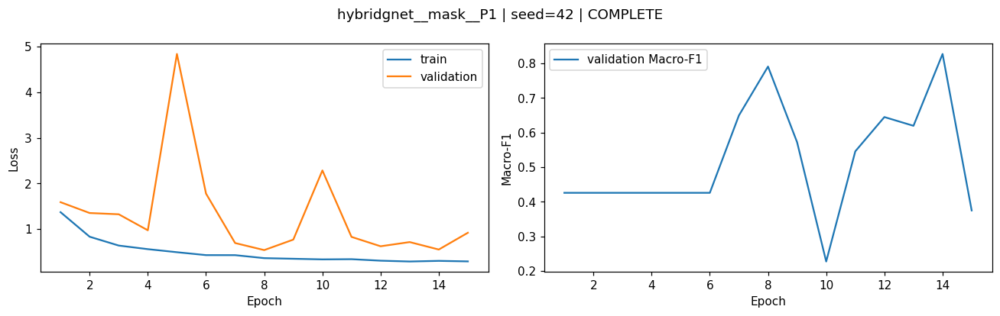

hybridgnet__mask__P2 | seed=42 | COMPLETE | history: 2026-11-16 22:09:55 UTC
epoch 1: train_loss=1.341567, val_loss=2.487412, val_macro_f1=0.426053
epoch 2: train_loss=0.766418, val_loss=1.285972, val_macro_f1=0.426053
epoch 3: train_loss=0.578759, val_loss=2.547156, val_macro_f1=0.426053
epoch 4: train_loss=0.485939, val_loss=5.028650, val_macro_f1=0.426053
epoch 5: train_loss=0.427341, val_loss=1.450576, val_macro_f1=0.426053
epoch 6: train_loss=0.378290, val_loss=0.939148, val_macro_f1=0.514678
epoch 7: train_loss=0.349794, val_loss=0.405298, val_macro_f1=0.845402
epoch 8: train_loss=0.342159, val_loss=0.831320, val_macro_f1=0.527509
epoch 9: train_loss=0.316409, val_loss=0.348100, val_macro_f1=0.831740
epoch 10: train_loss=0.296930, val_loss=0.476717, val_macro_f1=0.839042
epoch 11: train_loss=0.301403, val_loss=0.747367, val_macro_f1=0.610177
epoch 12: train_loss=0.284648, val_loss=0.729755, val_macro_f1=0.348452
epoch 13: train_loss=0.270453, val_loss=3.352429, val_macro_f1=0.426

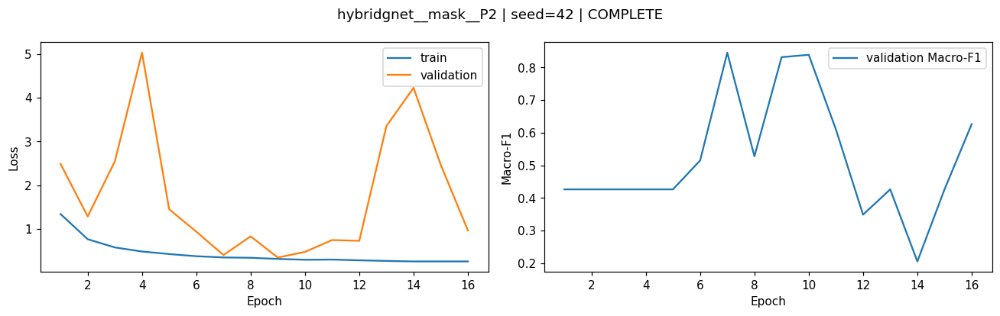

hybridgnet__mask__P3 | seed=42 | COMPLETE | history: 2026-11-17 00:07:04 UTC
epoch 1: train_loss=1.362692, val_loss=1.485969, val_macro_f1=0.426053
epoch 2: train_loss=0.791255, val_loss=1.147166, val_macro_f1=0.426053
epoch 3: train_loss=0.625638, val_loss=0.638272, val_macro_f1=0.810503
epoch 4: train_loss=0.513643, val_loss=0.573130, val_macro_f1=0.805238
epoch 5: train_loss=0.443938, val_loss=0.504227, val_macro_f1=0.835619
epoch 6: train_loss=0.404100, val_loss=0.493797, val_macro_f1=0.738937
epoch 7: train_loss=0.378642, val_loss=0.486923, val_macro_f1=0.883819
epoch 8: train_loss=0.347752, val_loss=0.631398, val_macro_f1=0.789759
epoch 9: train_loss=0.337044, val_loss=0.901162, val_macro_f1=0.701435
epoch 10: train_loss=0.309242, val_loss=6.047114, val_macro_f1=0.204885
epoch 11: train_loss=0.320749, val_loss=0.509677, val_macro_f1=0.690663
epoch 12: train_loss=0.298827, val_loss=0.581598, val_macro_f1=0.646836
epoch 13: train_loss=0.279938, val_loss=0.266098, val_macro_f1=0.925

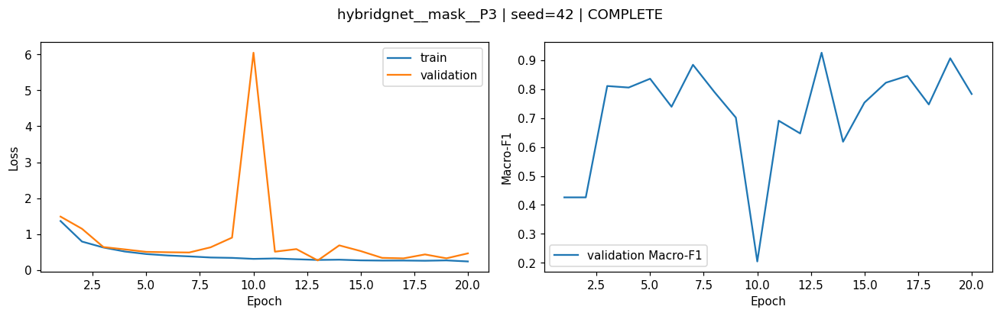

hybridgnet__crop_mask__P1 | seed=42 | COMPLETE | history: 2026-11-17 01:46:05 UTC
epoch 1: train_loss=1.371822, val_loss=1.606495, val_macro_f1=0.426053
epoch 2: train_loss=0.839950, val_loss=1.586097, val_macro_f1=0.426053
epoch 3: train_loss=0.614845, val_loss=2.734001, val_macro_f1=0.426053
epoch 4: train_loss=0.536054, val_loss=2.353733, val_macro_f1=0.426053
epoch 5: train_loss=0.455800, val_loss=2.644296, val_macro_f1=0.426053
epoch 6: train_loss=0.423992, val_loss=0.635982, val_macro_f1=0.797095
epoch 7: train_loss=0.375412, val_loss=0.951889, val_macro_f1=0.460201
epoch 8: train_loss=0.350115, val_loss=2.367023, val_macro_f1=0.426053
epoch 9: train_loss=0.348187, val_loss=1.401081, val_macro_f1=0.433050
epoch 10: train_loss=0.310502, val_loss=3.761219, val_macro_f1=0.279147
epoch 11: train_loss=0.323714, val_loss=5.382388, val_macro_f1=0.433050
epoch 12: train_loss=0.302617, val_loss=1.391848, val_macro_f1=0.506825
epoch 13: train_loss=0.284702, val_loss=2.076721, val_macro_f1=

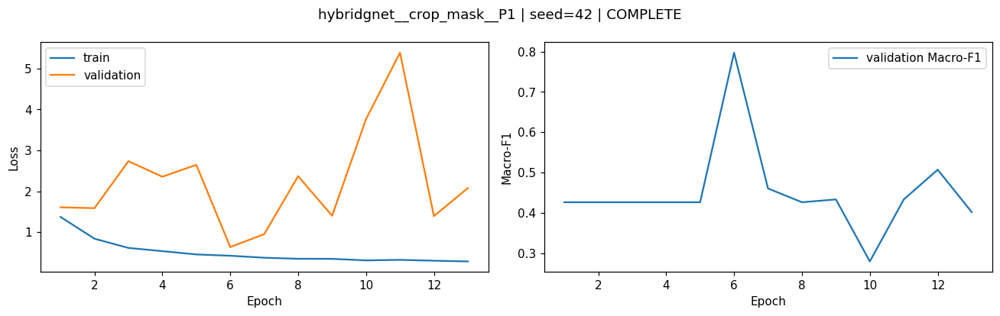

hybridgnet__crop_mask__P2 | seed=42 | COMPLETE | history: 2026-11-17 03:08:45 UTC
epoch 1: train_loss=1.375372, val_loss=3.078526, val_macro_f1=0.426053
epoch 2: train_loss=0.842924, val_loss=2.080568, val_macro_f1=0.426053
epoch 3: train_loss=0.641893, val_loss=1.660580, val_macro_f1=0.426053
epoch 4: train_loss=0.533757, val_loss=1.537767, val_macro_f1=0.426053
epoch 5: train_loss=0.447962, val_loss=0.642891, val_macro_f1=0.757679
epoch 6: train_loss=0.403882, val_loss=0.513402, val_macro_f1=0.855379
epoch 7: train_loss=0.374406, val_loss=0.463832, val_macro_f1=0.825706
epoch 8: train_loss=0.357770, val_loss=1.452533, val_macro_f1=0.207457
epoch 9: train_loss=0.338455, val_loss=0.368461, val_macro_f1=0.882544
epoch 10: train_loss=0.310267, val_loss=1.193038, val_macro_f1=0.254556
epoch 11: train_loss=0.308117, val_loss=0.496734, val_macro_f1=0.857666
epoch 12: train_loss=0.288723, val_loss=0.522563, val_macro_f1=0.865114
epoch 13: train_loss=0.271564, val_loss=0.417361, val_macro_f1=

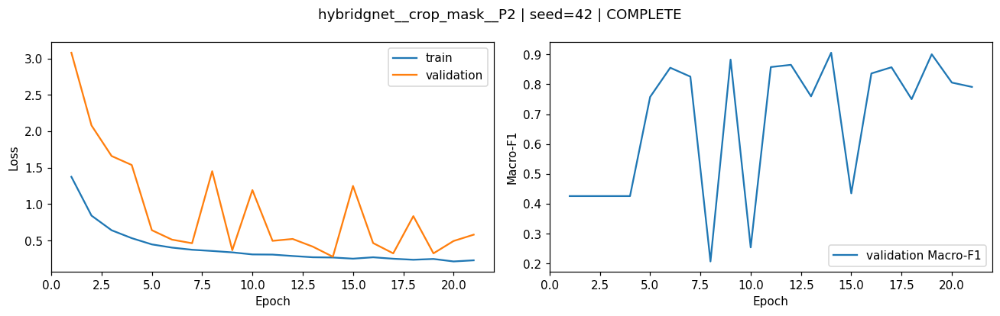

hybridgnet__crop_mask__P3 | seed=42 | COMPLETE | history: 2026-11-17 05:01:47 UTC
epoch 1: train_loss=1.374256, val_loss=7.870640, val_macro_f1=0.426053
epoch 2: train_loss=0.833915, val_loss=0.978389, val_macro_f1=0.587904
epoch 3: train_loss=0.644929, val_loss=0.583247, val_macro_f1=0.866889
epoch 4: train_loss=0.552445, val_loss=0.651807, val_macro_f1=0.787474
epoch 5: train_loss=0.479426, val_loss=0.744467, val_macro_f1=0.770397
epoch 6: train_loss=0.427196, val_loss=0.578173, val_macro_f1=0.690075
epoch 7: train_loss=0.402783, val_loss=0.424750, val_macro_f1=0.825988
epoch 8: train_loss=0.378839, val_loss=0.545306, val_macro_f1=0.696299
epoch 9: train_loss=0.361712, val_loss=0.837611, val_macro_f1=0.755232
epoch 10: train_loss=0.339537, val_loss=3.075966, val_macro_f1=0.204885
epoch 11: train_loss=0.340149, val_loss=0.317471, val_macro_f1=0.905056
epoch 12: train_loss=0.332300, val_loss=0.991411, val_macro_f1=0.369080
epoch 13: train_loss=0.300859, val_loss=0.297533, val_macro_f1=

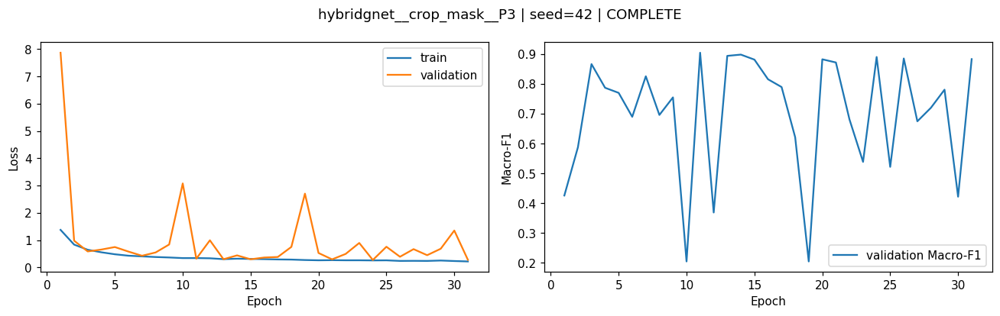

unet_resnet34__crop__P1 | seed=42 | COMPLETE | history: 2026-11-17 06:33:11 UTC
epoch 1: train_loss=1.347046, val_loss=7.559732, val_macro_f1=0.426053
epoch 2: train_loss=0.873103, val_loss=4.488331, val_macro_f1=0.426053
epoch 3: train_loss=0.629528, val_loss=4.724697, val_macro_f1=0.426053
epoch 4: train_loss=0.513964, val_loss=1.315787, val_macro_f1=0.492379
epoch 5: train_loss=0.451390, val_loss=1.432834, val_macro_f1=0.539016
epoch 6: train_loss=0.383247, val_loss=0.638313, val_macro_f1=0.799852
epoch 7: train_loss=0.351671, val_loss=1.617259, val_macro_f1=0.540208
epoch 8: train_loss=0.327163, val_loss=1.544314, val_macro_f1=0.479732
epoch 9: train_loss=0.307912, val_loss=1.860397, val_macro_f1=0.439961
epoch 10: train_loss=0.275181, val_loss=0.959233, val_macro_f1=0.599619
epoch 11: train_loss=0.291906, val_loss=0.919979, val_macro_f1=0.607840
epoch 12: train_loss=0.257858, val_loss=1.748043, val_macro_f1=0.439961
epoch 13: train_loss=0.258262, val_loss=2.710621, val_macro_f1=0.

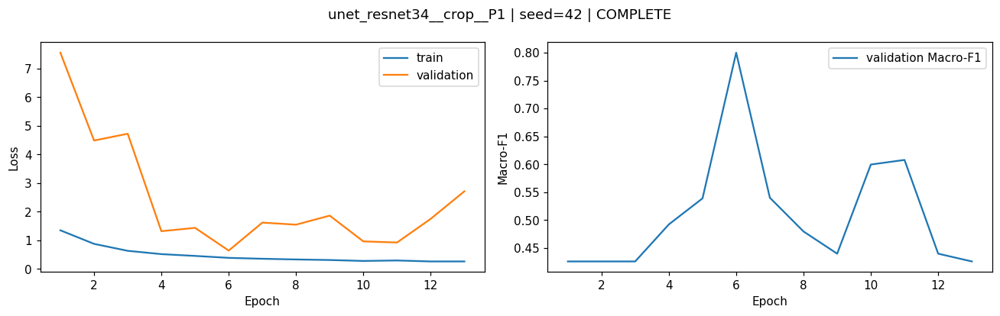

unet_resnet34__crop__P2 | seed=42 | COMPLETE | history: 2026-11-17 07:51:16 UTC
epoch 1: train_loss=1.329166, val_loss=3.032975, val_macro_f1=0.426053
epoch 2: train_loss=0.816140, val_loss=3.616274, val_macro_f1=0.426053
epoch 3: train_loss=0.570363, val_loss=4.573011, val_macro_f1=0.426053
epoch 4: train_loss=0.471758, val_loss=0.653809, val_macro_f1=0.795190
epoch 5: train_loss=0.397532, val_loss=1.511364, val_macro_f1=0.433050
epoch 6: train_loss=0.337143, val_loss=0.396081, val_macro_f1=0.907133
epoch 7: train_loss=0.327763, val_loss=0.329034, val_macro_f1=0.899504
epoch 8: train_loss=0.290641, val_loss=1.820468, val_macro_f1=0.426053
epoch 9: train_loss=0.269673, val_loss=0.313189, val_macro_f1=0.924570
epoch 10: train_loss=0.245782, val_loss=1.208426, val_macro_f1=0.619631
epoch 11: train_loss=0.253437, val_loss=2.578451, val_macro_f1=0.416360
epoch 12: train_loss=0.236793, val_loss=0.708686, val_macro_f1=0.759645
epoch 13: train_loss=0.231418, val_loss=0.577009, val_macro_f1=0.

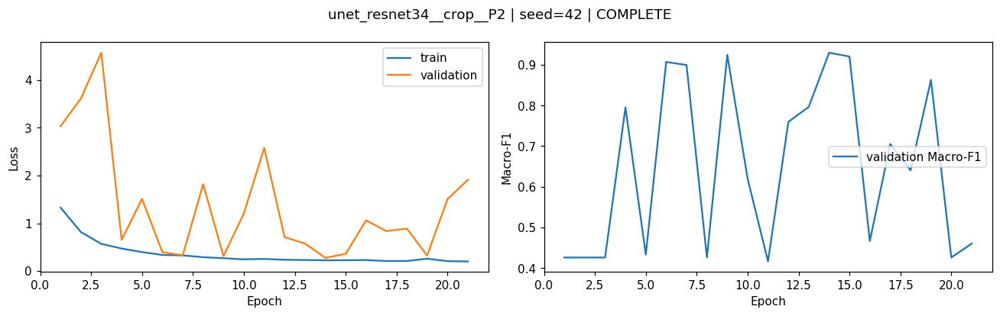

unet_resnet34__crop__P3 | seed=42 | COMPLETE | history: 2026-11-17 09:19:02 UTC
epoch 1: train_loss=1.351099, val_loss=9.305431, val_macro_f1=0.426053
epoch 2: train_loss=0.828566, val_loss=4.249852, val_macro_f1=0.426053
epoch 3: train_loss=0.585188, val_loss=3.172505, val_macro_f1=0.426053
epoch 4: train_loss=0.491081, val_loss=1.589699, val_macro_f1=0.536651
epoch 5: train_loss=0.419207, val_loss=2.776328, val_macro_f1=0.426053
epoch 6: train_loss=0.355809, val_loss=0.952272, val_macro_f1=0.632930
epoch 7: train_loss=0.339423, val_loss=1.390197, val_macro_f1=0.528644
epoch 8: train_loss=0.302240, val_loss=3.209620, val_macro_f1=0.426053
epoch 9: train_loss=0.289435, val_loss=0.761484, val_macro_f1=0.786207
epoch 10: train_loss=0.268697, val_loss=0.640717, val_macro_f1=0.775709
epoch 11: train_loss=0.257854, val_loss=1.707857, val_macro_f1=0.439961
epoch 12: train_loss=0.244581, val_loss=0.284402, val_macro_f1=0.928479
epoch 13: train_loss=0.251119, val_loss=0.635051, val_macro_f1=0.

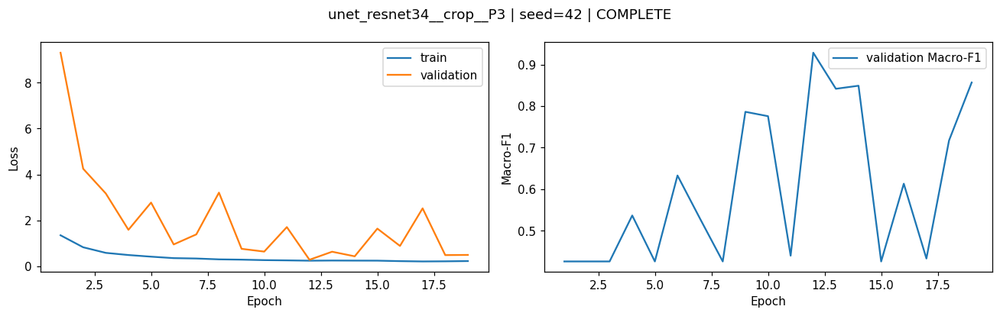

unet_resnet34__mask__P1 | seed=42 | COMPLETE | history: 2026-11-17 12:07:37 UTC
epoch 1: train_loss=1.353782, val_loss=1.483554, val_macro_f1=0.426053
epoch 2: train_loss=0.763748, val_loss=1.234612, val_macro_f1=0.426053
epoch 3: train_loss=0.551432, val_loss=1.006824, val_macro_f1=0.419227
epoch 4: train_loss=0.479973, val_loss=1.541794, val_macro_f1=0.426053
epoch 5: train_loss=0.420943, val_loss=0.804708, val_macro_f1=0.656394
epoch 6: train_loss=0.372678, val_loss=0.525370, val_macro_f1=0.840361
epoch 7: train_loss=0.350382, val_loss=0.503177, val_macro_f1=0.786172
epoch 8: train_loss=0.339146, val_loss=2.395955, val_macro_f1=0.453535
epoch 9: train_loss=0.322556, val_loss=8.339912, val_macro_f1=0.204885
epoch 10: train_loss=0.273754, val_loss=9.554759, val_macro_f1=0.204885
epoch 11: train_loss=0.292419, val_loss=0.876412, val_macro_f1=0.459138
epoch 12: train_loss=0.277605, val_loss=0.992560, val_macro_f1=0.397473
epoch 13: train_loss=0.262707, val_loss=0.416901, val_macro_f1=0.

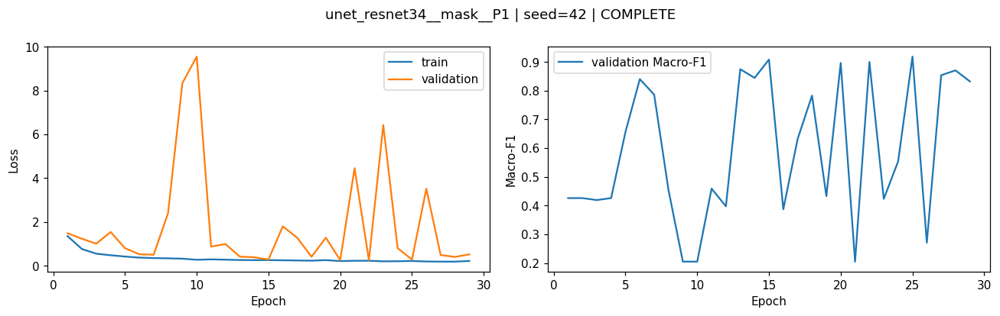

unet_resnet34__mask__P2 | seed=42 | COMPLETE | history: 2026-11-17 12:54:46 UTC
epoch 1: train_loss=1.305992, val_loss=1.753426, val_macro_f1=0.426053
epoch 2: train_loss=0.737610, val_loss=1.536702, val_macro_f1=0.426053
epoch 3: train_loss=0.530557, val_loss=1.978851, val_macro_f1=0.426053
epoch 4: train_loss=0.459953, val_loss=1.205548, val_macro_f1=0.453535
epoch 5: train_loss=0.390753, val_loss=0.745211, val_macro_f1=0.468154
epoch 6: train_loss=0.348025, val_loss=0.351662, val_macro_f1=0.893378
epoch 7: train_loss=0.326577, val_loss=1.100783, val_macro_f1=0.426053
epoch 8: train_loss=0.310098, val_loss=1.387738, val_macro_f1=0.486092
epoch 9: train_loss=0.301067, val_loss=0.421092, val_macro_f1=0.895317
epoch 10: train_loss=0.277453, val_loss=8.098834, val_macro_f1=0.204885
epoch 11: train_loss=0.285900, val_loss=1.360458, val_macro_f1=0.204885
epoch 12: train_loss=0.257841, val_loss=1.207468, val_macro_f1=0.664730
epoch 13: train_loss=0.256091, val_loss=0.371488, val_macro_f1=0.

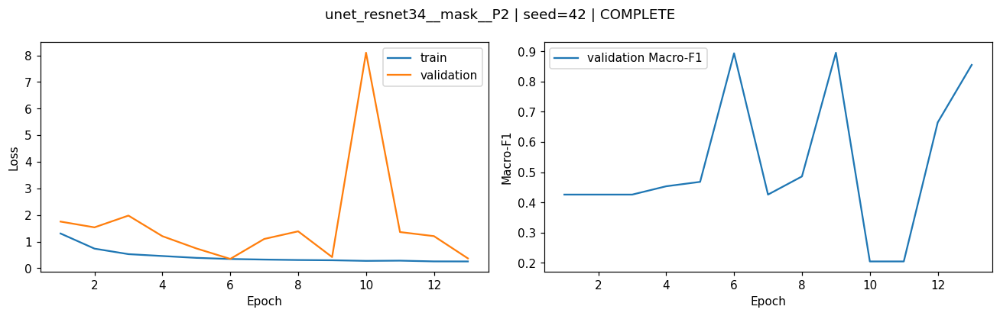

unet_resnet34__mask__P3 | seed=42 | COMPLETE | history: 2026-11-17 14:01:14 UTC
epoch 1: train_loss=1.330482, val_loss=2.085957, val_macro_f1=0.426053
epoch 2: train_loss=0.740999, val_loss=1.584813, val_macro_f1=0.426053
epoch 3: train_loss=0.559992, val_loss=1.370822, val_macro_f1=0.426053
epoch 4: train_loss=0.462803, val_loss=2.174290, val_macro_f1=0.204885
epoch 5: train_loss=0.399197, val_loss=0.673686, val_macro_f1=0.757426
epoch 6: train_loss=0.359321, val_loss=1.082962, val_macro_f1=0.626211
epoch 7: train_loss=0.345658, val_loss=0.584537, val_macro_f1=0.849565
epoch 8: train_loss=0.322638, val_loss=2.781382, val_macro_f1=0.426053
epoch 9: train_loss=0.318311, val_loss=4.352228, val_macro_f1=0.204885
epoch 10: train_loss=0.290858, val_loss=1.915465, val_macro_f1=0.426053
epoch 11: train_loss=0.292616, val_loss=6.089819, val_macro_f1=0.204885
epoch 12: train_loss=0.280265, val_loss=6.441886, val_macro_f1=0.204885
epoch 13: train_loss=0.269986, val_loss=0.324515, val_macro_f1=0.

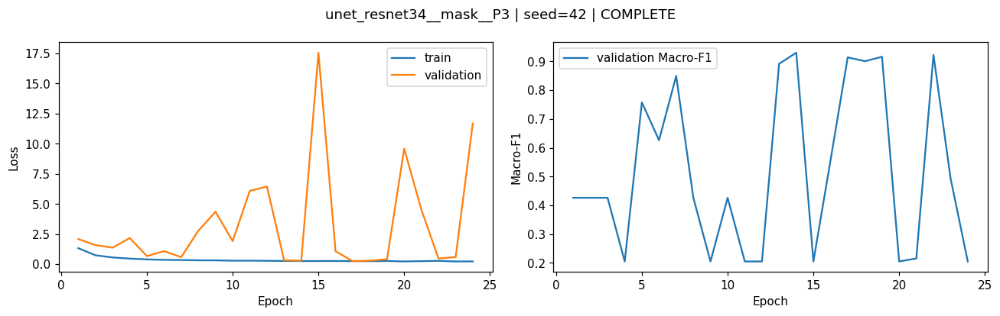

unet_resnet34__crop_mask__P1 | seed=42 | COMPLETE | history: 2026-11-17 15:42:12 UTC
epoch 1: train_loss=1.386225, val_loss=1.645410, val_macro_f1=0.426053
epoch 2: train_loss=0.775526, val_loss=1.206831, val_macro_f1=0.426053
epoch 3: train_loss=0.585557, val_loss=1.231372, val_macro_f1=0.426053
epoch 4: train_loss=0.505582, val_loss=1.275139, val_macro_f1=0.426053
epoch 5: train_loss=0.424975, val_loss=2.733287, val_macro_f1=0.426053
epoch 6: train_loss=0.386631, val_loss=13.440060, val_macro_f1=0.204885
epoch 7: train_loss=0.395255, val_loss=1.666654, val_macro_f1=0.426053
epoch 8: train_loss=0.357481, val_loss=11.597637, val_macro_f1=0.426053
epoch 9: train_loss=0.335179, val_loss=0.460520, val_macro_f1=0.884022
epoch 10: train_loss=0.296245, val_loss=1.431511, val_macro_f1=0.285001
epoch 11: train_loss=0.306331, val_loss=0.662697, val_macro_f1=0.771298
epoch 12: train_loss=0.284751, val_loss=0.601239, val_macro_f1=0.677758
epoch 13: train_loss=0.269065, val_loss=0.308289, val_macr

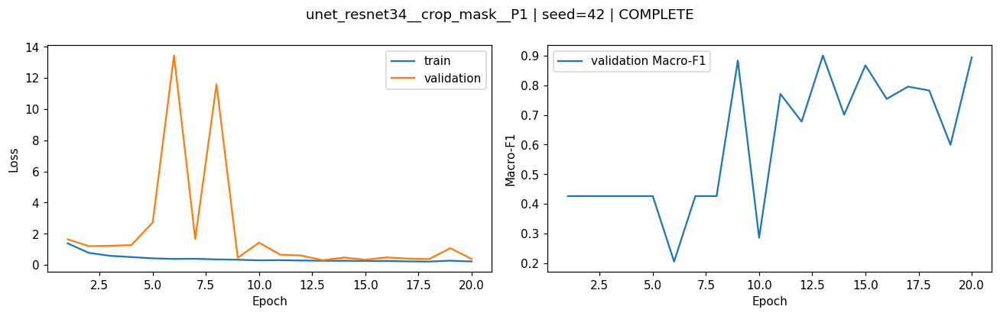

unet_resnet34__crop_mask__P2 | seed=42 | COMPLETE | history: 2026-11-17 16:26:05 UTC
epoch 1: train_loss=1.297010, val_loss=2.350427, val_macro_f1=0.426053
epoch 2: train_loss=0.707784, val_loss=7.630381, val_macro_f1=0.426053
epoch 3: train_loss=0.523147, val_loss=5.469558, val_macro_f1=0.426053
epoch 4: train_loss=0.454349, val_loss=8.932888, val_macro_f1=0.204885
epoch 5: train_loss=0.410598, val_loss=1.592604, val_macro_f1=0.426053
epoch 6: train_loss=0.349584, val_loss=0.367375, val_macro_f1=0.855629
epoch 7: train_loss=0.331428, val_loss=0.863138, val_macro_f1=0.618095
epoch 8: train_loss=0.301629, val_loss=4.802323, val_macro_f1=0.426053
epoch 9: train_loss=0.301931, val_loss=1.411600, val_macro_f1=0.397018
epoch 10: train_loss=0.272224, val_loss=0.567318, val_macro_f1=0.589731
epoch 11: train_loss=0.283482, val_loss=11.418639, val_macro_f1=0.204885
epoch 12: train_loss=0.271635, val_loss=5.194335, val_macro_f1=0.426053
epoch 13: train_loss=0.258358, val_loss=0.448183, val_macro

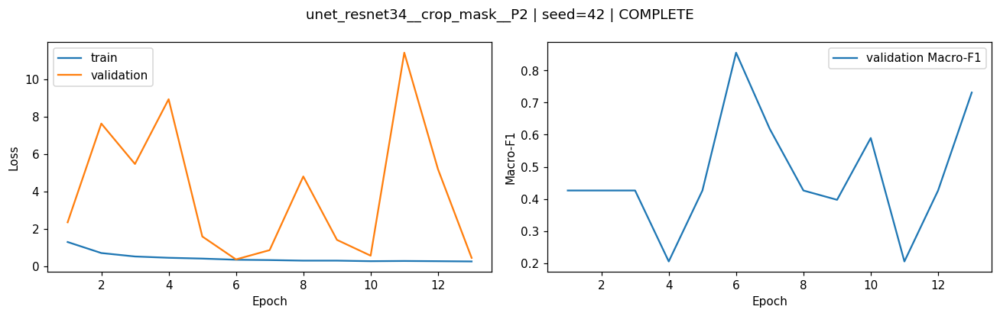

unet_resnet34__crop_mask__P3 | seed=42 | COMPLETE | history: 2026-11-17 17:23:34 UTC
epoch 1: train_loss=1.321282, val_loss=2.552541, val_macro_f1=0.426053
epoch 2: train_loss=0.741559, val_loss=3.028510, val_macro_f1=0.426053
epoch 3: train_loss=0.564578, val_loss=4.970925, val_macro_f1=0.426053
epoch 4: train_loss=0.489616, val_loss=1.459099, val_macro_f1=0.426053
epoch 5: train_loss=0.413540, val_loss=0.529439, val_macro_f1=0.872040
epoch 6: train_loss=0.367668, val_loss=1.152499, val_macro_f1=0.509771
epoch 7: train_loss=0.383959, val_loss=0.903150, val_macro_f1=0.551524
epoch 8: train_loss=0.340161, val_loss=0.738979, val_macro_f1=0.669162
epoch 9: train_loss=0.322723, val_loss=0.321368, val_macro_f1=0.898382
epoch 10: train_loss=0.296544, val_loss=5.380735, val_macro_f1=0.426053
epoch 11: train_loss=0.294768, val_loss=0.281555, val_macro_f1=0.926557
epoch 12: train_loss=0.279799, val_loss=0.416483, val_macro_f1=0.886018
epoch 13: train_loss=0.270919, val_loss=0.382035, val_macro_

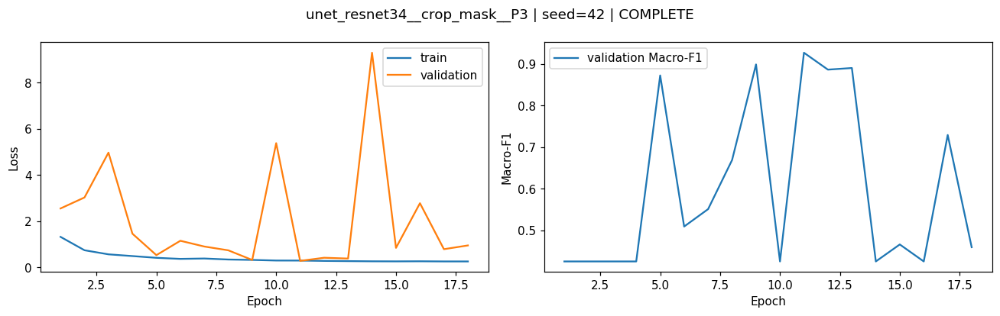

In [ ]:
def training_suite(mode=MODELING_RUN_MODE):
    configure_pytorch(SEED)
    selected = (SELECTED_EXPERIMENT_IDS or ('S0__P1', 'hybridgnet__crop__P2', 'unet_resnet34__crop_mask__P3')) if mode == 'smoke' else (
        SELECTED_EXPERIMENT_IDS or tuple(e['id'] for e in EXPERIMENTS)
    )
    assert selected and all(e in EXP_BY_ID for e in selected)
    all_records = []
    for seed in SEEDS:
        for exp_id in selected:
            print(f'RUN {mode}: {exp_id} | seed {seed}', flush=True)
            info = run_one(EXP_BY_ID[exp_id], seed, mode)
            all_records.append(info)
            rows = []
            for x in all_records:
                row = dict(experiment_id=x['experiment_id'], seed=x['seed'],
                           mode=x['mode'], segmenter=x['segmenter'],
                           method=x['method'], pipeline=x['pipeline'],
                           best_epoch=x['best_epoch'], val_loss=x['val_loss'],
                           test_evaluated=bool(x.get('test_evaluated', False)),
                           initial_weight_sha256=x['initial_weight_sha256'])
                row.update({f'val_{key}': value for key, value in x['val_metrics'].items()})
                if x.get('train_metrics'):
                    row.update({f'train_{key}': value for key, value in x['train_metrics'].items()})
                if x.get('test_metrics'):
                    row.update({f'test_{key}': value for key, value in x['test_metrics'].items()})
                    row['val_minus_test_macro_f1'] = x['val_metrics']['macro_f1'] - x['test_metrics']['macro_f1']
                rows.append(row)
            pd.DataFrame(rows).to_csv(OUTPUT_ROOT / f'{mode}_summary.csv', index=False)
    result = pd.DataFrame(rows)
    init_hashes = result.groupby('seed').initial_weight_sha256.nunique()
    print('Finished:', len(result), 'runs | unique initialization hashes per seed:')
    display(init_hashes.to_frame('unique_init_hashes'))
    assert (init_hashes == 1).all(), 'Init bobot berbeda pada seed yang sama'
    if mode == 'full':
        print(f'Full test evaluated: {result.test_evaluated.sum()}/{len(result)} runs')
        display(result.sort_values('val_macro_f1', ascending=False))
    return result

training_summary = None
if RUN_TRAINING:
    training_summary = training_suite()
    if MODELING_RUN_MODE == 'smoke':
        print('SMOKE PASS: checkpoint smoke & validation. Test split TIDAK dibaca.')
else:
    print('Training OFF; hasil tersimpan tetap bisa dibaca di Cell 10/11.')


## 10. Perbandingan validation–test dan efek segmentasi

Tabel disusun dari **checkpoint terbaik masing-masing run** (21 kombinasi × seed), bukan satu checkpoint bersama. `validation_ranking.csv` tetap diurutkan berdasarkan validation Macro-F1, sementara `val_test_comparison.csv` memperlihatkan Macro-F1 test dan generalization gap untuk *semua run yang memiliki hasil test*. Test semua ablasi adalah analisis deskriptif; tidak dijadikan dasar memilih epoch atau konfigurasi untuk klaim performa final independen.


In [ ]:
def collect_full_results():
    records = []
    for seed in SEEDS:
        for exp in EXPERIMENTS:
            run_dir = result_directory(exp['id'], seed, 'full')
            file = run_dir / 'result.json'
            if not file.is_file():
                continue
            info = saved_metadata_matches(run_dir, exp, seed, 'full')
            row = {**exp, 'seed': seed, 'best_epoch': info['best_epoch'],
                   'val_loss': info['val_loss'],
                   'test_evaluated': bool(info.get('test_evaluated', False)),
                   'checkpoint': str(run_dir / 'best.pt'),
                   **{f'val_{key}': value for key, value in info['val_metrics'].items()}}
            if info.get('train_metrics'):
                row.update({f'train_{key}': value for key, value in info['train_metrics'].items()})
            if info.get('test_metrics'):
                row.update({f'test_{key}': value for key, value in info['test_metrics'].items()})
                row['val_minus_test_macro_f1'] = info['val_metrics']['macro_f1'] - info['test_metrics']['macro_f1']
            records.append(row)
    return pd.DataFrame(records)


def show_validation_and_test_comparison():
    all_full = collect_full_results()
    if all_full.empty:
        print('Belum ada full training selesai.')
        return all_full
    val_ranking = all_full.groupby('id', as_index=False).agg(
        macro_f1_mean=('val_macro_f1', 'mean'), macro_f1_std=('val_macro_f1', 'std'),
        recall_normal_mean=('val_recall_normal', 'mean'),
        recall_pneumonia_mean=('val_recall_pneumonia', 'mean'),
        auc_mean=('val_roc_auc', 'mean'), n_seeds=('seed', 'nunique')
    ).sort_values('macro_f1_mean', ascending=False)
    val_ranking.to_csv(OUTPUT_ROOT / 'validation_ranking.csv', index=False)
    print('VALIDATION RANKING (not test ranking):')
    display(val_ranking)
    joined = all_full.sort_values('val_macro_f1', ascending=False)
    joined.to_csv(OUTPUT_ROOT / 'val_test_comparison.csv', index=False)
    print(f'Comparison: {int(joined.test_evaluated.sum())}/{len(joined)} test results available')
    cols = ['id', 'seed', 'segmenter', 'method', 'pipeline', 'best_epoch',
            'val_macro_f1', 'test_macro_f1', 'val_minus_test_macro_f1',
            'val_recall_normal', 'test_recall_normal',
            'val_recall_pneumonia', 'test_recall_pneumonia',
            'val_roc_auc', 'test_roc_auc']
    display(joined.reindex(columns=cols))
    if len(joined) == len(EXPERIMENTS) * len(SEEDS) and joined.test_evaluated.all():
        pivot = joined.pivot(index='seed', columns='id', values='val_macro_f1')
        comparisons = []
        for seg in SEGMENTERS:
            for method in METHODS:
                for p in PREPROCESS_PIPELINES:
                    key = f'{seg}__{method}__{p}'
                    diff = pivot[key] - pivot[f'S0__{p}']
                    comparisons.append(dict(experiment=key, vs_control=f'S0__{p}',
                                            delta_val_macro_f1_mean=diff.mean(),
                                            delta_std=diff.std()))
        pd.DataFrame(comparisons).to_csv(OUTPUT_ROOT / 'paired_delta_vs_no_segmentation.csv', index=False)
    return joined

all_full = show_validation_and_test_comparison()


SNAPSHOT FILE HASIL — 2026-11-18 04:54:32 UTC
Dibaca dari disk tanpa menjalankan ulang sel atau training.
Validation dari result.json konfigurasi yang sudah selesai.


experiment,seed,best_epoch,accuracy,precision_pneumonia,recall_pneumonia,f1_pneumonia,precision_normal,recall_normal,f1_normal,macro_f1,roc_auc,pr_auc,samples,threshold
hybridgnet__mask__P1,42,8,0.812287,0.979351,0.763218,0.857881,0.582996,0.953642,0.723618,0.790750,0.941082,0.980346,586,0.5
hybridgnet__crop_mask__P1,42,6,0.870307,0.856859,0.990805,0.918977,0.951807,0.523179,0.675214,0.797095,0.963127,0.986515,586,0.5
unet_resnet34__crop__P3,42,12,0.947099,0.948889,0.981609,0.964972,0.941176,0.847682,0.891986,0.928479,0.989374,0.996321,586,0.5
hybridgnet__crop__P1,42,24,0.945392,0.965358,0.960920,0.963134,0.888889,0.900662,0.894737,0.928935,0.987531,0.995630,586,0.5
S0__P3,42,18,0.938567,1.000000,0.917241,0.956835,0.807487,1.000000,0.893491,0.925163,0.996148,0.998666,586,0.5
unet_resnet34__crop_mask__P2,42,6,0.875427,0.991848,0.839080,0.909091,0.678899,0.980132,0.802168,0.855629,0.975230,0.991813,586,0.5
unet_resnet34__mask__P3,42,17,0.931741,0.973621,0.933333,0.953052,0.828402,0.927152,0.875000,0.914026,0.983771,0.994592,586,0.5
unet_resnet34__crop__P2,42,14,0.947099,0.957014,0.972414,0.964652,0.916667,0.874172,0.894915,0.929784,0.984745,0.994257,586,0.5
unet_resnet34__mask__P2,42,6,0.911263,0.989770,0.889655,0.937046,0.753846,0.973510,0.849711,0.893378,0.973647,0.991048,586,0.5
unet_resnet34__mask__P1,42,22,0.919795,0.970874,0.919540,0.944510,0.798851,0.920530,0.855385,0.899947,0.981716,0.993530,586,0.5


Peringkat berdasarkan validation, bukan test


id,macro_f1_mean,macro_f1_std,recall_normal_mean,recall_pneumonia_mean,auc_mean,n_seeds
S0__P1,0.932158,NaN,0.927152,0.954023,0.991398,1
unet_resnet34__crop__P2,0.929784,NaN,0.874172,0.972414,0.984745,1
hybridgnet__crop__P1,0.928935,NaN,0.900662,0.960920,0.987531,1
unet_resnet34__crop__P3,0.928479,NaN,0.847682,0.981609,0.989374,1
S0__P2,0.928295,NaN,0.980132,0.928736,0.995844,1
unet_resnet34__crop_mask__P3,0.926557,NaN,0.894040,0.960920,0.982233,1
hybridgnet__mask__P3,0.925440,NaN,0.913907,0.951724,0.988049,1
S0__P3,0.925163,NaN,1.000000,0.917241,0.996148,1
hybridgnet__crop__P3,0.922106,NaN,0.887417,0.958621,0.983147,1
unet_resnet34__mask__P3,0.914026,NaN,0.927152,0.933333,0.983771,1


Perbandingan validation dan test


id,segmenter,method,variant,pipeline,seed,best_epoch,val_loss,test_evaluated,checkpoint,val_accuracy,val_precision_pneumonia,val_recall_pneumonia,val_f1_pneumonia,val_precision_normal,val_recall_normal,val_f1_normal,val_macro_f1,val_roc_auc,val_pr_auc,val_samples,val_threshold,train_accuracy,train_precision_pneumonia,train_recall_pneumonia,train_f1_pneumonia,train_precision_normal,train_recall_normal,train_f1_normal,train_macro_f1,train_roc_auc,train_pr_auc,train_samples,train_threshold,test_accuracy,test_precision_pneumonia,test_recall_pneumonia,test_f1_pneumonia,test_precision_normal,test_recall_normal,test_f1_normal,test_macro_f1,test_roc_auc,test_pr_auc,test_samples,test_threshold,val_minus_test_macro_f1
S0__P1,none,original,original,P1,42,13,0.227387,True,/home/arsyadmuhammad/AI Project/Pneumonia/output_pneunet_e5_segmentation_3level/runs/full/S0__P1__seed_42/best.pt,0.947099,0.974178,0.954023,0.963995,0.875000,0.927152,0.900322,0.932158,0.991398,0.996996,586,0.5,0.966207,0.986403,0.967807,0.977017,0.912114,0.961603,0.936205,0.956611,0.995228,0.998323,4646,0.5,0.916667,0.887615,0.992308,0.937046,0.984043,0.790598,0.876777,0.906912,0.979706,0.986752,624,0.5,0.025247
unet_resnet34__crop__P2,unet_resnet34,crop,unet_resnet34__crop,P2,42,14,0.275934,True,/home/arsyadmuhammad/AI Project/Pneumonia/output_pneunet_e5_segmentation_3level/runs/full/unet_resnet34__crop__P2__seed_42/best.pt,0.947099,0.957014,0.972414,0.964652,0.916667,0.874172,0.894915,0.929784,0.984745,0.994257,586,0.5,0.964486,0.974559,0.977668,0.976111,0.935131,0.926544,0.930818,0.953464,0.993283,0.997612,4646,0.5,0.850962,0.812632,0.989744,0.892486,0.973154,0.619658,0.757180,0.824833,0.954361,0.965442,624,0.5,0.104951
hybridgnet__crop__P1,hybridgnet,crop,hybridgnet__crop,P1,42,24,0.253064,True,/home/arsyadmuhammad/AI Project/Pneumonia/output_pneunet_e5_segmentation_3level/runs/full/hybridgnet__crop__P1__seed_42/best.pt,0.945392,0.965358,0.960920,0.963134,0.888889,0.900662,0.894737,0.928935,0.987531,0.995630,586,0.5,0.963625,0.985203,0.965487,0.975245,0.906077,0.958264,0.931440,0.953343,0.994059,0.997963,4646,0.5,0.927885,0.900232,0.994872,0.945189,0.989637,0.816239,0.894614,0.919901,0.978720,0.983938,624,0.5,0.009034
unet_resnet34__crop__P3,unet_resnet34,crop,unet_resnet34__crop,P3,42,12,0.284402,True,/home/arsyadmuhammad/AI Project/Pneumonia/output_pneunet_e5_segmentation_3level/runs/full/unet_resnet34__crop__P3__seed_42/best.pt,0.947099,0.948889,0.981609,0.964972,0.941176,0.847682,0.891986,0.928479,0.989374,0.996321,586,0.5,0.964055,0.966980,0.985209,0.976009,0.954987,0.903172,0.928357,0.952183,0.994361,0.998062,4646,0.5,0.866987,0.825902,0.997436,0.903600,0.993464,0.649573,0.785530,0.844565,0.977570,0.985621,624,0.5,0.083914
S0__P2,none,original,original,P2,42,8,0.220615,True,/home/arsyadmuhammad/AI Project/Pneumonia/output_pneunet_e5_segmentation_3level/runs/full/S0__P2__seed_42/best.pt,0.941980,0.992629,0.928736,0.959620,0.826816,0.980132,0.896970,0.928295,0.995844,0.998549,586,0.5,0.959750,0.996952,0.948666,0.972210,0.870330,0.991653,0.927039,0.949624,0.996940,0.998955,4646,0.5,0.927885,0.913669,0.976923,0.944238,0.956522,0.846154,0.897959,0.921099,0.975356,0.983851,624,0.5,0.007196
unet_resnet34__crop_mask__P3,unet_resnet34,crop_mask,unet_resnet34__crop_mask,P3,42,11,0.281555,True,/home/arsyadmuhammad/AI Project/Pneumonia/output_pneunet_e5_segmentation_3level/runs/full/unet_resnet34__crop_mask__P3__seed_42/best.pt,0.943686,0.963134,0.960920,0.962025,0.888158,0.894040,0.891089,0.926557,0.982233,0.993932,586,0.5,0.945545,0.963178,0.963457,0.963317,0.894737,0.893990,0.894363,0.928840,0.983299,0.994220,4646,0.5,0.927885,0.911695,0.979487,0.944376,0.960976,0.841880,0.897494,0.920935,0.988812,0.993431,624,0.5,0.005622
hybridgnet__mask__P3,hybridgnet,mask,hybridgnet__mask,P3,42,13,0.266098,True,/home/arsyadmuhammad/AI Project/Pneumonia/output_pneunet_e5_segmentation_3level/runs/full/hybridgnet__mask__P3__seed_42/best.pt,0.941980,0.969555,0.951724,0.960557,0.867925

Selisih terhadap kontrol tanpa segmentasi


experiment,vs_control,delta_val_macro_f1_mean,delta_std
hybridgnet__crop__P1,S0__P1,-0.003223,NaN
hybridgnet__crop__P2,S0__P2,-0.056827,NaN
hybridgnet__crop__P3,S0__P3,-0.003057,NaN
hybridgnet__mask__P1,S0__P1,-0.141409,NaN
hybridgnet__mask__P2,S0__P2,-0.096555,NaN
hybridgnet__mask__P3,S0__P3,0.000277,NaN
hybridgnet__crop_mask__P1,S0__P1,-0.135063,NaN
hybridgnet__crop_mask__P2,S0__P2,-0.022680,NaN
hybridgnet__crop_mask__P3,S0__P3,-0.034428,NaN
unet_resnet34__crop__P1,S0__P1,-0.132306,NaN


## 11. Test seluruh ablasi — otomatis saat training, atau backfill dari checkpoint masing-masing

Untuk `RUN_TRAINING=True`, `MODELING_RUN_MODE='full'` dan `EVALUATE_TEST_AFTER_EACH_FULL_RUN=True`, setiap kondisi E5 **langsung melakukan evaluasi test dari best checkpoint miliknya sendiri** setelah training. Cell ini mengumpulkan seluruh hasil tersebut menjadi `final_test_summary.csv` dan `full_summary.csv`.

`RUN_FINAL_TEST=True` hanya diperlukan untuk **backfill/evaluasi terpisah** apabila suatu run full sebelumnya belum mempunyai test; yang sudah dievaluasi tidak dihitung ulang. `FINAL_TEST_EXPERIMENT_IDS=()` berarti semua ID (21). Semua seed pada `SEEDS` diproses. Ini tetap ablation 21 model E5, bukan satu baseline E5.


In [ ]:
# ============================================================
# 11. TEST RESULTS — ALL 21 ABLATIONS x ALL SEEDS
# Setiap best.pt adalah checkpoint UNIK untuk experiment_id + seed.
# Test dilakukan langsung di run_one() setelah full training.
# ============================================================

def final_test(exp_id, seed=FINAL_TEST_SEED, force=False):
    """Backfill test pada checkpoint sendiri, tidak memakai baseline lain."""
    if exp_id not in EXP_BY_ID:
        raise ValueError(f'Experiment ID tidak ditemukan: {exp_id}')
    return evaluate_saved_full_run(exp_id, seed, force=force)


# Empty selection means all 21 configurations.
test_selection = tuple(FINAL_TEST_EXPERIMENT_IDS) or tuple(e['id'] for e in EXPERIMENTS)
assert len(set(test_selection)) == len(test_selection)
assert all(exp_id in EXP_BY_ID for exp_id in test_selection)

if RUN_FINAL_TEST:
    if RUN_TRAINING and MODELING_RUN_MODE == 'smoke':
        print('RUN_FINAL_TEST diabaikan pada SMOKE. Test split tidak digunakan saat smoke.')
    else:
        configure_pytorch(SEED)
        for seed in SEEDS:
            for idx, exp_id in enumerate(test_selection, start=1):
                print(f'[BACKFILL TEST {idx}/{len(test_selection)}] {exp_id} seed={seed}', flush=True)
                final_test(exp_id, seed)


def collect_all_test_results():
    rows = []
    for seed in SEEDS:
        for exp in EXPERIMENTS:
            out = result_directory(exp['id'], seed, 'full')
            path = out / 'result.json'
            if not path.is_file():
                continue
            info = saved_metadata_matches(out, exp, seed, 'full')
            if not info.get('test_evaluated'):
                continue
            if not test_artifacts_complete(out):
                raise RuntimeError(f'Missing test artifacts in {out}')
            metrics = info['test_metrics']
            row = {**exp, 'seed': seed, 'best_epoch': info['best_epoch'],
                   'checkpoint': str(out / 'best.pt'),
                   'val_macro_f1': info['val_metrics']['macro_f1'],
                   'val_loss': info['val_loss'],
                   'test_loss': info.get('test_loss'),
                   **{f'test_{key}': value for key, value in metrics.items()},
                   'val_minus_test_macro_f1': info['val_metrics']['macro_f1'] - metrics['macro_f1']}
            rows.append(row)
    return pd.DataFrame(rows)


final_test_summary = collect_all_test_results()
if final_test_summary.empty:
    print('Belum ada full test; jalankan MODE=full + EVALUATE_TEST_AFTER_EACH_FULL_RUN=True.')
else:
    final_test_summary.to_csv(OUTPUT_ROOT / 'final_test_summary.csv', index=False)
    # full_summary.csv seperti notebook E5 sebelumnya: train/val/test dalam satu baris per run
    all_summary = collect_full_results()
    all_summary.to_csv(OUTPUT_ROOT / 'full_summary.csv', index=False)
    print(f'Full test tersedia: {len(final_test_summary)}/{len(EXPERIMENTS)*len(SEEDS)} run')
    print('Test results ALL ablations (sorted by validation F1):')
    display(final_test_summary.sort_values('val_macro_f1', ascending=False))
    print('Saved:', OUTPUT_ROOT / 'final_test_summary.csv')
    print('Saved:', OUTPUT_ROOT / 'full_summary.csv')


SNAPSHOT FILE HASIL — 2026-11-18 04:54:32 UTC
Dibaca dari disk tanpa menjalankan ulang sel atau training.
Test tersedia untuk 21 konfigurasi yang sudah selesai.


experiment,seed,best_epoch,accuracy,precision_pneumonia,recall_pneumonia,f1_pneumonia,precision_normal,recall_normal,f1_normal,macro_f1,roc_auc,pr_auc,samples,threshold
hybridgnet__mask__P1,42,8,0.844551,0.953560,0.789744,0.863955,0.727575,0.935897,0.818692,0.841323,0.946789,0.960113,624,0.5
hybridgnet__crop_mask__P1,42,6,0.740385,0.707273,0.997436,0.827660,0.986486,0.311966,0.474026,0.650843,0.962163,0.978345,624,0.5
unet_resnet34__crop__P3,42,12,0.866987,0.825902,0.997436,0.903600,0.993464,0.649573,0.785530,0.844565,0.977570,0.985621,624,0.5
hybridgnet__crop__P1,42,24,0.927885,0.900232,0.994872,0.945189,0.989637,0.816239,0.894614,0.919901,0.978720,0.983938,624,0.5
S0__P3,42,18,0.929487,0.921951,0.969231,0.945000,0.943925,0.863248,0.901786,0.923393,0.976748,0.985252,624,0.5
unet_resnet34__crop_mask__P2,42,6,0.897436,0.982249,0.851282,0.912088,0.797203,0.974359,0.876923,0.894505,0.979443,0.984907,624,0.5
unet_resnet34__mask__P3,42,17,0.939103,0.933498,0.971795,0.952261,0.949541,0.884615,0.915929,0.934095,0.979728,0.987128,624,0.5
unet_resnet34__crop__P2,42,14,0.850962,0.812632,0.989744,0.892486,0.973154,0.619658,0.757180,0.824833,0.954361,0.965442,624,0.5
unet_resnet34__mask__P2,42,6,0.932692,0.962766,0.928205,0.945170,0.887097,0.940171,0.912863,0.929016,0.982238,0.989069,624,0.5
unet_resnet34__mask__P1,42,22,0.955128,0.952500,0.976923,0.964557,0.959821,0.918803,0.938865,0.951711,0.993864,0.996414,624,0.5


## 12. Grad-CAM ASPP vs Residual Context untuk tiap checkpoint

Ketika `RUN_GRADCAM=True`, gunakan checkpoint **masing-masing eksperimen**. Pada full mode, ambil sampel dari **test**; pada smoke, dari **validation** agar tidak menggunakan test saat pemeriksaan kode. `GRADCAM_EXPERIMENT_IDS=()` akan menggunakan konfigurasi yang sedang dijalankan (`SELECTED_EXPERIMENT_IDS` atau seluruh konfigurasi jika full), sehingga tidak perlu mengisi manual. Untuk membatasi biaya gambar 21 run, isi daftar eksplisit jika perlu.


SNAPSHOT FILE HASIL — 2026-11-18 04:54:32 UTC
Dibaca dari disk tanpa menjalankan ulang sel atau training.
S0__P1 | seed=42 | checkpoint: /home/arsyadmuhammad/AI Project/Pneumonia/output_pneunet_e5_segmentation_3level/runs/full/S0__P1__seed_42/best.pt


experiment_id,seed,split,source_index,target_layer,target_class,padding_cam_ratio,probability_pneumonia
S0__P1,42,test,5232,aspp_fuse.relu,0,0.034916,0.331965
S0__P1,42,test,5232,context_refine.1.relu_out,0,0.025488,0.331965
S0__P1,42,test,5233,aspp_fuse.relu,0,0.110306,0.011168
S0__P1,42,test,5233,context_refine.1.relu_out,0,0.061013,0.011168
S0__P1,42,test,5466,aspp_fuse.relu,1,0.328555,0.992369
S0__P1,42,test,5466,context_refine.1.relu_out,1,0.323157,0.992369
S0__P1,42,test,5467,aspp_fuse.relu,1,0.152432,0.822360
S0__P1,42,test,5467,context_refine.1.relu_out,1,0.172215,0.822360


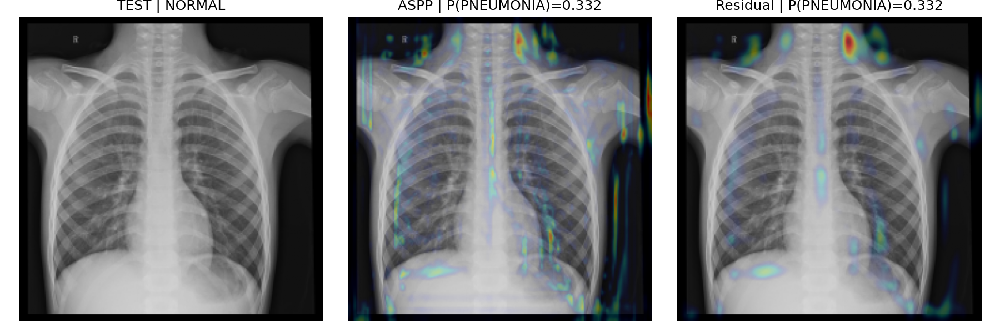

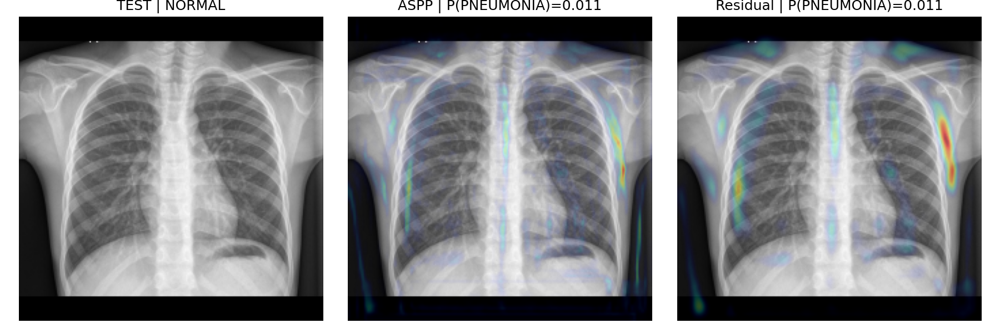

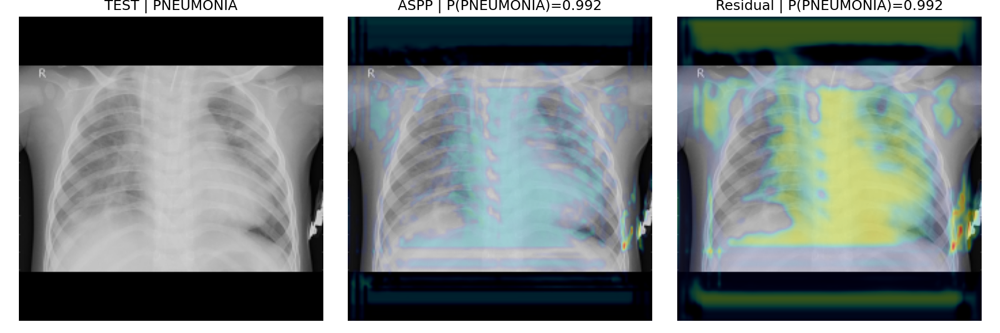

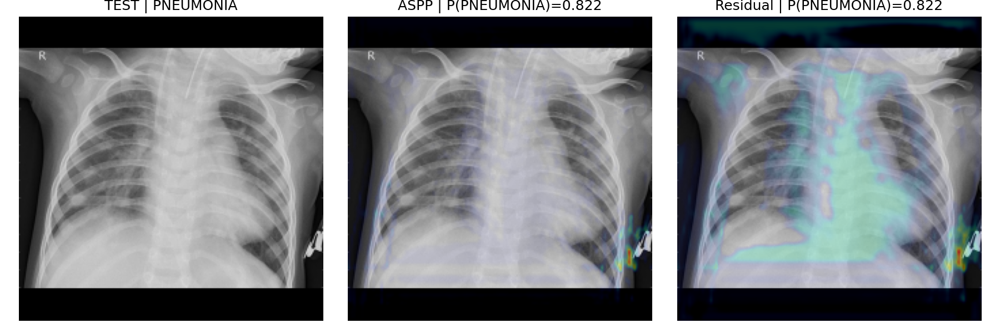

S0__P2 | seed=42 | checkpoint: /home/arsyadmuhammad/AI Project/Pneumonia/output_pneunet_e5_segmentation_3level/runs/full/S0__P2__seed_42/best.pt


experiment_id,seed,split,source_index,target_layer,target_class,padding_cam_ratio,probability_pneumonia
S0__P2,42,test,5232,aspp_fuse.relu,0,0.026814,0.011186
S0__P2,42,test,5232,context_refine.1.relu_out,0,0.011891,0.011186
S0__P2,42,test,5233,aspp_fuse.relu,0,0.039065,0.042907
S0__P2,42,test,5233,context_refine.1.relu_out,0,0.006291,0.042907
S0__P2,42,test,5466,aspp_fuse.relu,1,0.416715,0.998766
S0__P2,42,test,5466,context_refine.1.relu_out,1,0.419826,0.998766
S0__P2,42,test,5467,aspp_fuse.relu,1,0.314489,0.785188
S0__P2,42,test,5467,context_refine.1.relu_out,1,0.329590,0.785188


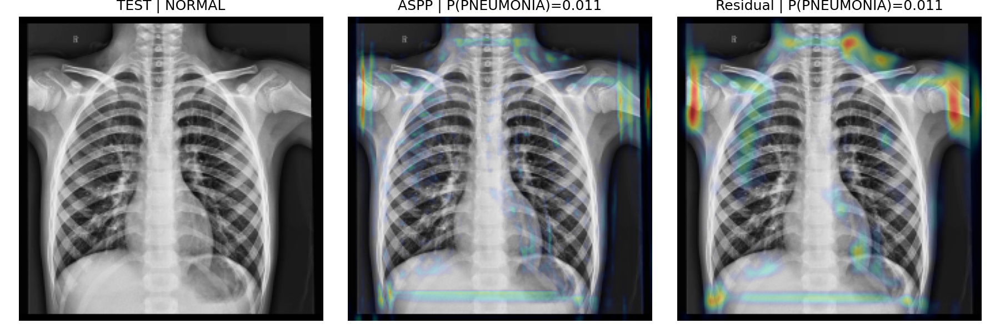

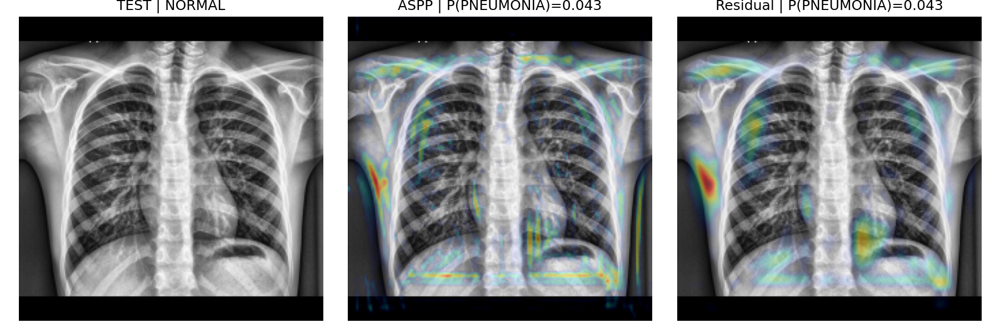

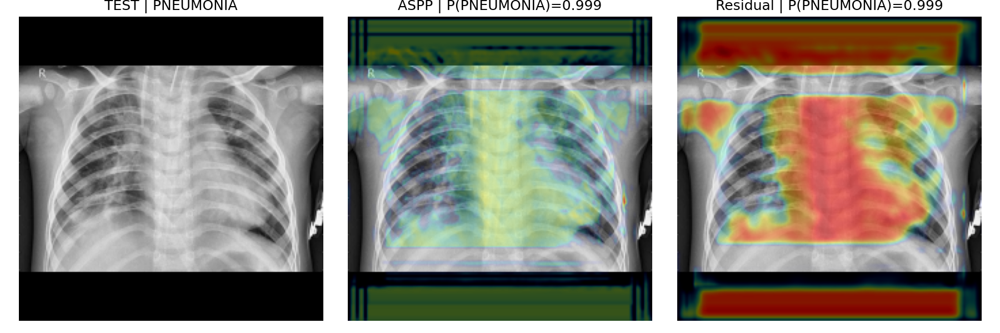

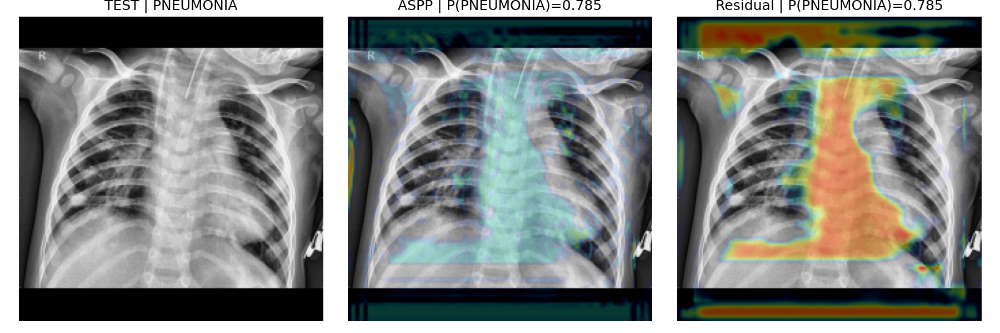

S0__P3 | seed=42 | checkpoint: /home/arsyadmuhammad/AI Project/Pneumonia/output_pneunet_e5_segmentation_3level/runs/full/S0__P3__seed_42/best.pt


experiment_id,seed,split,source_index,target_layer,target_class,padding_cam_ratio,probability_pneumonia
S0__P3,42,test,5232,aspp_fuse.relu,0,0.030113,0.011501
S0__P3,42,test,5232,context_refine.1.relu_out,0,0.016035,0.011501
S0__P3,42,test,5233,aspp_fuse.relu,0,0.048597,0.022309
S0__P3,42,test,5233,context_refine.1.relu_out,0,0.016203,0.022309
S0__P3,42,test,5466,aspp_fuse.relu,1,0.418948,0.997889
S0__P3,42,test,5466,context_refine.1.relu_out,1,0.381404,0.997889
S0__P3,42,test,5467,aspp_fuse.relu,1,0.303313,0.827329
S0__P3,42,test,5467,context_refine.1.relu_out,1,0.227517,0.827329


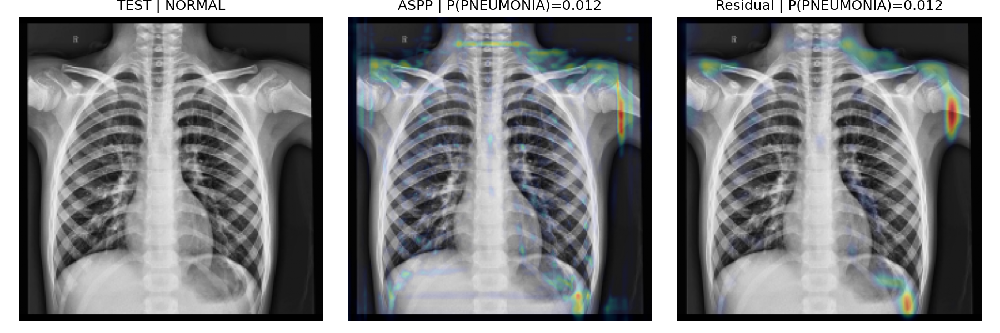

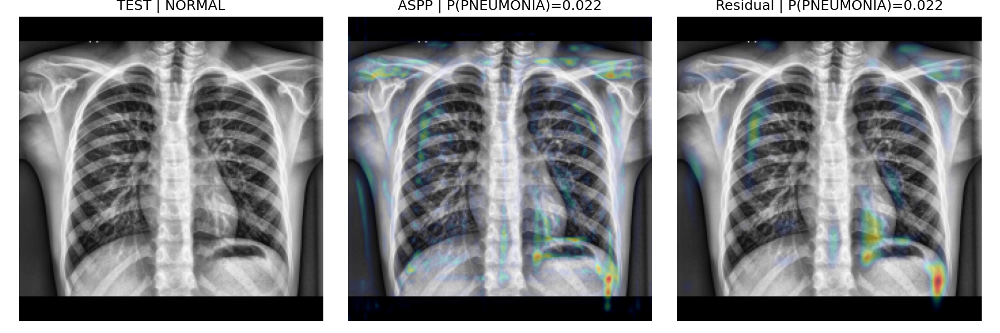

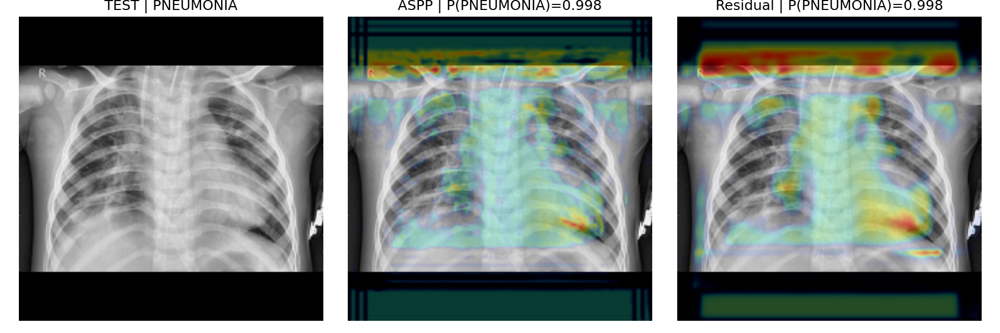

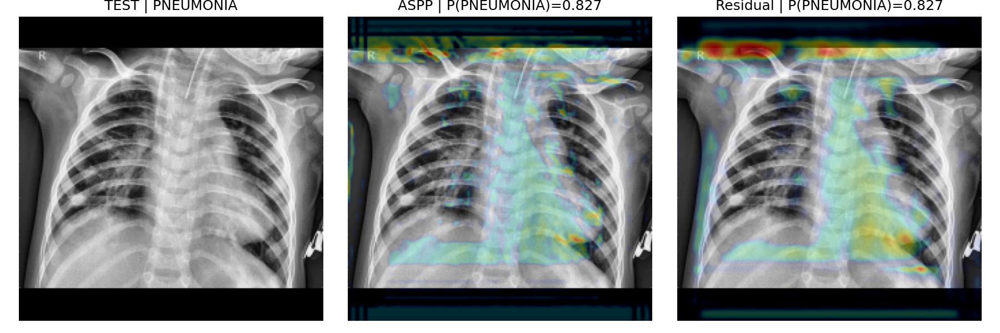

hybridgnet__crop__P1 | seed=42 | checkpoint: /home/arsyadmuhammad/AI Project/Pneumonia/output_pneunet_e5_segmentation_3level/runs/full/hybridgnet__crop__P1__seed_42/best.pt


experiment_id,seed,split,source_index,target_layer,target_class,padding_cam_ratio,probability_pneumonia
hybridgnet__crop__P1,42,test,5232,aspp_fuse.relu,0,0.002947,0.028310
hybridgnet__crop__P1,42,test,5232,context_refine.1.relu_out,0,0.000241,0.028310
hybridgnet__crop__P1,42,test,5233,aspp_fuse.relu,0,0.042440,0.051188
hybridgnet__crop__P1,42,test,5233,context_refine.1.relu_out,0,0.010563,0.051188
hybridgnet__crop__P1,42,test,5466,aspp_fuse.relu,1,0.398366,0.972365
hybridgnet__crop__P1,42,test,5466,context_refine.1.relu_out,1,0.386388,0.972365
hybridgnet__crop__P1,42,test,5467,aspp_fuse.relu,1,0.168326,0.794782
hybridgnet__crop__P1,42,test,5467,context_refine.1.relu_out,1,0.173865,0.794782


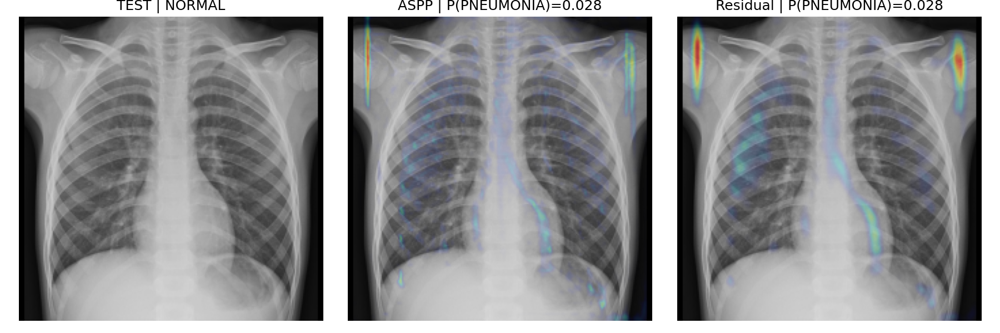

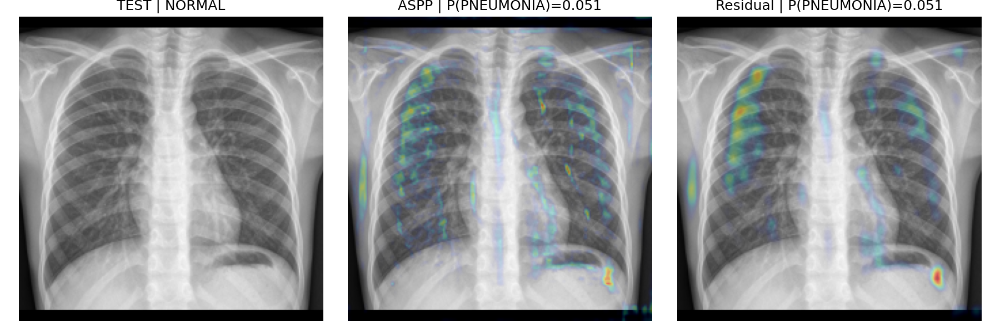

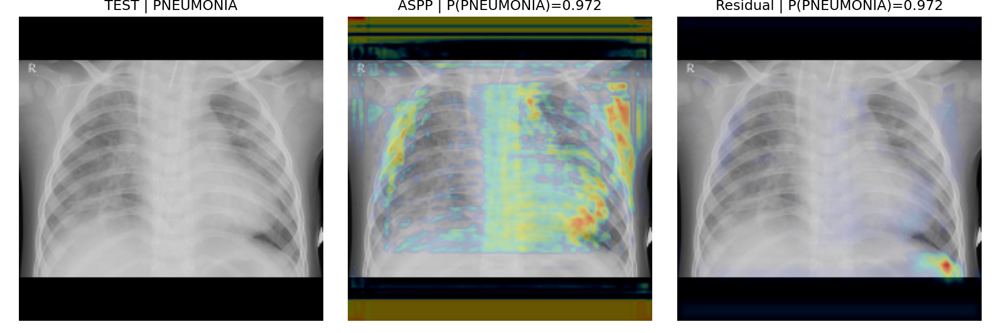

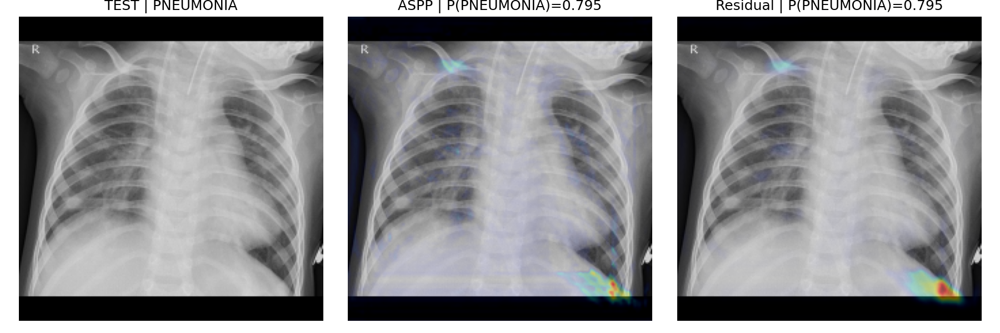

hybridgnet__crop__P2 | seed=42 | checkpoint: /home/arsyadmuhammad/AI Project/Pneumonia/output_pneunet_e5_segmentation_3level/runs/full/hybridgnet__crop__P2__seed_42/best.pt


experiment_id,seed,split,source_index,target_layer,target_class,padding_cam_ratio,probability_pneumonia
hybridgnet__crop__P2,42,test,5232,aspp_fuse.relu,0,0.016410,0.190171
hybridgnet__crop__P2,42,test,5232,context_refine.1.relu_out,0,0.000032,0.190171
hybridgnet__crop__P2,42,test,5233,aspp_fuse.relu,0,0.025517,0.000452
hybridgnet__crop__P2,42,test,5233,context_refine.1.relu_out,0,0.008180,0.000452
hybridgnet__crop__P2,42,test,5466,aspp_fuse.relu,1,0.328661,0.992392
hybridgnet__crop__P2,42,test,5466,context_refine.1.relu_out,1,0.243254,0.992392
hybridgnet__crop__P2,42,test,5467,aspp_fuse.relu,1,0.169050,0.950734
hybridgnet__crop__P2,42,test,5467,context_refine.1.relu_out,1,0.080773,0.950734


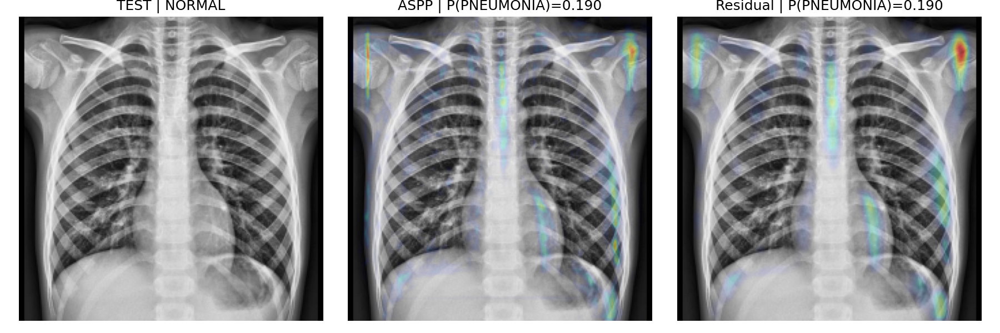

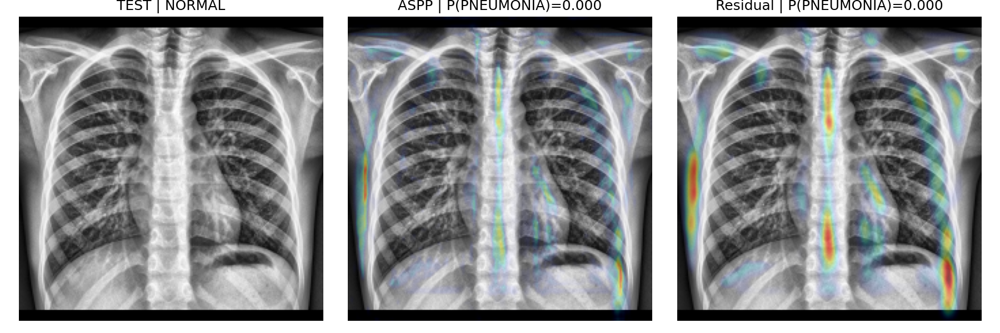

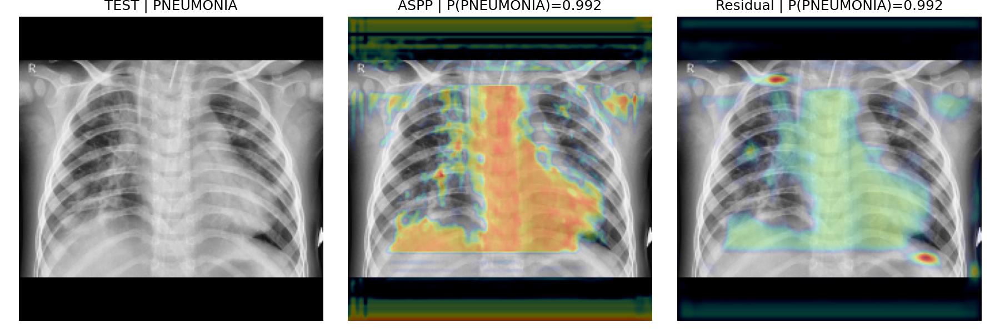

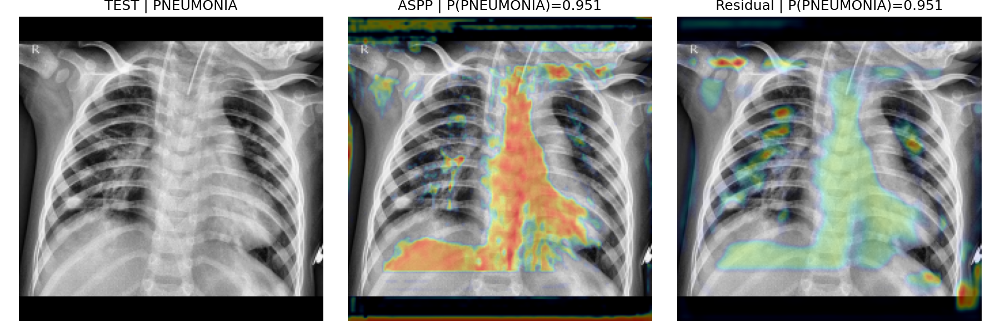

hybridgnet__crop__P3 | seed=42 | checkpoint: /home/arsyadmuhammad/AI Project/Pneumonia/output_pneunet_e5_segmentation_3level/runs/full/hybridgnet__crop__P3__seed_42/best.pt


experiment_id,seed,split,source_index,target_layer,target_class,padding_cam_ratio,probability_pneumonia
hybridgnet__crop__P3,42,test,5232,aspp_fuse.relu,0,0.003817,0.358391
hybridgnet__crop__P3,42,test,5232,context_refine.1.relu_out,0,0.000091,0.358391
hybridgnet__crop__P3,42,test,5233,aspp_fuse.relu,0,0.061037,0.023980
hybridgnet__crop__P3,42,test,5233,context_refine.1.relu_out,0,0.017476,0.023980
hybridgnet__crop__P3,42,test,5466,aspp_fuse.relu,1,0.276849,0.993290
hybridgnet__crop__P3,42,test,5466,context_refine.1.relu_out,1,0.245415,0.993290
hybridgnet__crop__P3,42,test,5467,aspp_fuse.relu,1,0.092834,0.893679
hybridgnet__crop__P3,42,test,5467,context_refine.1.relu_out,1,0.058728,0.893679


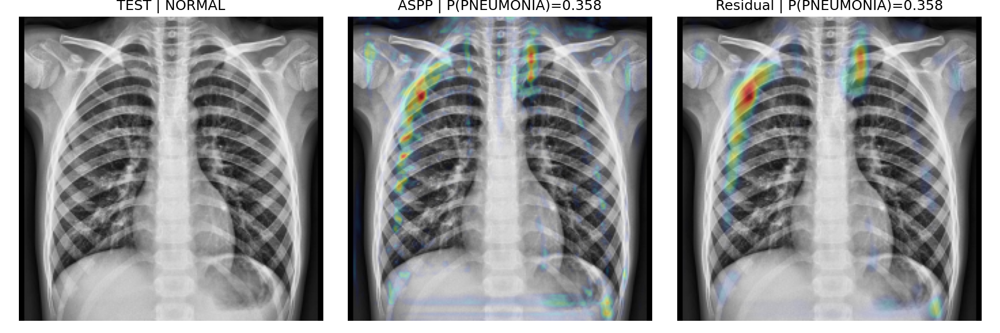

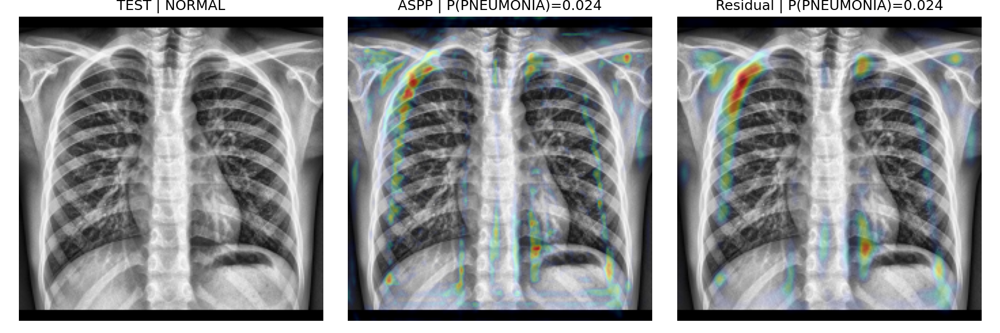

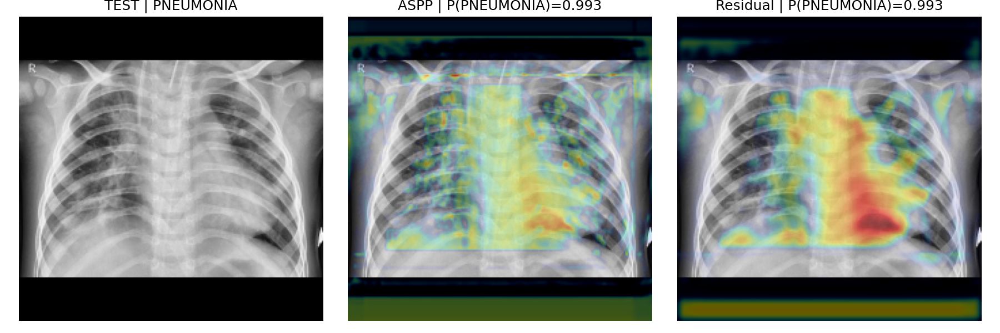

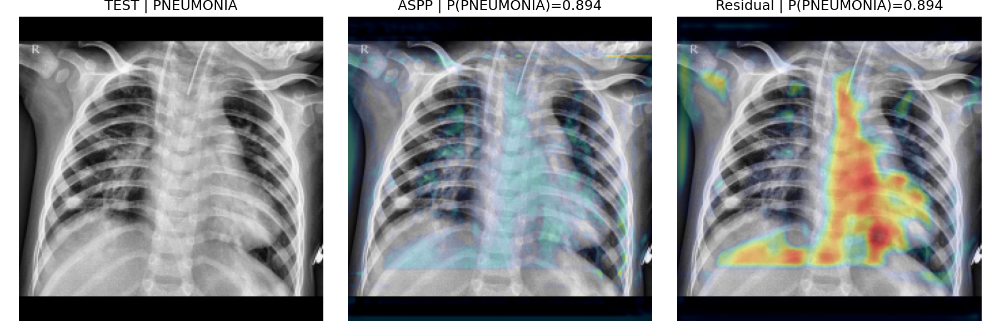

hybridgnet__mask__P1 | seed=42 | checkpoint: /home/arsyadmuhammad/AI Project/Pneumonia/output_pneunet_e5_segmentation_3level/runs/full/hybridgnet__mask__P1__seed_42/best.pt


experiment_id,seed,split,source_index,target_layer,target_class,padding_cam_ratio,probability_pneumonia
hybridgnet__mask__P1,42,test,5232,aspp_fuse.relu,0,0.028553,0.130681
hybridgnet__mask__P1,42,test,5232,context_refine.1.relu_out,0,0.000271,0.130681
hybridgnet__mask__P1,42,test,5233,aspp_fuse.relu,0,0.109150,0.126034
hybridgnet__mask__P1,42,test,5233,context_refine.1.relu_out,0,0.002017,0.126034
hybridgnet__mask__P1,42,test,5466,aspp_fuse.relu,1,0.121773,0.947712
hybridgnet__mask__P1,42,test,5466,context_refine.1.relu_out,1,0.212970,0.947712
hybridgnet__mask__P1,42,test,5467,aspp_fuse.relu,1,0.095892,0.497429
hybridgnet__mask__P1,42,test,5467,context_refine.1.relu_out,1,0.191170,0.497429


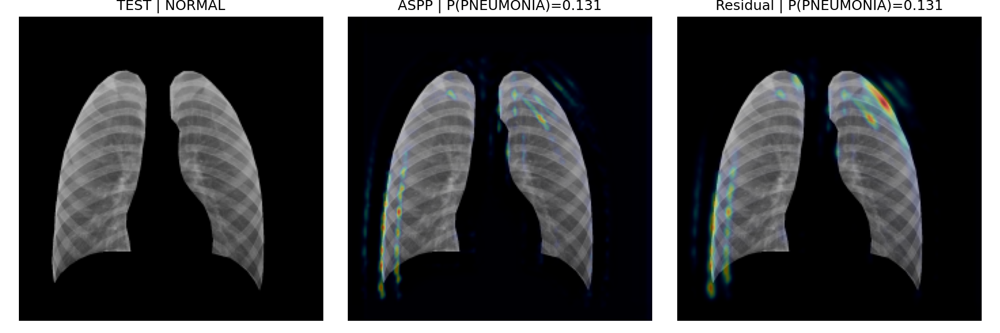

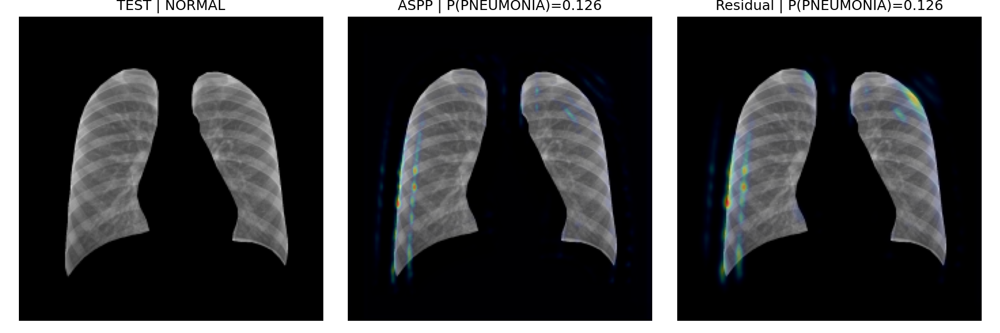

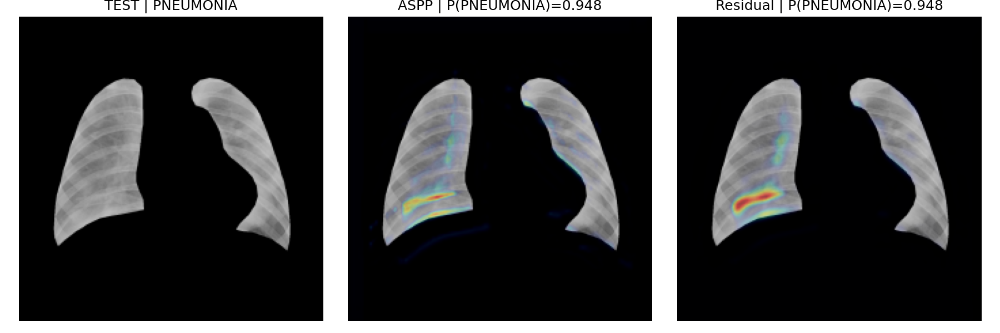

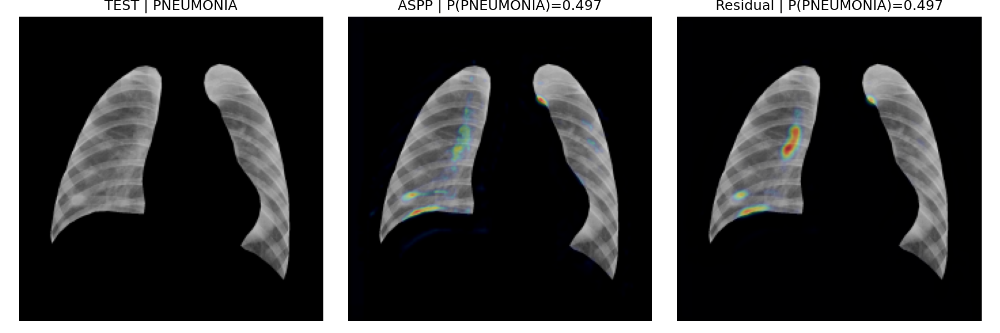

hybridgnet__mask__P2 | seed=42 | checkpoint: /home/arsyadmuhammad/AI Project/Pneumonia/output_pneunet_e5_segmentation_3level/runs/full/hybridgnet__mask__P2__seed_42/best.pt


experiment_id,seed,split,source_index,target_layer,target_class,padding_cam_ratio,probability_pneumonia
hybridgnet__mask__P2,42,test,5232,aspp_fuse.relu,0,0.000374,0.077396
hybridgnet__mask__P2,42,test,5232,context_refine.1.relu_out,0,0.000000,0.077396
hybridgnet__mask__P2,42,test,5233,aspp_fuse.relu,0,0.030568,0.049393
hybridgnet__mask__P2,42,test,5233,context_refine.1.relu_out,0,0.000002,0.049393
hybridgnet__mask__P2,42,test,5466,aspp_fuse.relu,1,0.223944,0.998524
hybridgnet__mask__P2,42,test,5466,context_refine.1.relu_out,1,0.041205,0.998524
hybridgnet__mask__P2,42,test,5467,aspp_fuse.relu,1,0.160774,0.767916
hybridgnet__mask__P2,42,test,5467,context_refine.1.relu_out,1,0.059270,0.767916


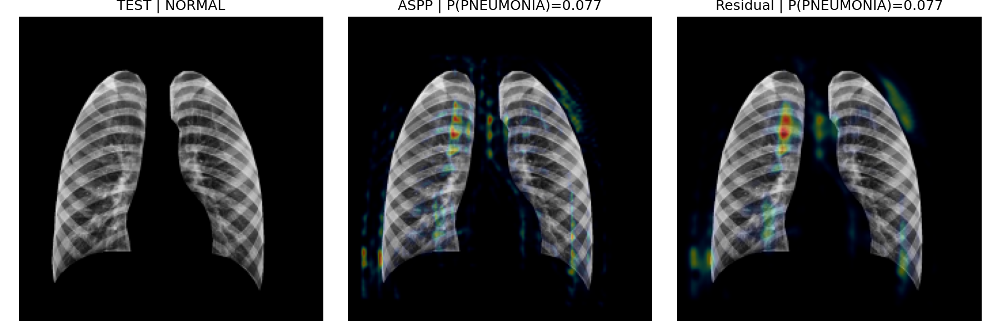

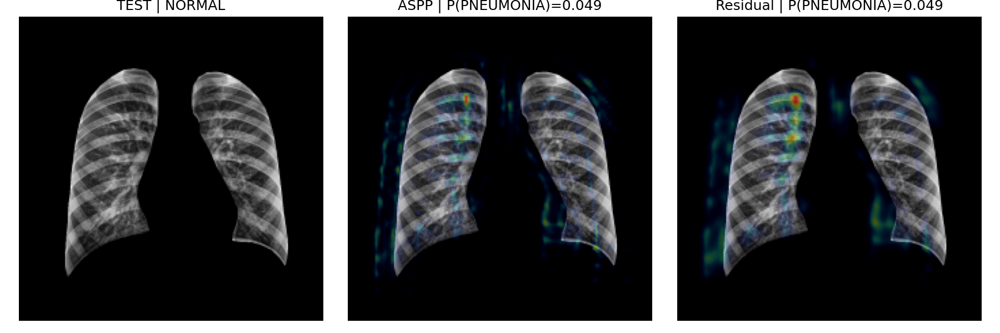

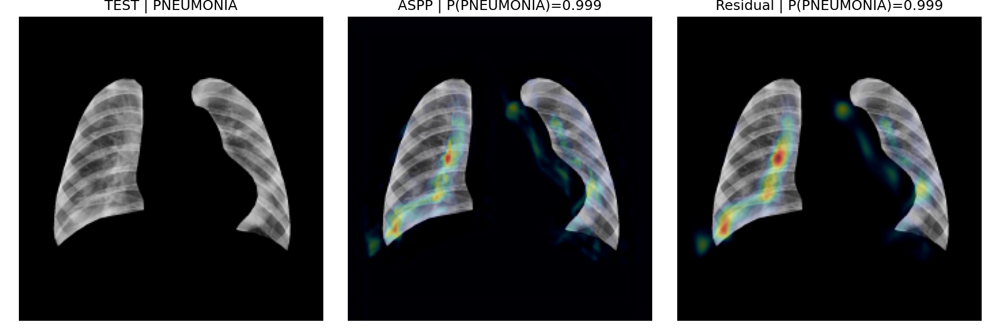

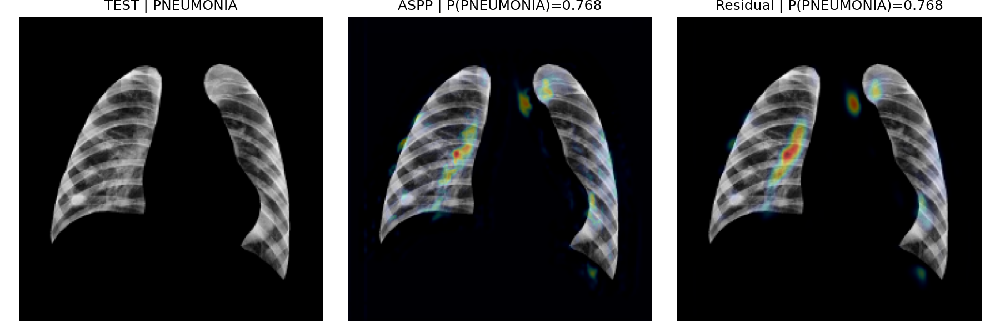

hybridgnet__mask__P3 | seed=42 | checkpoint: /home/arsyadmuhammad/AI Project/Pneumonia/output_pneunet_e5_segmentation_3level/runs/full/hybridgnet__mask__P3__seed_42/best.pt


experiment_id,seed,split,source_index,target_layer,target_class,padding_cam_ratio,probability_pneumonia
hybridgnet__mask__P3,42,test,5232,aspp_fuse.relu,0,0.018197,0.075624
hybridgnet__mask__P3,42,test,5232,context_refine.1.relu_out,0,0.001979,0.075624
hybridgnet__mask__P3,42,test,5233,aspp_fuse.relu,0,0.081653,0.129285
hybridgnet__mask__P3,42,test,5233,context_refine.1.relu_out,0,0.008570,0.129285
hybridgnet__mask__P3,42,test,5466,aspp_fuse.relu,1,0.000193,0.993394
hybridgnet__mask__P3,42,test,5466,context_refine.1.relu_out,1,0.009104,0.993394
hybridgnet__mask__P3,42,test,5467,aspp_fuse.relu,1,0.000369,0.946590
hybridgnet__mask__P3,42,test,5467,context_refine.1.relu_out,1,0.004085,0.946590


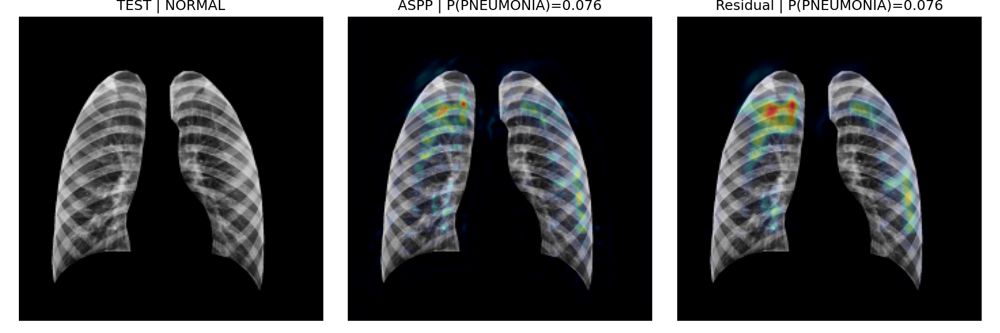

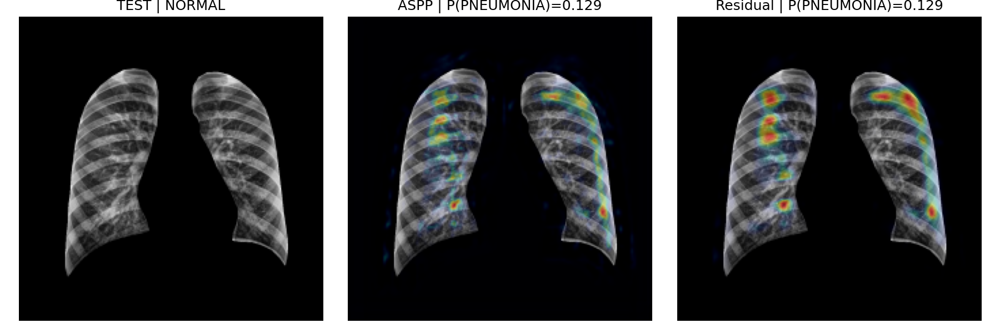

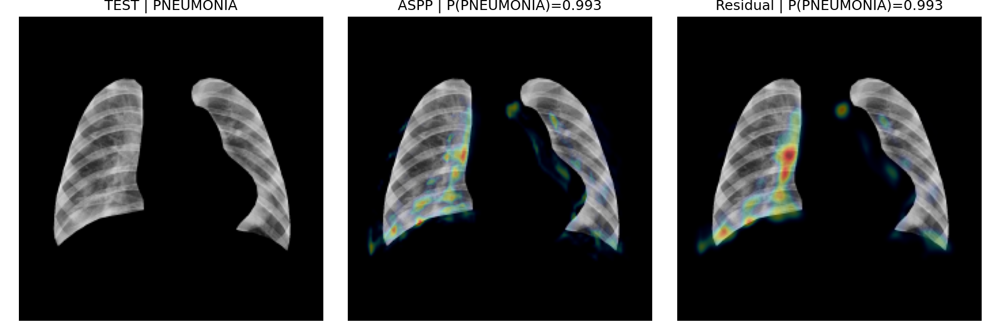

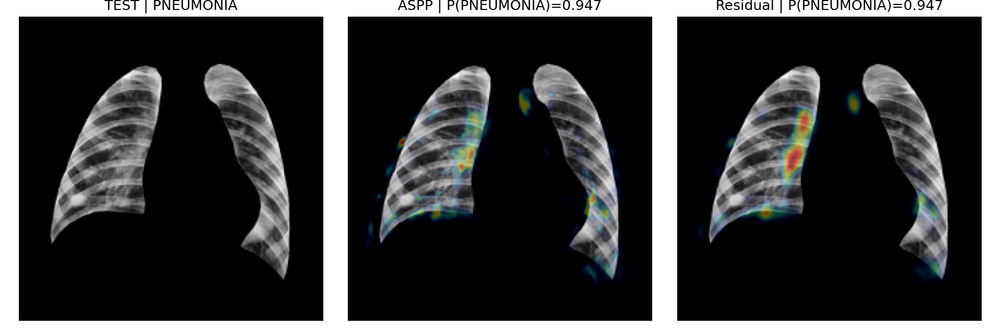

hybridgnet__crop_mask__P1 | seed=42 | checkpoint: /home/arsyadmuhammad/AI Project/Pneumonia/output_pneunet_e5_segmentation_3level/runs/full/hybridgnet__crop_mask__P1__seed_42/best.pt


experiment_id,seed,split,source_index,target_layer,target_class,padding_cam_ratio,probability_pneumonia
hybridgnet__crop_mask__P1,42,test,5232,aspp_fuse.relu,0,0.025414,0.885418
hybridgnet__crop_mask__P1,42,test,5232,context_refine.1.relu_out,0,0.000041,0.885418
hybridgnet__crop_mask__P1,42,test,5233,aspp_fuse.relu,0,0.052897,0.678490
hybridgnet__crop_mask__P1,42,test,5233,context_refine.1.relu_out,0,0.000000,0.678490
hybridgnet__crop_mask__P1,42,test,5466,aspp_fuse.relu,1,0.000000,0.954563
hybridgnet__crop_mask__P1,42,test,5466,context_refine.1.relu_out,1,0.326601,0.954563
hybridgnet__crop_mask__P1,42,test,5467,aspp_fuse.relu,1,0.000000,0.888815
hybridgnet__crop_mask__P1,42,test,5467,context_refine.1.relu_out,1,0.198769,0.888815


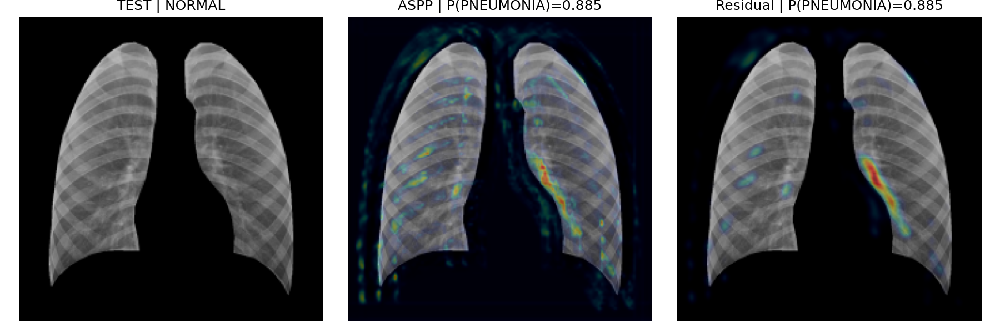

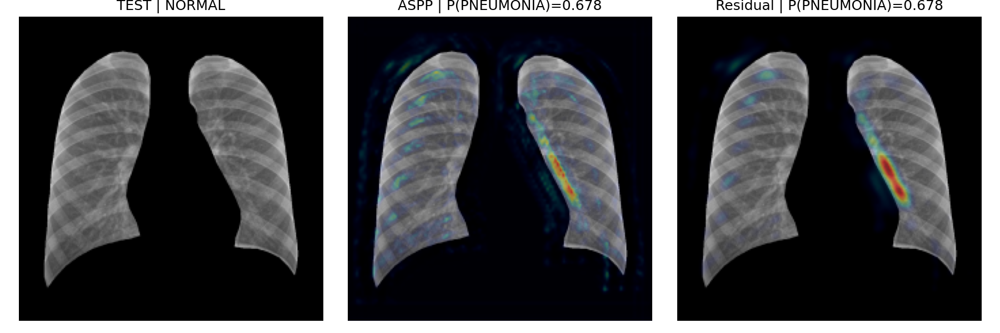

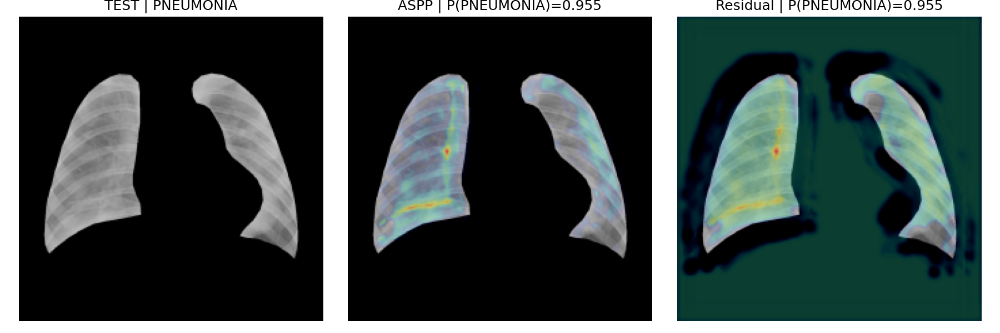

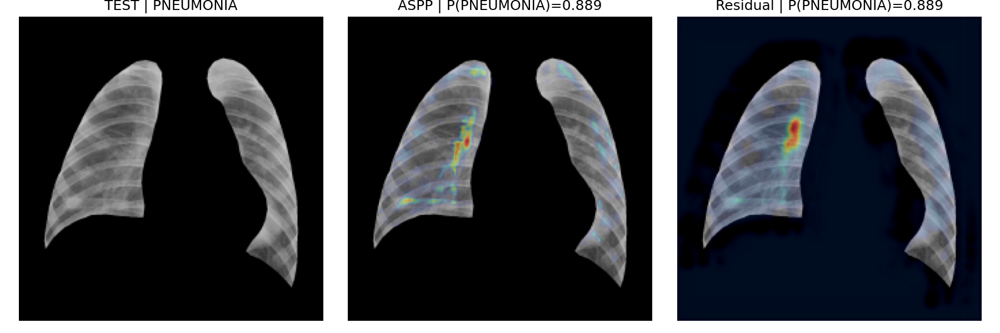

hybridgnet__crop_mask__P2 | seed=42 | checkpoint: /home/arsyadmuhammad/AI Project/Pneumonia/output_pneunet_e5_segmentation_3level/runs/full/hybridgnet__crop_mask__P2__seed_42/best.pt


experiment_id,seed,split,source_index,target_layer,target_class,padding_cam_ratio,probability_pneumonia
hybridgnet__crop_mask__P2,42,test,5232,aspp_fuse.relu,0,0.041288,0.075477
hybridgnet__crop_mask__P2,42,test,5232,context_refine.1.relu_out,0,0.008585,0.075477
hybridgnet__crop_mask__P2,42,test,5233,aspp_fuse.relu,0,0.074700,0.048730
hybridgnet__crop_mask__P2,42,test,5233,context_refine.1.relu_out,0,0.020816,0.048730
hybridgnet__crop_mask__P2,42,test,5466,aspp_fuse.relu,1,0.000860,0.996759
hybridgnet__crop_mask__P2,42,test,5466,context_refine.1.relu_out,1,0.001564,0.996759
hybridgnet__crop_mask__P2,42,test,5467,aspp_fuse.relu,1,0.000898,0.919547
hybridgnet__crop_mask__P2,42,test,5467,context_refine.1.relu_out,1,0.000944,0.919547


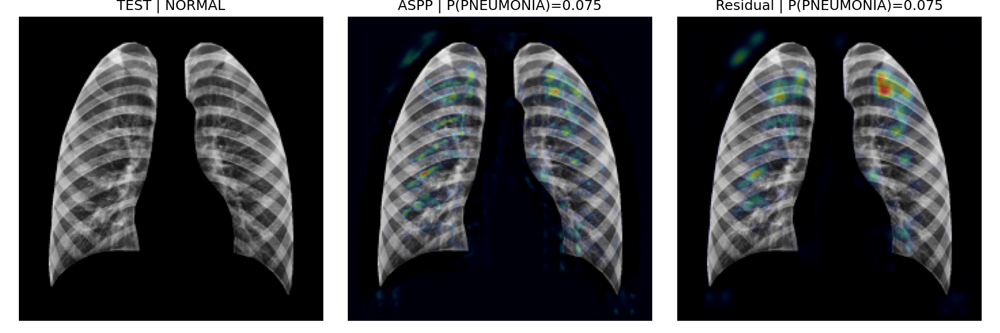

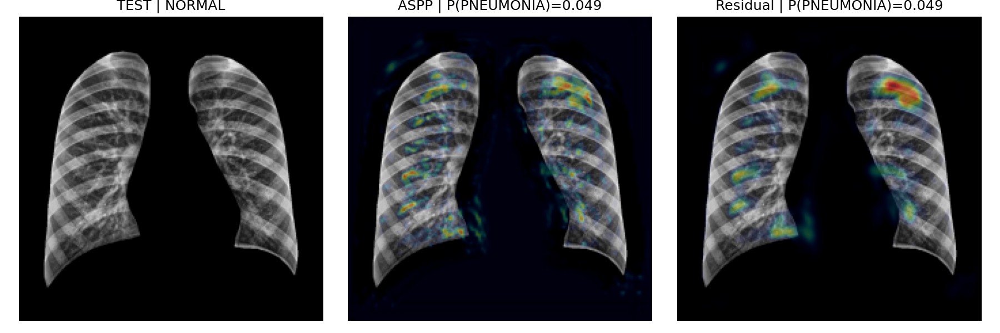

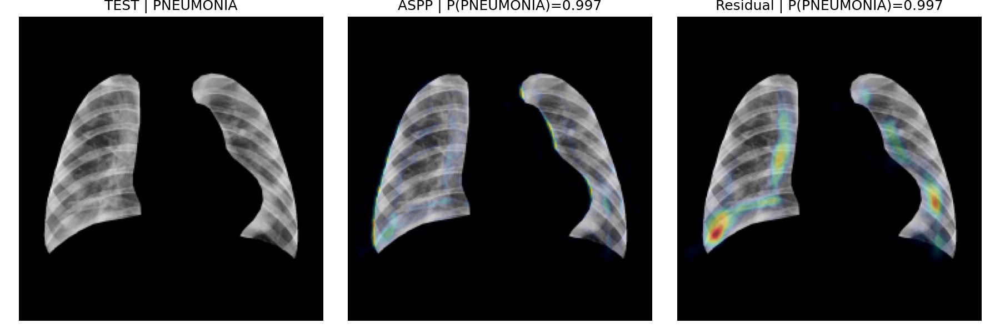

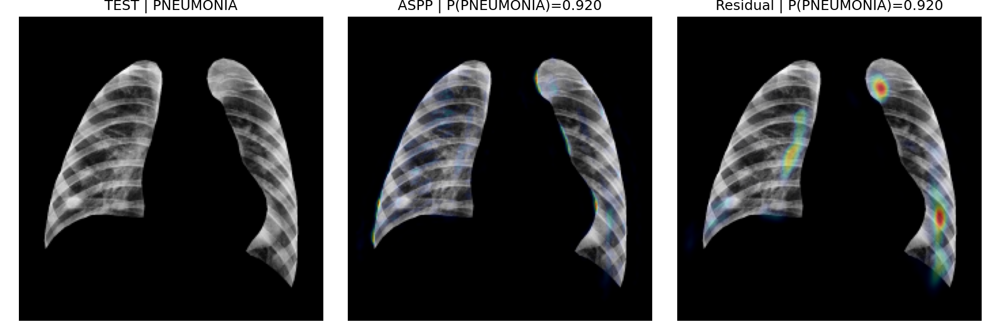

hybridgnet__crop_mask__P3 | seed=42 | checkpoint: /home/arsyadmuhammad/AI Project/Pneumonia/output_pneunet_e5_segmentation_3level/runs/full/hybridgnet__crop_mask__P3__seed_42/best.pt


experiment_id,seed,split,source_index,target_layer,target_class,padding_cam_ratio,probability_pneumonia
hybridgnet__crop_mask__P3,42,test,5232,aspp_fuse.relu,0,0.012563,0.003538
hybridgnet__crop_mask__P3,42,test,5232,context_refine.1.relu_out,0,0.023542,0.003538
hybridgnet__crop_mask__P3,42,test,5233,aspp_fuse.relu,0,0.009541,0.036007
hybridgnet__crop_mask__P3,42,test,5233,context_refine.1.relu_out,0,0.041478,0.036007
hybridgnet__crop_mask__P3,42,test,5466,aspp_fuse.relu,1,0.259459,0.995785
hybridgnet__crop_mask__P3,42,test,5466,context_refine.1.relu_out,1,0.266440,0.995785
hybridgnet__crop_mask__P3,42,test,5467,aspp_fuse.relu,1,0.186412,0.958977
hybridgnet__crop_mask__P3,42,test,5467,context_refine.1.relu_out,1,0.167042,0.958977


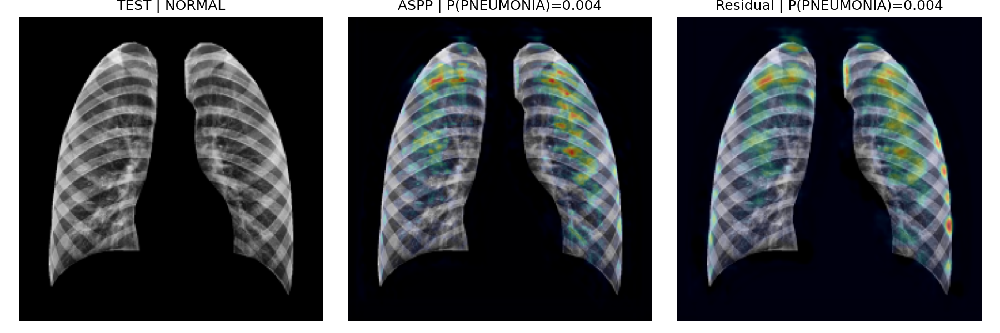

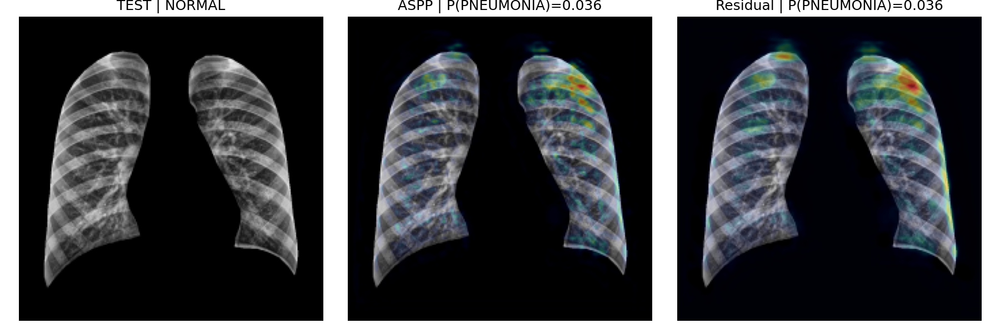

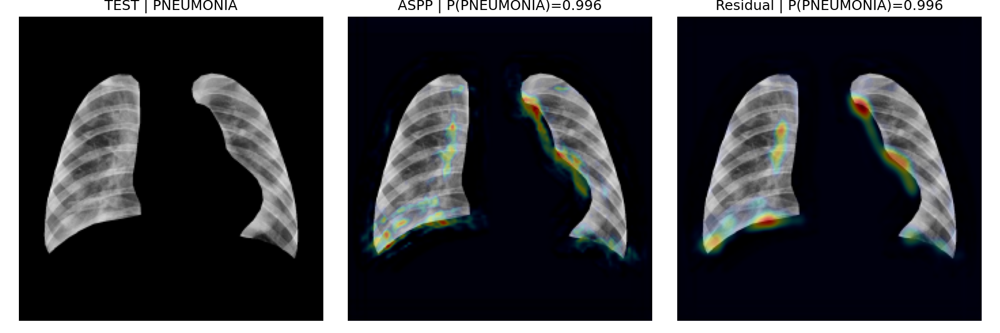

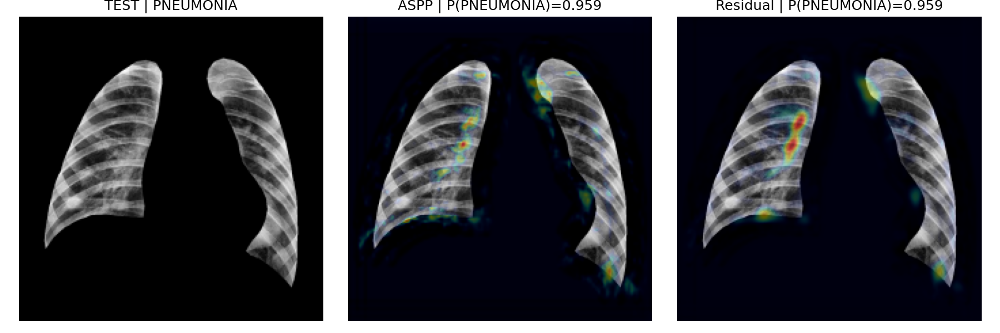

unet_resnet34__crop__P1 | seed=42 | checkpoint: /home/arsyadmuhammad/AI Project/Pneumonia/output_pneunet_e5_segmentation_3level/runs/full/unet_resnet34__crop__P1__seed_42/best.pt


experiment_id,seed,split,source_index,target_layer,target_class,padding_cam_ratio,probability_pneumonia
unet_resnet34__crop__P1,42,test,5232,aspp_fuse.relu,0,0.009341,0.796724
unet_resnet34__crop__P1,42,test,5232,context_refine.1.relu_out,0,0.000527,0.796724
unet_resnet34__crop__P1,42,test,5233,aspp_fuse.relu,0,0.047622,0.147895
unet_resnet34__crop__P1,42,test,5233,context_refine.1.relu_out,0,0.001043,0.147895
unet_resnet34__crop__P1,42,test,5466,aspp_fuse.relu,1,0.185160,0.979446
unet_resnet34__crop__P1,42,test,5466,context_refine.1.relu_out,1,0.310024,0.979446
unet_resnet34__crop__P1,42,test,5467,aspp_fuse.relu,1,0.138493,0.945605
unet_resnet34__crop__P1,42,test,5467,context_refine.1.relu_out,1,0.218336,0.945605


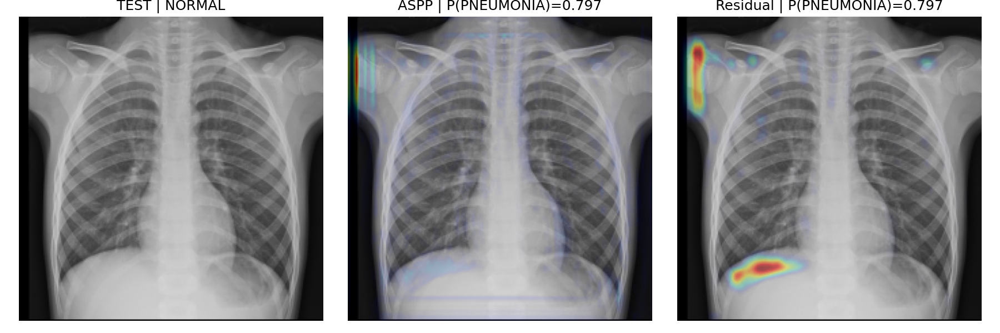

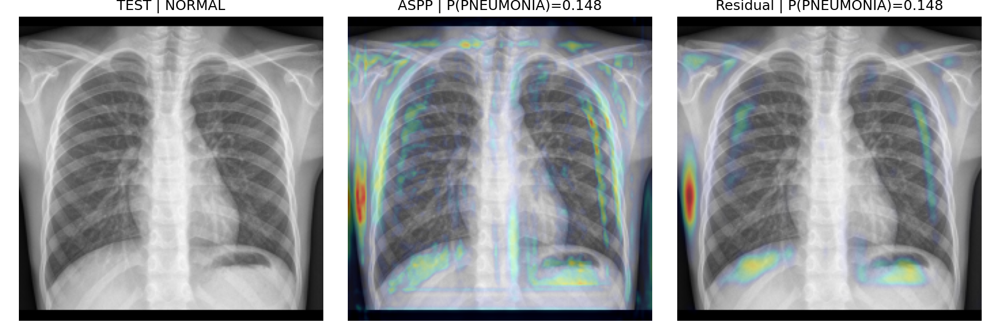

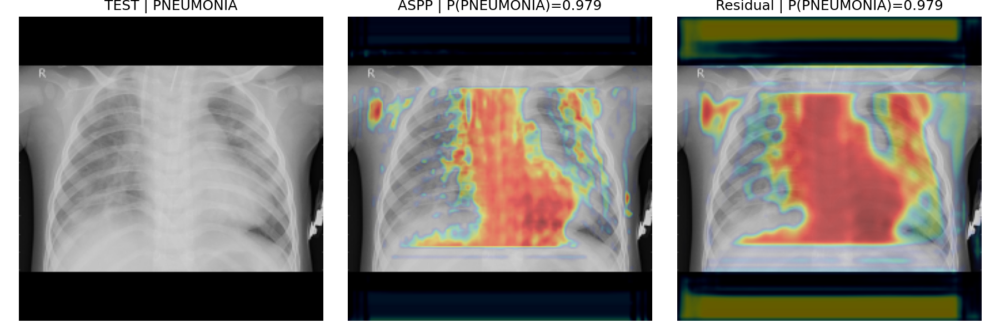

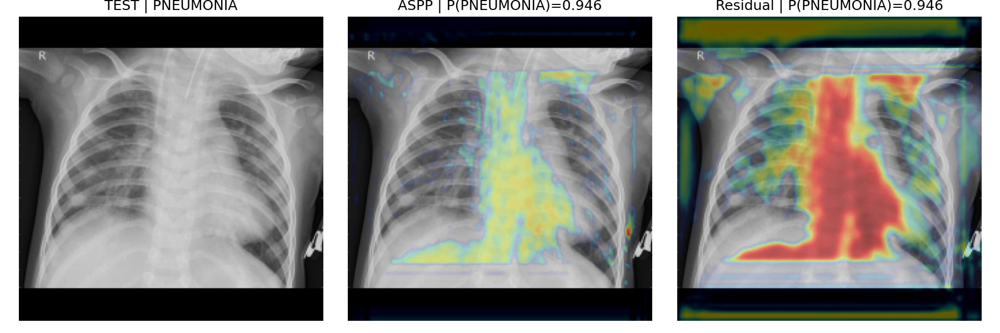

unet_resnet34__crop__P2 | seed=42 | checkpoint: /home/arsyadmuhammad/AI Project/Pneumonia/output_pneunet_e5_segmentation_3level/runs/full/unet_resnet34__crop__P2__seed_42/best.pt


experiment_id,seed,split,source_index,target_layer,target_class,padding_cam_ratio,probability_pneumonia
unet_resnet34__crop__P2,42,test,5232,aspp_fuse.relu,0,0.002317,0.084670
unet_resnet34__crop__P2,42,test,5232,context_refine.1.relu_out,0,0.002146,0.084670
unet_resnet34__crop__P2,42,test,5233,aspp_fuse.relu,0,0.045012,0.106915
unet_resnet34__crop__P2,42,test,5233,context_refine.1.relu_out,0,0.012455,0.106915
unet_resnet34__crop__P2,42,test,5466,aspp_fuse.relu,1,0.287454,0.984021
unet_resnet34__crop__P2,42,test,5466,context_refine.1.relu_out,1,0.229443,0.984021
unet_resnet34__crop__P2,42,test,5467,aspp_fuse.relu,1,0.246254,0.950779
unet_resnet34__crop__P2,42,test,5467,context_refine.1.relu_out,1,0.155132,0.950779


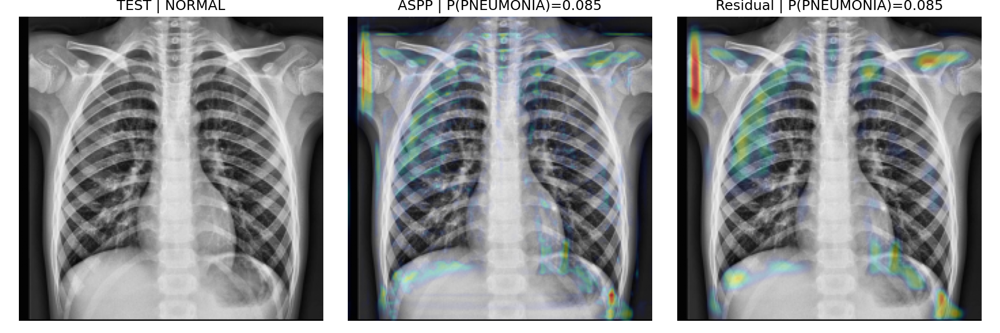

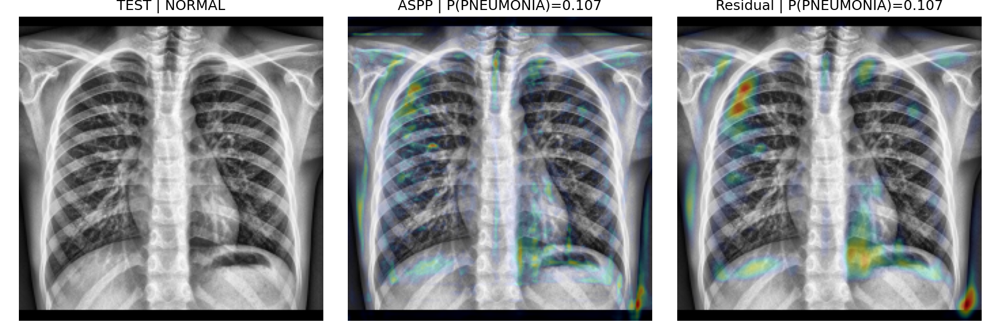

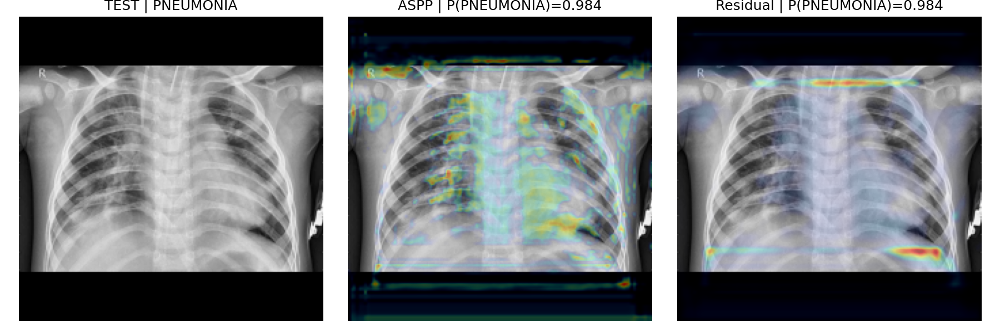

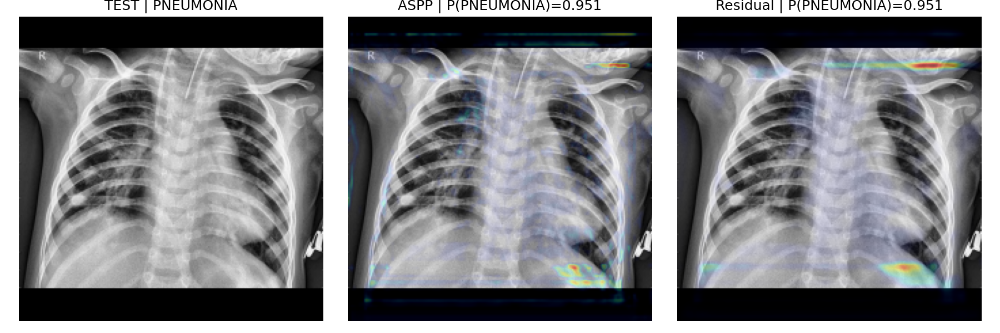

unet_resnet34__crop__P3 | seed=42 | checkpoint: /home/arsyadmuhammad/AI Project/Pneumonia/output_pneunet_e5_segmentation_3level/runs/full/unet_resnet34__crop__P3__seed_42/best.pt


experiment_id,seed,split,source_index,target_layer,target_class,padding_cam_ratio,probability_pneumonia
unet_resnet34__crop__P3,42,test,5232,aspp_fuse.relu,0,0.005544,0.499070
unet_resnet34__crop__P3,42,test,5232,context_refine.1.relu_out,0,0.003118,0.499070
unet_resnet34__crop__P3,42,test,5233,aspp_fuse.relu,0,0.086809,0.043037
unet_resnet34__crop__P3,42,test,5233,context_refine.1.relu_out,0,0.072276,0.043037
unet_resnet34__crop__P3,42,test,5466,aspp_fuse.relu,1,0.235286,0.997520
unet_resnet34__crop__P3,42,test,5466,context_refine.1.relu_out,1,0.234471,0.997520
unet_resnet34__crop__P3,42,test,5467,aspp_fuse.relu,1,0.138529,0.986726
unet_resnet34__crop__P3,42,test,5467,context_refine.1.relu_out,1,0.136664,0.986726


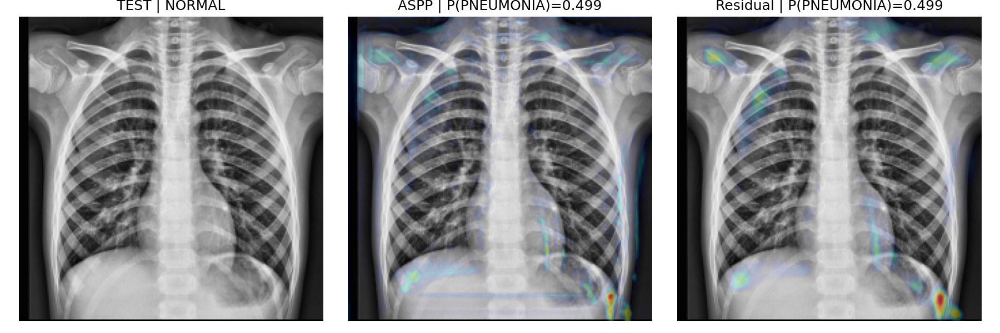

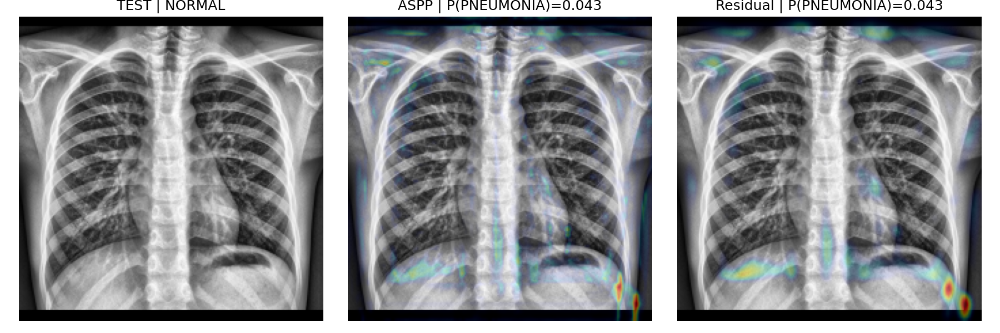

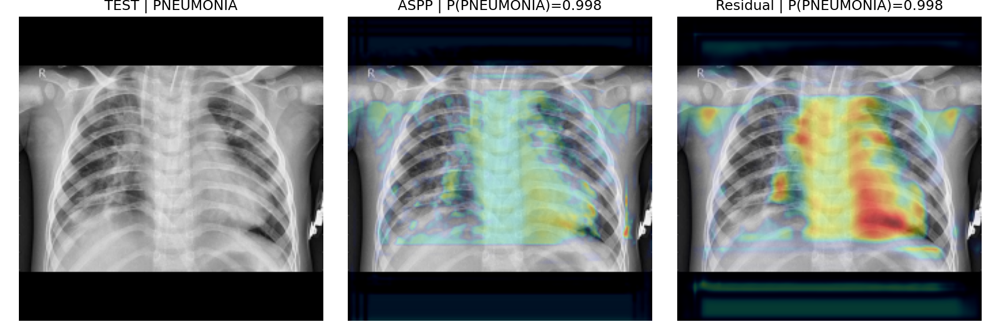

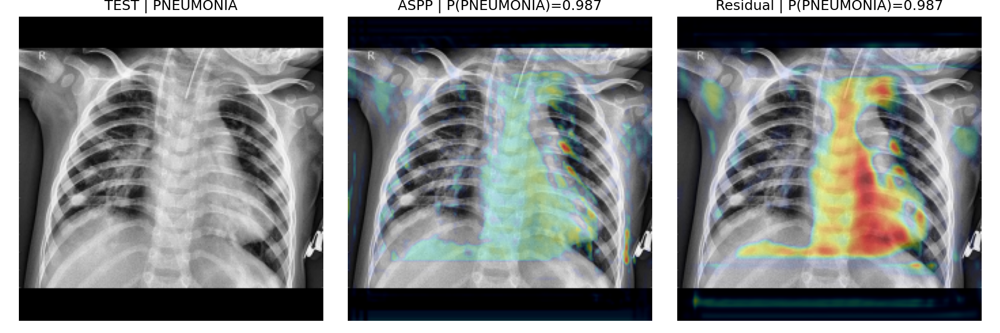

unet_resnet34__mask__P1 | seed=42 | checkpoint: /home/arsyadmuhammad/AI Project/Pneumonia/output_pneunet_e5_segmentation_3level/runs/full/unet_resnet34__mask__P1__seed_42/best.pt


experiment_id,seed,split,source_index,target_layer,target_class,padding_cam_ratio,probability_pneumonia
unet_resnet34__mask__P1,42,test,5232,aspp_fuse.relu,0,0.031886,0.040179
unet_resnet34__mask__P1,42,test,5232,context_refine.1.relu_out,0,0.001355,0.040179
unet_resnet34__mask__P1,42,test,5233,aspp_fuse.relu,0,0.084207,0.001794
unet_resnet34__mask__P1,42,test,5233,context_refine.1.relu_out,0,0.002748,0.001794
unet_resnet34__mask__P1,42,test,5466,aspp_fuse.relu,1,0.019684,0.900150
unet_resnet34__mask__P1,42,test,5466,context_refine.1.relu_out,1,0.046389,0.900150
unet_resnet34__mask__P1,42,test,5467,aspp_fuse.relu,1,0.022918,0.990244
unet_resnet34__mask__P1,42,test,5467,context_refine.1.relu_out,1,0.026986,0.990244


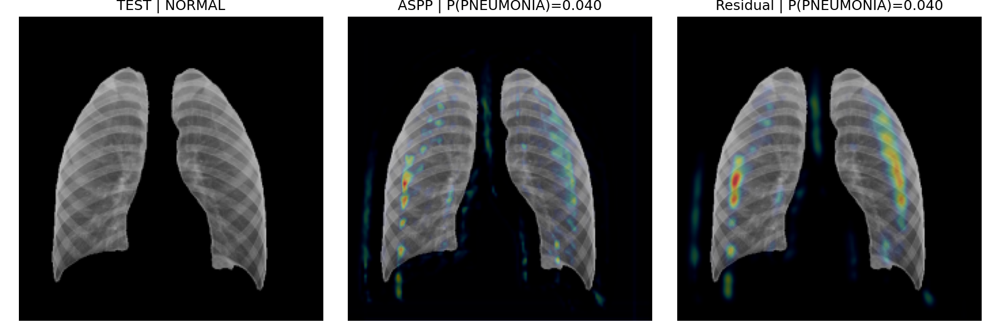

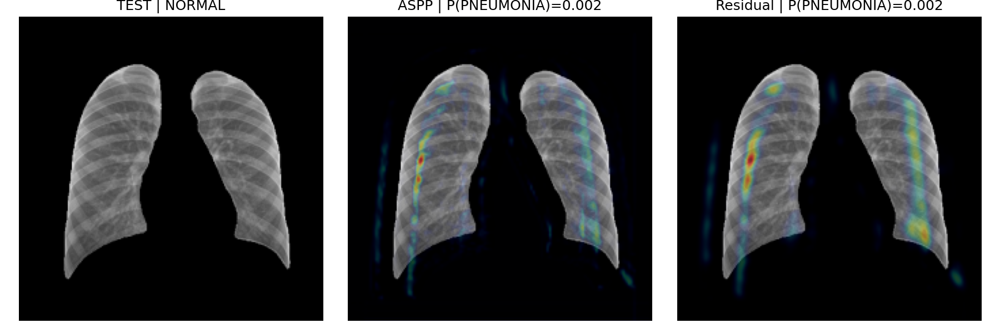

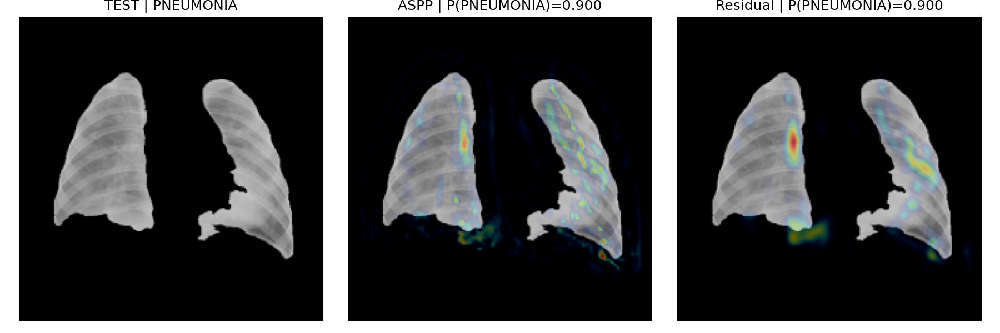

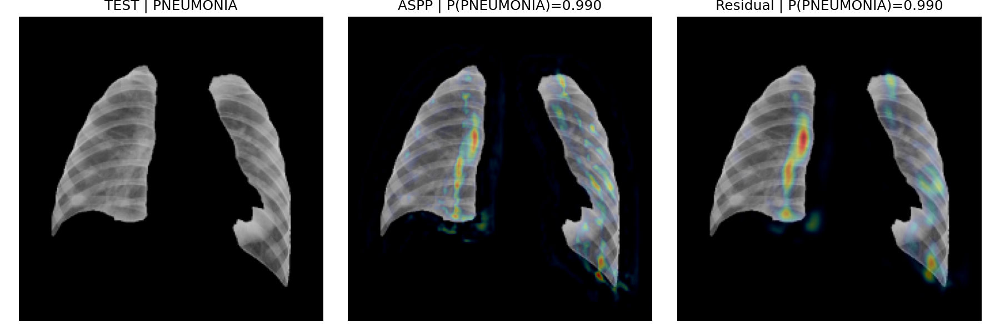

unet_resnet34__mask__P2 | seed=42 | checkpoint: /home/arsyadmuhammad/AI Project/Pneumonia/output_pneunet_e5_segmentation_3level/runs/full/unet_resnet34__mask__P2__seed_42/best.pt


experiment_id,seed,split,source_index,target_layer,target_class,padding_cam_ratio,probability_pneumonia
unet_resnet34__mask__P2,42,test,5232,aspp_fuse.relu,0,0.000636,0.013133
unet_resnet34__mask__P2,42,test,5232,context_refine.1.relu_out,0,0.000000,0.013133
unet_resnet34__mask__P2,42,test,5233,aspp_fuse.relu,0,0.002890,0.000854
unet_resnet34__mask__P2,42,test,5233,context_refine.1.relu_out,0,0.000000,0.000854
unet_resnet34__mask__P2,42,test,5466,aspp_fuse.relu,1,0.200932,0.993530
unet_resnet34__mask__P2,42,test,5466,context_refine.1.relu_out,1,0.105099,0.993530
unet_resnet34__mask__P2,42,test,5467,aspp_fuse.relu,1,0.140082,0.930259
unet_resnet34__mask__P2,42,test,5467,context_refine.1.relu_out,1,0.074381,0.930259


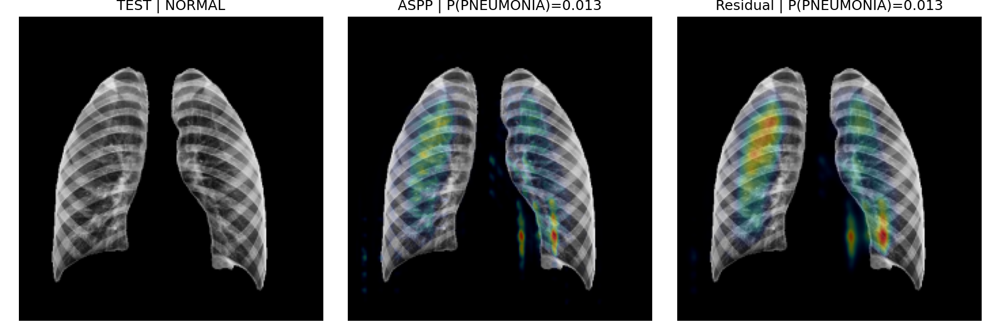

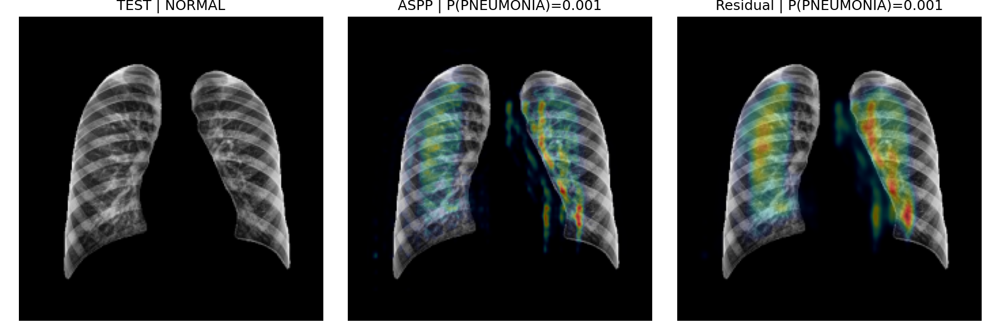

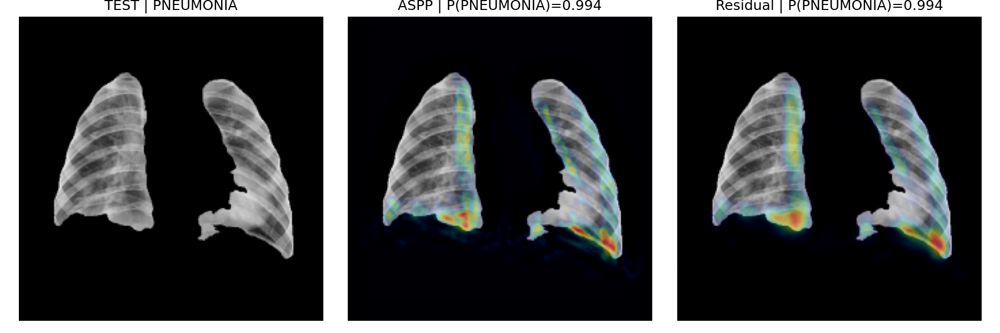

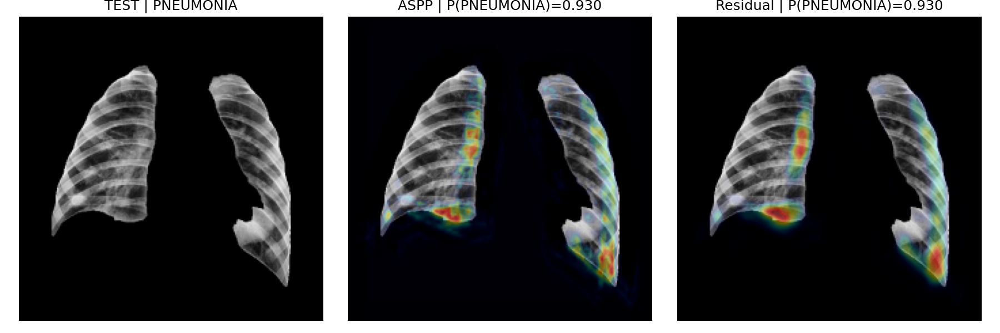

unet_resnet34__mask__P3 | seed=42 | checkpoint: /home/arsyadmuhammad/AI Project/Pneumonia/output_pneunet_e5_segmentation_3level/runs/full/unet_resnet34__mask__P3__seed_42/best.pt


experiment_id,seed,split,source_index,target_layer,target_class,padding_cam_ratio,probability_pneumonia
unet_resnet34__mask__P3,42,test,5232,aspp_fuse.relu,0,0.000000,0.010323
unet_resnet34__mask__P3,42,test,5232,context_refine.1.relu_out,0,0.000986,0.010323
unet_resnet34__mask__P3,42,test,5233,aspp_fuse.relu,0,0.000054,0.000009
unet_resnet34__mask__P3,42,test,5233,context_refine.1.relu_out,0,0.018888,0.000009
unet_resnet34__mask__P3,42,test,5466,aspp_fuse.relu,1,0.213888,0.999995
unet_resnet34__mask__P3,42,test,5466,context_refine.1.relu_out,1,0.080127,0.999995
unet_resnet34__mask__P3,42,test,5467,aspp_fuse.relu,1,0.170992,0.992679
unet_resnet34__mask__P3,42,test,5467,context_refine.1.relu_out,1,0.054251,0.992679


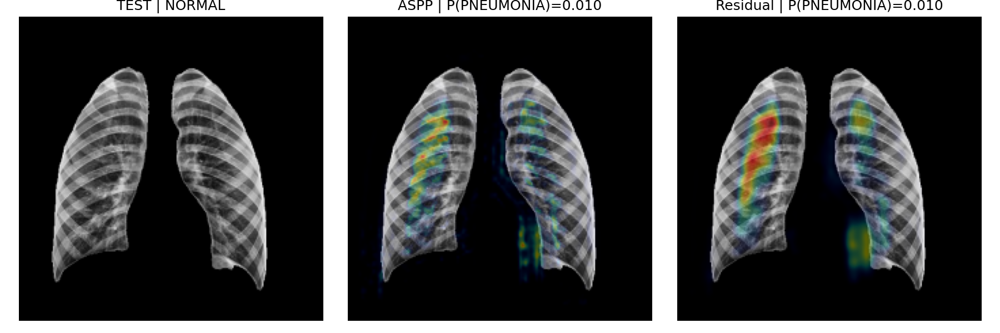

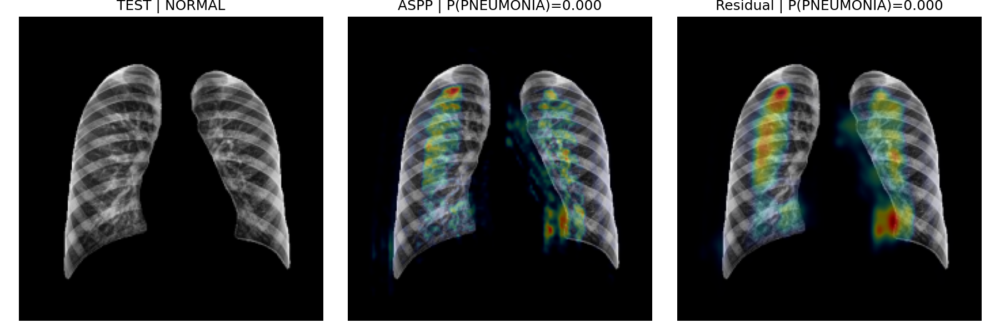

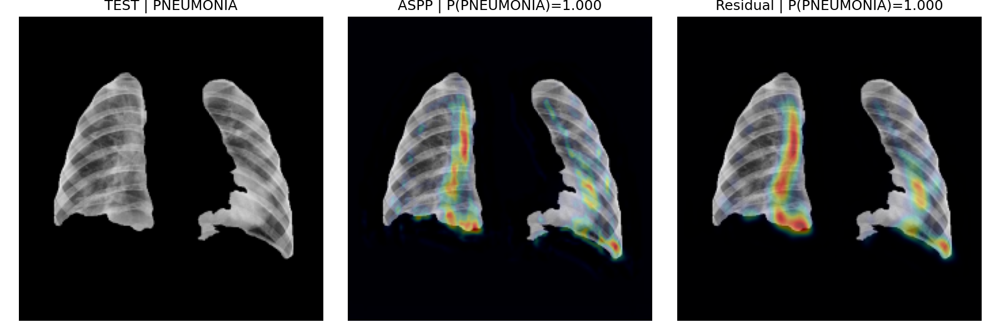

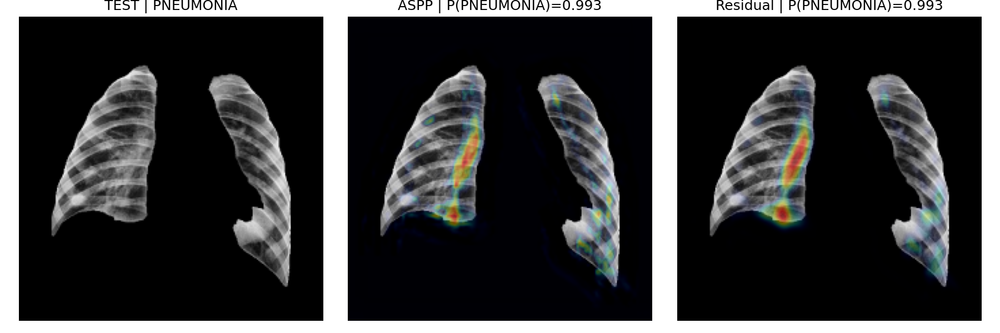

unet_resnet34__crop_mask__P1 | seed=42 | checkpoint: /home/arsyadmuhammad/AI Project/Pneumonia/output_pneunet_e5_segmentation_3level/runs/full/unet_resnet34__crop_mask__P1__seed_42/best.pt


experiment_id,seed,split,source_index,target_layer,target_class,padding_cam_ratio,probability_pneumonia
unet_resnet34__crop_mask__P1,42,test,5232,aspp_fuse.relu,0,0.003351,0.009026
unet_resnet34__crop_mask__P1,42,test,5232,context_refine.1.relu_out,0,0.000000,0.009026
unet_resnet34__crop_mask__P1,42,test,5233,aspp_fuse.relu,0,0.032130,0.000004
unet_resnet34__crop_mask__P1,42,test,5233,context_refine.1.relu_out,0,0.000007,0.000004
unet_resnet34__crop_mask__P1,42,test,5466,aspp_fuse.relu,1,0.004954,0.999845
unet_resnet34__crop_mask__P1,42,test,5466,context_refine.1.relu_out,1,0.033994,0.999845
unet_resnet34__crop_mask__P1,42,test,5467,aspp_fuse.relu,1,0.007446,0.989465
unet_resnet34__crop_mask__P1,42,test,5467,context_refine.1.relu_out,1,0.027846,0.989465


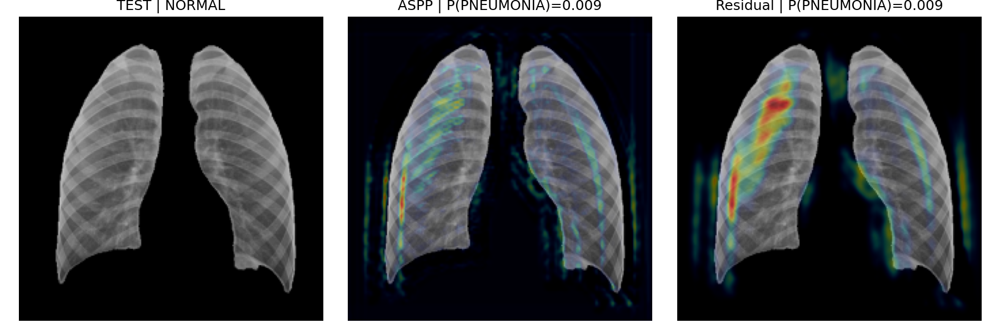

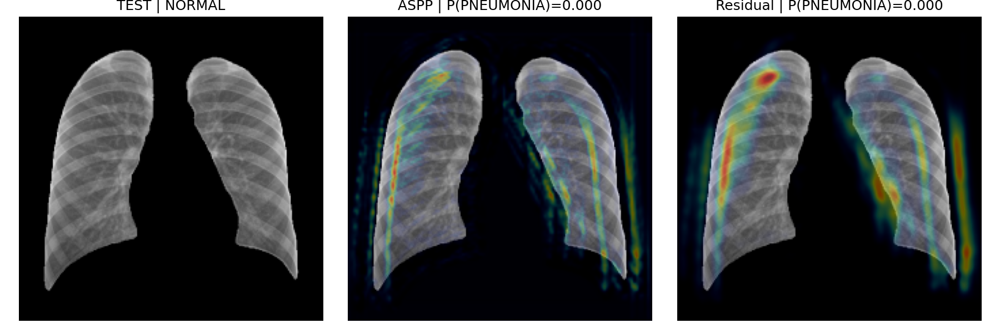

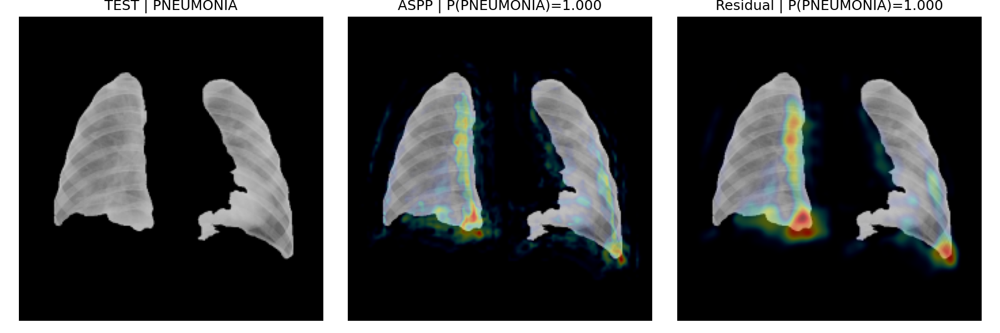

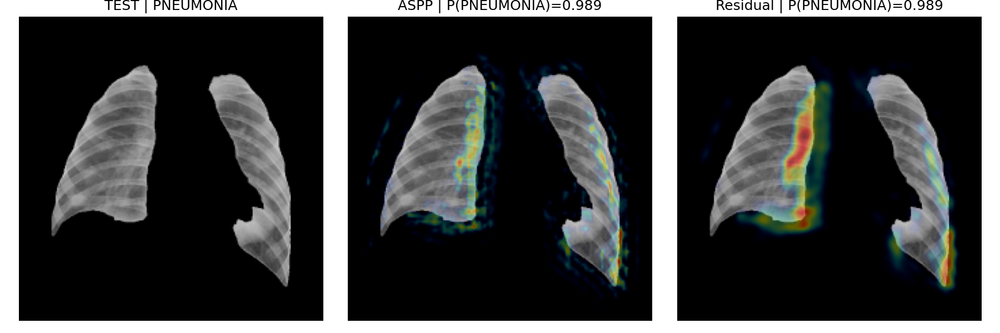

unet_resnet34__crop_mask__P2 | seed=42 | checkpoint: /home/arsyadmuhammad/AI Project/Pneumonia/output_pneunet_e5_segmentation_3level/runs/full/unet_resnet34__crop_mask__P2__seed_42/best.pt


experiment_id,seed,split,source_index,target_layer,target_class,padding_cam_ratio,probability_pneumonia
unet_resnet34__crop_mask__P2,42,test,5232,aspp_fuse.relu,0,0.000690,0.001065
unet_resnet34__crop_mask__P2,42,test,5232,context_refine.1.relu_out,0,0.000000,0.001065
unet_resnet34__crop_mask__P2,42,test,5233,aspp_fuse.relu,0,0.017182,0.000586
unet_resnet34__crop_mask__P2,42,test,5233,context_refine.1.relu_out,0,0.000000,0.000586
unet_resnet34__crop_mask__P2,42,test,5466,aspp_fuse.relu,1,0.011972,0.999414
unet_resnet34__crop_mask__P2,42,test,5466,context_refine.1.relu_out,1,0.008037,0.999414
unet_resnet34__crop_mask__P2,42,test,5467,aspp_fuse.relu,1,0.008575,0.896593
unet_resnet34__crop_mask__P2,42,test,5467,context_refine.1.relu_out,1,0.034195,0.896593


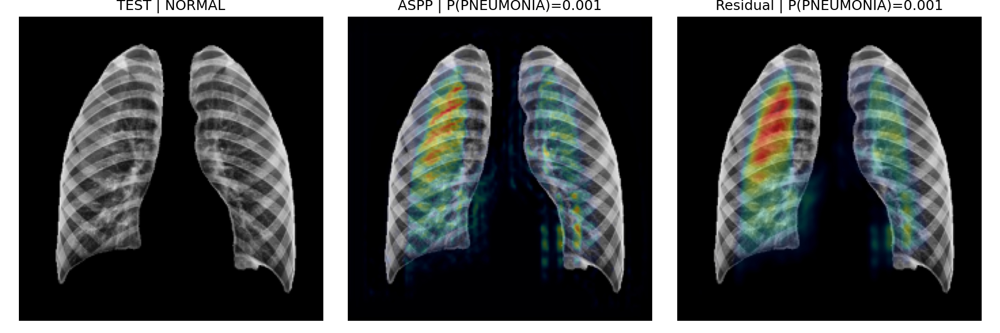

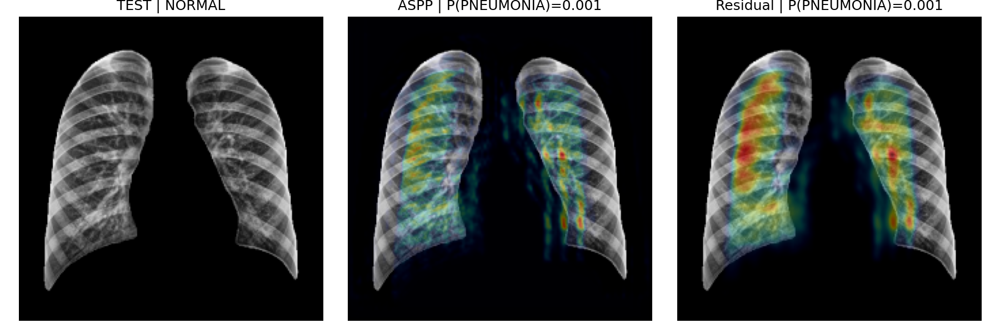

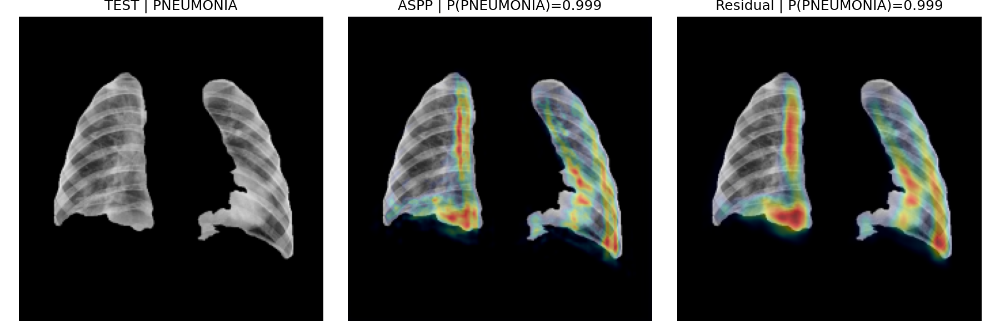

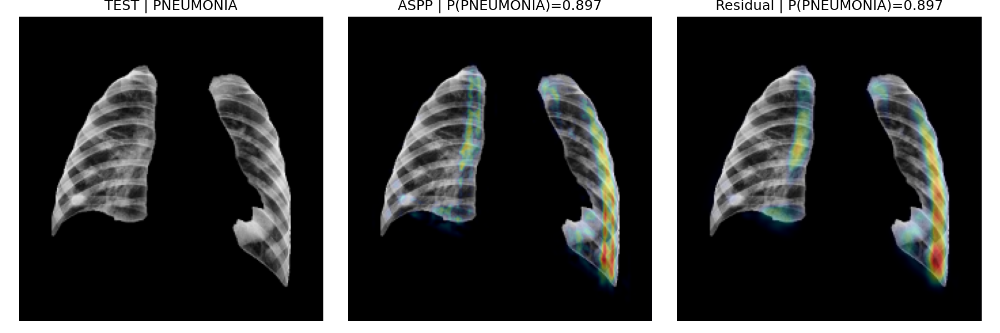

unet_resnet34__crop_mask__P3 | seed=42 | checkpoint: /home/arsyadmuhammad/AI Project/Pneumonia/output_pneunet_e5_segmentation_3level/runs/full/unet_resnet34__crop_mask__P3__seed_42/best.pt


experiment_id,seed,split,source_index,target_layer,target_class,padding_cam_ratio,probability_pneumonia
unet_resnet34__crop_mask__P3,42,test,5232,aspp_fuse.relu,0,0.000001,0.005392
unet_resnet34__crop_mask__P3,42,test,5232,context_refine.1.relu_out,0,0.000000,0.005392
unet_resnet34__crop_mask__P3,42,test,5233,aspp_fuse.relu,0,0.023761,0.001258
unet_resnet34__crop_mask__P3,42,test,5233,context_refine.1.relu_out,0,0.000000,0.001258
unet_resnet34__crop_mask__P3,42,test,5466,aspp_fuse.relu,1,0.090161,0.996329
unet_resnet34__crop_mask__P3,42,test,5466,context_refine.1.relu_out,1,0.025834,0.996329
unet_resnet34__crop_mask__P3,42,test,5467,aspp_fuse.relu,1,0.095402,0.936724
unet_resnet34__crop_mask__P3,42,test,5467,context_refine.1.relu_out,1,0.032216,0.936724


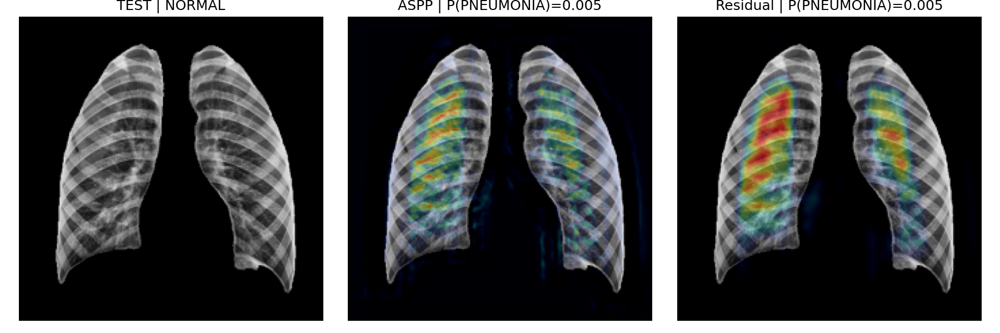

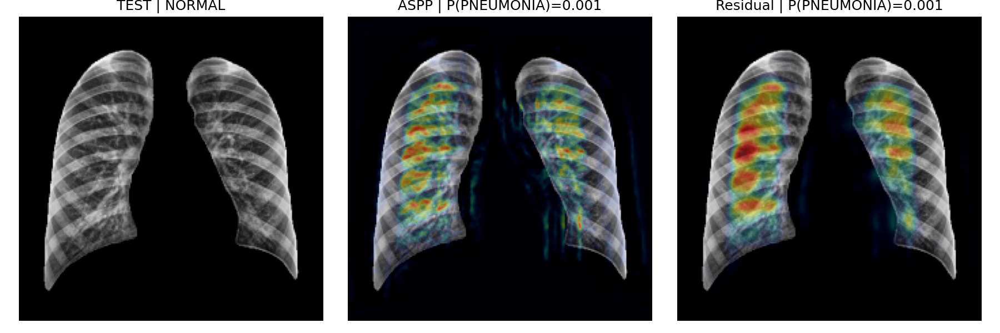

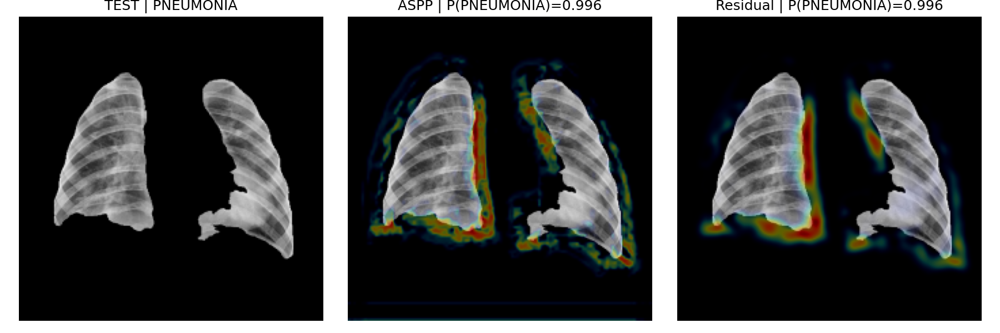

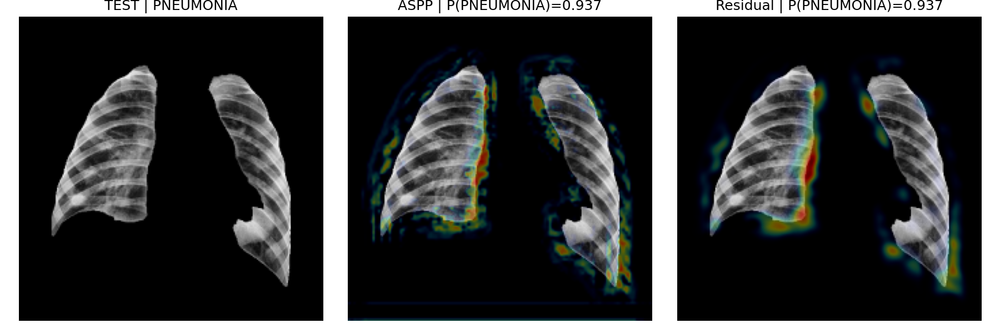

In [ ]:
def gradcam_one(model, image, target_layer, class_id):
    model.eval()
    target = model.get_submodule(target_layer)
    if image.shape != (224, 224):
        raise ValueError('GradCAM image must be 224x224')
    x = torch.from_numpy(image.astype(np.float32, copy=True))[None, None].to(DEVICE)
    cache = {}
    def hook(module, inputs, out):
        activation = out.detach().requires_grad_(True)
        cache['activation'] = activation
        return activation
    handle = target.register_forward_hook(hook)
    try:
        with torch.enable_grad():
            logits = model(x)
            score = (logits if class_id == 1 else -logits).sum()
            feat = cache['activation']
            grad = torch.autograd.grad(score, feat)[0]
            weights = grad.mean((2, 3), keepdim=True)
            cam = F.relu((feat.detach() * weights).sum(1, keepdim=True))
            cam = cam / cam.amax((2, 3), keepdim=True).clamp_min(1e-12)
            cam = F.interpolate(cam, (224, 224), mode='bilinear', align_corners=False)
            return cam[0, 0].detach().cpu().numpy(), float(torch.sigmoid(logits.detach()).item())
    finally:
        handle.remove()


def visualize_gradcam_run(exp_id, seed, mode='full', per_class=2):
    if exp_id not in EXP_BY_ID:
        raise ValueError(exp_id)
    split = 'val' if mode == 'smoke' else 'test'
    exp = EXP_BY_ID[exp_id]
    directory = result_directory(exp_id, seed, mode)
    checkpoint = directory / 'best.pt'
    if not checkpoint.is_file():
        raise FileNotFoundError(checkpoint)
    model = build_pneunet(dict(TRAIN_CONFIG, seed=seed)).to(DEVICE)
    blob = torch.load(checkpoint, map_location='cpu', weights_only=True)
    checkpoint_is_valid(blob, exp_id, seed)
    model.load_state_dict(blob['state_dict'], strict=True)
    model.eval()
    indices = np.concatenate([
        df.index[(df.split == split) & (df.y == cls)][:per_class].to_numpy(dtype=np.int64)
        for cls in (0, 1)
    ])
    dataset = E5ConditionDataset(exp['variant'], exp['pipeline'], indices,
                                 use_cache=(mode == 'full'))
    rows = []
    try:
        for i, source_idx in enumerate(indices):
            image = dataset[i][0].numpy()[0]
            image_display = image / 255. if image.max() > 1 else image
            fig, axes = plt.subplots(1, 3, figsize=(12, 4))
            axes[0].imshow(image_display, cmap='gray', vmin=0, vmax=1)
            axes[0].set_title(f"{split.upper()} | {df.iloc[source_idx].label}")
            for j, (name, layer) in enumerate((('ASPP', 'aspp_fuse.relu'),
                                               ('Residual', 'context_refine.1.relu_out')), 1):
                cam, p = gradcam_one(model, image, layer, int(df.iloc[source_idx].y))
                axes[j].imshow(image_display, cmap='gray', vmin=0, vmax=1)
                axes[j].imshow(cam, cmap='jet', alpha=.60 * cam, vmin=0, vmax=1)
                axes[j].set_title(f'{name} | P(PNEUMONIA)={p:.3f}')
                pad = get_padding_mask(exp['variant'], int(source_idx))
                ratio = float(cam[pad].sum() / (cam.sum() + 1e-12))
                rows.append(dict(experiment_id=exp_id, seed=seed, split=split,
                                 source_index=int(source_idx), target_layer=layer,
                                 target_class=int(df.iloc[source_idx].y),
                                 padding_cam_ratio=ratio, probability_pneumonia=p))
            for ax in axes:
                ax.axis('off')
            fig.tight_layout()
            fig.savefig(directory / f'gradcam_{split}_{source_idx}.png', dpi=150)
            plt.show()
            plt.close(fig)
        output = pd.DataFrame(rows)
        output.to_csv(directory / f'gradcam_{split}_summary.csv', index=False)
        return output
    finally:
        del dataset, model
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()


if RUN_GRADCAM:
    mode = MODELING_RUN_MODE
    selected = tuple(GRADCAM_EXPERIMENT_IDS) or (
        tuple(SELECTED_EXPERIMENT_IDS) if SELECTED_EXPERIMENT_IDS is not None else
        (('S0__P1', 'hybridgnet__crop__P2', 'unet_resnet34__crop_mask__P3') if mode == 'smoke' else tuple(exp['id'] for exp in EXPERIMENTS))
    )
    for seed in SEEDS:
        for exp_id in selected:
            print('GRADCAM', mode, exp_id, 'seed', seed, flush=True)
            display(visualize_gradcam_run(exp_id, seed, mode, GRADCAM_SAMPLES_PER_CLASS))
else:
    print('Grad-CAM OFF; aktifkan RUN_GRADCAM=True untuk smoke-val atau full-test.')


## 13. Interpretasi dan batasan eksperimen

- **Target ilmiah:** efektivitas pretrained lung segmenter sebagai preprocessing PneuNet E5, **bukan** kualitas segmentasi menurut Dice karena tidak tersedia ground-truth lung mask.
- **Tiga level:** (1) HybridGNet vs U-Net ResNet34; (2) crop, mask, crop + mask; (3) P1 normalisasi /255, P2 CLAHE RAW, P3 CLAHE + augmentasi RAW. Tambah kontrol `S0__P1/P2/P3` → 21 konfigurasi/seed.
- **Setiap run adalah model berbeda**, dibangun dari inisialisasi yang sama per seed agar perlakuan sebanding; checkpoint terbaik **setiap run** dipilih dengan minimum validation loss. Tidak ada satu bobot E5 yang dibagikan antar-ablasi.
- **Evaluasi:** semua konfigurasi menjalani validation dan test di pipeline yang identik dengan train-nya (augmentasi train-only), disimpan pada `full_summary.csv`, `final_test_summary.csv` dan `val_test_comparison.csv`.
- **Skor test bukan untuk seleksi:** semua hasil test dapat dideskripsikan dan dibandingkan, tetapi pelaporan model utama perlu menyatakan pemilihan berdasarkan validation untuk menghindari optimistic bias.
- **Smoke:** 1 epoch/1 update, val subset, Grad-CAM validation (opsional); tidak memakai test. Full: semua gambar & evaluasi test.
- **Kontras dan skala confounded:** P1 0–1 sedangkan P2/P3 0–255. Ini adalah perbandingan **pipeline gabungan**, bukan isolasi efek CLAHE vs normalisasi.
- **Artefak anatomi:** mask yang tampak benar belum tentu benar secara klinis. Inspeksi QC mask pediatrik sebelum full, laporkan kegagalan; Grad-CAM tidak membuktikan shortcut learning tanpa perturbation/occlusion.


# Tambahan paling bawah — U-Net ResNet34 hard mask: P1–P4 × 3 seed

Bagian ini memakai **kernel yang sudah berisi fungsi/data notebook**. Jalankan hanya tiga cell baru di bawah, bukan Run All. Cell sebelumnya, E5, split, optimizer, loss, batch 32, learning rate, dan early stopping dipertahankan.

| Pipeline | Hard mask U-Net | CLAHE | /255 | Augmentasi train |
|---|---|---|---|---|
| P1 | Ya | Tidak | Ya | Tidak |
| P2 | Ya | Ya | Tidak | Tidak |
| P3 | Ya | Ya | Tidak | 50% original, 25% rotasi, 25% Gaussian |
| P4 | Ya | Tidak | Ya | 50% original, 25% rotasi, 25% Gaussian |

**Seed:** 42, 123, 3407. Rencana augmentasi statis/parameter lama dipakai identik antarseed dan antara P3/P4; seed mengatur inisialisasi, dropout, dan urutan DataLoader. Validation/test tidak diaugmentasi. Hard mask diterapkan pada resolusi asli lalu letterbox, mengikuti implementasi sebelumnya.

**Reuse:** checkpoint P1–P3 seed 42 tetap dibaca dari folder lama; tidak disalin atau ditimpa. Setiap pasangan pipeline/seed diperiksa berdasarkan metadata konfigurasi, fingerprint data, provenance mask, dan checkpoint. Folder parsial dihentikan untuk menghindari overwrite.

**Output baru:** `output_pneunet_e5_segmentation_3level/runs/full/unet_resnet34_mask_ablation/`. Checkpoint baru hanya untuk pasangan yang belum ada; ekspor prediksi/metrics/CM per train/val/test, CSV per seed, mean±std (`ddof=1`), jumlah seed, grafik metrik, CM per seed, serta validation loss tersedia di folder ini. Statistik parsial ditandai `all_3_seeds=False`; std tidak diisi nol jika hanya satu seed. CM tidak dijumlahkan lintas seed karena gambar evaluasi berulang. Tidak ada pemilihan konfigurasi berdasarkan test.

**Default aman:** `RUN_MASK_ABLATION=False` hanya memvalidasi input dan menampilkan inventaris. Saat siap melatih, ubah menjadi `True` pada **cell konfigurasi baru** dan jalankan tiga cell baru saja. Dengan artefak yang sekarang tersedia: 3 reuse + 9 train missing; belum ada training baru yang dijalankan saat penambahan ini.


In [29]:
# P1-P4 U-Net hard-mask ablation. Execute only these appended cells.
MASK_ABLATION_SEEDS = (42, 123, 3407)
MASK_ABLATION_ROOT = WORKSPACE / 'output_pneunet_e5_segmentation_3level' / 'runs' / 'full' / 'unet_resnet34_mask_ablation'
MASK_ABLATION_LEGACY_ROOT = WORKSPACE / 'output_pneunet_e5_segmentation_3level' / 'runs' / 'full'
MASK_ABLATION_PIPELINES = {
    'P1': dict(PREPROCESS_PIPELINES['P1']),  # /255, no CLAHE, no augmentation
    'P2': dict(PREPROCESS_PIPELINES['P2']),  # CLAHE, RAW255, no augmentation
    'P3': dict(PREPROCESS_PIPELINES['P3']),  # CLAHE, RAW255, static train augmentation
    'P4': {'label': 'Hard mask + /255 + Aug, tanpa CLAHE',
           'clahe': False, 'augment': True, 'normalize': True},
}
# Safe default: inventory and validation only. Set True here to train missing runs.
RUN_MASK_ABLATION = True


In [30]:
import types as _mask_types
import copy as _mask_copy


def mask_ablation_context():
    """Use existing implementations with isolated globals; never alter old pipeline maps."""
    required = ('run_one', 'prepare_dataset', 'E5ConditionDataset', 'augmentation_plan',
                'df', 'TRAIN_CONFIG', 'mask_provenance', 'SOURCE_FINGERPRINT')
    missing = [name for name in required if name not in globals()]
    if missing:
        raise RuntimeError('Kernel state belum tersedia: ' + ', '.join(missing)
                           + '. Gunakan kernel notebook yang telah selesai, tanpa Run All.')
    scope = dict(globals())
    for name, value in tuple(scope.items()):
        if isinstance(value, _mask_types.FunctionType) and value.__globals__ is globals():
            clone = _mask_types.FunctionType(value.__code__, scope, value.__name__, value.__defaults__, value.__closure__)
            clone.__kwdefaults__ = value.__kwdefaults__
            scope[name] = clone
    scope['PREPROCESS_PIPELINES'] = _mask_copy.deepcopy(MASK_ABLATION_PIPELINES)
    scope['TRAIN_CONFIG'] = dict(TRAIN_CONFIG)
    # Hold the existing static augmentation assignment fixed across seeds/pipelines.
    # The three seeds affect initialization, dropout and DataLoader order as before.
    scope['augmentation_plan'] = augmentation_plan.copy(deep=True)
    scope['EVALUATE_TRAIN_AFTER_EACH_FULL_RUN'] = True
    scope['EVALUATE_TEST_AFTER_EACH_FULL_RUN'] = True
    scope['EXP_BY_ID'] = dict(EXP_BY_ID)
    for pipeline in MASK_ABLATION_PIPELINES:
        exp_id = f'unet_resnet34__mask__{pipeline}'
        scope['EXP_BY_ID'][exp_id] = dict(id=exp_id, segmenter='unet_resnet34', method='mask',
                                        variant='unet_resnet34__mask', pipeline=pipeline)
    dataset_methods = {}
    for name in ('__init__', '__len__', '__getitem__'):
        original = E5ConditionDataset.__dict__[name]
        dataset_methods[name] = _mask_types.FunctionType(original.__code__, scope, name,
                                                        original.__defaults__, original.__closure__)
    scope['E5ConditionDataset'] = type('MaskAblationDataset', (Dataset,), dataset_methods)

    def destination(exp_id, seed, mode='full'):
        if mode != 'full':
            raise ValueError('Bagian tambahan ini hanya untuk full comparison, bukan smoke lama.')
        if exp_id not in scope['EXP_BY_ID'] or scope['EXP_BY_ID'][exp_id]['variant'] != 'unet_resnet34__mask':
            raise ValueError(exp_id)
        return MASK_ABLATION_ROOT / f'{exp_id}__seed_{seed}'
    scope['result_directory'] = destination
    return scope


def mask_ablation_validate_saved(scope, directory, exp, seed):
    """Validate metadata/checkpoint before reuse; all old artifacts are read-only."""
    info = scope['saved_metadata_matches'](directory, exp, seed, 'full')
    if info is None:
        return None
    checkpoint = directory / 'best.pt'
    blob = torch.load(checkpoint, map_location='cpu', weights_only=True)
    scope['checkpoint_is_valid'](blob, exp['id'], seed)
    if blob.get('config') != dict(scope['TRAIN_CONFIG'], seed=seed):
        raise RuntimeError(f'Checkpoint config mismatch: {checkpoint}')
    del blob
    return info


def mask_ablation_plan(scope):
    rows = []
    for pipeline in MASK_ABLATION_PIPELINES:
        exp = scope['EXP_BY_ID'][f'unet_resnet34__mask__{pipeline}']
        for seed in MASK_ABLATION_SEEDS:
            target = scope['result_directory'](exp['id'], seed)
            legacy = MASK_ABLATION_LEGACY_ROOT / f'{exp["id"]}__seed_{seed}'
            candidates = [target, legacy] if pipeline != 'P4' else [target]
            available = []
            for directory in candidates:
                if not directory.exists():
                    continue
                info = mask_ablation_validate_saved(scope, directory, exp, seed)
                if info is None:
                    if any(directory.iterdir()):
                        raise RuntimeError(f'Run parsial ditemukan; tidak akan overwrite atau retrain checkpoint: {directory}')
                    continue
                available.append((directory, info))
            if len(available) > 1:
                # Do not silently choose between different checkpoints for the same pair.
                if hash_file(available[0][0] / 'best.pt') != hash_file(available[1][0] / 'best.pt'):
                    raise RuntimeError(f'Dua checkpoint berbeda untuk {pipeline}, seed={seed}; pilih sumber secara eksplisit.')
            source, info = available[0] if available else (None, None)
            rows.append(dict(pipeline=pipeline, seed=seed, experiment_id=exp['id'],
                             action='REUSE' if source else 'TRAIN_MISSING',
                             source_directory=str(source) if source else '',
                             checkpoint=str(source / 'best.pt') if source else '',
                             target_directory=str(target)))
    return pd.DataFrame(rows)


def mask_ablation_validate_inputs(scope):
    assert tuple(MASK_ABLATION_SEEDS) == (42, 123, 3407)
    assert scope['PREPROCESS_PIPELINES']['P4'] == {
        'label': 'Hard mask + /255 + Aug, tanpa CLAHE', 'clahe': False, 'augment': True, 'normalize': True}
    for pipeline in ('P1', 'P2', 'P3'):
        assert scope['PREPROCESS_PIPELINES'][pipeline] == PREPROCESS_PIPELINES[pipeline]
    assert scope['TRAIN_CONFIG'] == TRAIN_CONFIG
    assert E5_FLAGS == {'detail': True, 'fusion': False, 'context': True, 'normalized': True}
    for split, count in EXPECTED_COUNTS.items():
        assert int((df.split == split).sum()) == count
    pd.testing.assert_frame_equal(scope['augmentation_plan'], augmentation_plan)
    assert (scope['augmentation_plan'].loc[df.split != 'train', 'aug_mode'] == 0).all()
    assert tuple(AUGMENTATION_PROBS) == (.5, .25, .25)
    # Test one original, rotated and blurred training input using real cached lung masks.
    plan = scope['augmentation_plan']
    indexes = [int(plan.index[(plan.split == 'train') & (plan.aug_mode == mode)][0]) for mode in (0, 1, 2)]
    indexes += [int(df.index[df.split == split][0]) for split in ('val', 'test')]
    scope['require_masks']('unet_resnet34', indexes)
    dataset = scope['E5ConditionDataset']('unet_resnet34__mask', 'P4', indexes, use_cache=False)
    for pos, idx in enumerate(indexes):
        raw = scope['processed_image_uint8']('unet_resnet34__mask', idx, False)
        row = plan.iloc[idx]
        if row.split == 'train' and row.aug_mode == 1:
            raw = scope['rotate_image'](raw, row.rotation_degrees)
        elif row.split == 'train' and row.aug_mode == 2:
            raw = scope['gaussian_blur'](raw, row.gaussian_sigma)
        actual, label = dataset[pos]
        np.testing.assert_array_equal(actual.numpy()[0], raw.astype(np.float32) / 255.)
        assert actual.shape == (1, 224, 224) and torch.isfinite(actual).all()
        assert float(actual.min()) >= 0 and float(actual.max()) <= 1
        assert int(label.item()) == int(df.iloc[idx].y)
    return {'status': 'PASS', 'real_input_checks': len(indexes), 'training_executed': False,
            'augmentation_assignment': 'existing static plan fixed for all three seeds',
            'std_definition': 'sample standard deviation, ddof=1'}


def mask_ablation_evaluations(scope, item):
    """Reuse verified split predictions or backfill missing evaluation into NEW directories."""
    pipeline, seed = item['pipeline'], int(item['seed'])
    directory = Path(item['source_directory'])
    exp = scope['EXP_BY_ID'][item['experiment_id']]
    info = mask_ablation_validate_saved(scope, directory, exp, seed)
    records = []
    for split in ('train', 'val', 'test'):
        predictions_file = directory / f'{split}_predictions.csv'
        if predictions_file.is_file():
            frame = pd.read_csv(predictions_file)
        else:
            # Never backfill into a legacy checkpoint directory.
            evaluation_dir = MASK_ABLATION_ROOT / 'evaluations' / f'{pipeline}__seed_{seed}'
            config = dict(scope['TRAIN_CONFIG'], seed=seed)
            model = scope['build_pneunet'](config).to(DEVICE)
            try:
                checkpoint = torch.load(directory / 'best.pt', map_location='cpu', weights_only=True)
                scope['checkpoint_is_valid'](checkpoint, exp['id'], seed)
                model.load_state_dict(checkpoint['state_dict'], strict=True)
                scope['save_evaluated_split'](model, exp, seed, config, split, evaluation_dir, 'full')
            finally:
                del model
                gc.collect()
                if torch.cuda.is_available(): torch.cuda.empty_cache()
            frame = pd.read_csv(evaluation_dir / f'{split}_predictions.csv')
        indexes = df.index[df.split == split].to_numpy(dtype=np.int64)
        np.testing.assert_array_equal(frame.source_index, indexes)
        np.testing.assert_array_equal(frame.source_path.astype(str), df.loc[indexes, 'path'].astype(str))
        np.testing.assert_array_equal(frame.y_true, df.loc[indexes, 'y'])
        assert frame.source_path.is_unique and frame.probability.between(0, 1).all()
        metrics, report, cm, predictions = scope['binary_report'](frame.y_true, frame.probability, info['config']['threshold'])
        np.testing.assert_array_equal(frame.prediction, predictions)
        for key in ('macro_f1', 'recall_normal', 'recall_pneumonia', 'roc_auc'):
            if info.get(f'{split}_metrics'):
                np.testing.assert_allclose(metrics[key], info[f'{split}_metrics'][key], rtol=1e-5, atol=1e-7)
        exported = MASK_ABLATION_ROOT / 'evaluations' / f'{pipeline}__seed_{seed}'
        exported.mkdir(parents=True, exist_ok=True)
        frame.to_csv(exported / f'{split}_predictions.csv', index=False)
        pd.DataFrame(cm, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(exported / f'{split}_confusion_matrix.csv')
        to_json(exported / f'{split}_classification_report.json', report)
        to_json(exported / f'{split}_metrics.json', metrics)
        records.append(dict(pipeline=pipeline, seed=seed, split=split,
                            checkpoint=str(directory / 'best.pt'), **metrics))
    return records


def mask_ablation_reports(scope, inventory):
    records = []
    for item in inventory.to_dict('records'):
        if item['action'] == 'REUSE':
            records.extend(mask_ablation_evaluations(scope, item))
    if not records:
        return pd.DataFrame(), pd.DataFrame()
    table = pd.DataFrame(records)
    metrics = ['macro_f1', 'recall_normal', 'recall_pneumonia', 'roc_auc']
    long = table.melt(id_vars=['pipeline', 'seed', 'split'], value_vars=metrics, var_name='metric', value_name='value')
    summary = long.groupby(['pipeline', 'split', 'metric'], as_index=False).agg(
        mean=('value', 'mean'), std=('value', 'std'), n_seeds=('seed', 'nunique'))
    summary['all_3_seeds'] = summary.n_seeds.eq(3)
    summary['mean_plus_minus_std'] = summary.apply(
        lambda row: f'{row["mean"]:.4f} ± {row["std"]:.4f}' if row.n_seeds > 1 else f'{row["mean"]:.4f} (n=1; std unavailable)', axis=1)
    MASK_ABLATION_ROOT.mkdir(parents=True, exist_ok=True)
    table.to_csv(MASK_ABLATION_ROOT / 'comparison_per_seed_train_val_test.csv', index=False)
    summary.to_csv(MASK_ABLATION_ROOT / 'comparison_mean_std.csv', index=False)
    inventory.to_csv(MASK_ABLATION_ROOT / 'run_inventory.csv', index=False)
    for split in ('train', 'val', 'test'):
        fig, axes = plt.subplots(1, 4, figsize=(18, 4), squeeze=False)
        for axis, metric in zip(axes[0], metrics):
            group = summary[(summary.split == split) & (summary.metric == metric)].set_index('pipeline').reindex(MASK_ABLATION_PIPELINES)
            axis.bar(range(4), group['mean'], yerr=group['std'].fillna(0), capsize=4)
            for pipeline, points in table[table.split == split].groupby('pipeline'):
                axis.scatter([list(MASK_ABLATION_PIPELINES).index(pipeline)] * len(points), points[metric], color='black', s=15, zorder=3)
            axis.set(xticks=range(4), xticklabels=list(MASK_ABLATION_PIPELINES), title=metric, ylim=(0, 1.05))
        fig.suptitle(f'{split}: mean ± sample std; dots = seed; incomplete groups marked in CSV')
        fig.tight_layout(); fig.savefig(MASK_ABLATION_ROOT / f'{split}_metrics_mean_std.png', dpi=150)
        plt.show(); plt.close(fig)
        fig, axes = plt.subplots(4, 3, figsize=(12, 14), squeeze=False)
        for row, pipeline in enumerate(MASK_ABLATION_PIPELINES):
            for col, seed in enumerate(MASK_ABLATION_SEEDS):
                axis = axes[row, col]
                path = MASK_ABLATION_ROOT / 'evaluations' / f'{pipeline}__seed_{seed}' / f'{split}_confusion_matrix.csv'
                if path.exists():
                    cm = pd.read_csv(path, index_col=0).to_numpy()
                    axis.imshow(cm, cmap='Blues')
                    for a in range(2):
                        for b in range(2): axis.text(b, a, str(cm[a, b]), ha='center', va='center')
                    axis.set(xticks=[0, 1], yticks=[0, 1], xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
                             xlabel='Predicted', ylabel='True')
                else: axis.text(.5, .5, 'PENDING', ha='center'); axis.set_axis_off()
                axis.set_title(f'{pipeline} | seed={seed}')
        fig.suptitle(f'{split}: confusion matrix per seed; no pooling across repeated images')
        fig.tight_layout(); fig.savefig(MASK_ABLATION_ROOT / f'{split}_confusion_matrices.png', dpi=150)
        plt.show(); plt.close(fig)
    fig, axes = plt.subplots(1, 4, figsize=(18, 4), squeeze=False)
    for axis, pipeline in zip(axes[0], MASK_ABLATION_PIPELINES):
        for item in inventory[inventory.pipeline == pipeline].to_dict('records'):
            if item['action'] != 'REUSE': continue
            history = pd.read_csv(Path(item['source_directory']) / 'history.csv')
            axis.plot(history.epoch, history.val_loss, label=f'seed={item["seed"]}')
        axis.set(title=pipeline, xlabel='Epoch', ylabel='Validation loss'); axis.legend()
    fig.tight_layout(); fig.savefig(MASK_ABLATION_ROOT / 'validation_loss_per_seed.png', dpi=150)
    plt.show(); plt.close(fig)
    display(summary)
    return table, summary


def run_mask_ablation_missing(scope):
    inventory = mask_ablation_plan(scope)
    MASK_ABLATION_ROOT.mkdir(parents=True, exist_ok=True)
    to_json(MASK_ABLATION_ROOT / 'protocol.json', {
        'seeds': MASK_ABLATION_SEEDS, 'pipelines': MASK_ABLATION_PIPELINES,
        'train_config': scope['TRAIN_CONFIG'], 'source_fingerprint': SOURCE_FINGERPRINT,
        'augmentation_plan_sha256': hashlib.sha256(scope['augmentation_plan'].to_json(orient='records').encode()).hexdigest(),
        'augmentation_assignment': 'same existing fixed plan across seeds', 'std_ddof': 1})
    scope['augmentation_plan'].to_csv(MASK_ABLATION_ROOT / 'static_augmentation_plan.csv', index=False)
    for item in inventory.to_dict('records'):
        if item['action'] == 'REUSE':
            print('REUSE', item['pipeline'], item['seed'], item['checkpoint'], flush=True)
            continue
        target = Path(item['target_directory'])
        # Refuse partial folders and never replace an existing checkpoint.
        if target.exists() and any(target.iterdir()):
            raise RuntimeError(f'Target sudah berisi artefak; training dibatalkan agar tidak overwrite: {target}')
        scope['configure_pytorch'](item['seed'])
        exp = scope['EXP_BY_ID'][item['experiment_id']]
        scope['run_one'](exp, item['seed'], 'full')
        inventory = mask_ablation_plan(scope)
        mask_ablation_reports(scope, inventory)
    inventory = mask_ablation_plan(scope)
    return mask_ablation_reports(scope, inventory)


HASIL AKHIR P1–P4 × 3 SEED — dipulihkan 2026-11-19 02:29:10 UTC
12/12 COMPLETE; 36 evaluasi train/val/test tersedia.
Output dibaca dari CSV/JSON/PNG tersimpan; bukan training atau eksekusi ulang cell.
Mean ± std memakai sample std (ddof=1), tiga seed pada setiap kelompok.


pipeline,seed,action,checkpoint
P1,42,REUSE,/home/arsyadmuhammad/AI Project/Pneumonia/output_pneunet_e5_segmentation_3level/runs/full/unet_resnet34__mask__P1__seed_42/best.pt
P1,123,REUSE,/home/arsyadmuhammad/AI Project/Pneumonia/output_pneunet_e5_segmentation_3level/runs/full/unet_resnet34_mask_ablation/unet_resnet34__mask__P1__seed_123/best.pt
P1,3407,REUSE,/home/arsyadmuhammad/AI Project/Pneumonia/output_pneunet_e5_segmentation_3level/runs/full/unet_resnet34_mask_ablation/unet_resnet34__mask__P1__seed_3407/best.pt
P2,42,REUSE,/home/arsyadmuhammad/AI Project/Pneumonia/output_pneunet_e5_segmentation_3level/runs/full/unet_resnet34__mask__P2__seed_42/best.pt
P2,123,REUSE,/home/arsyadmuhammad/AI Project/Pneumonia/output_pneunet_e5_segmentation_3level/runs/full/unet_resnet34_mask_ablation/unet_resnet34__mask__P2__seed_123/best.pt
P2,3407,REUSE,/home/arsyadmuhammad/AI Project/Pneumonia/output_pneunet_e5_segmentation_3level/runs/full/unet_resnet34_mask_ablation/unet_resnet34__mask__P2__seed_3407/best.pt
P3,42,REUSE,/home/arsyadmuhammad/AI Project/Pneumonia/output_pneunet_e5_segmentation_3level/runs/full/unet_resnet34__mask__P3__seed_42/best.pt
P3,123,REUSE,/home/arsyadmuhammad/AI Project/Pneumonia/output_pneunet_e5_segmentation_3level/runs/full/unet_resnet34_mask_ablation/unet_resnet34__mask__P3__seed_123/best.pt
P3,3407,REUSE,/home/arsyadmuhammad/AI Project/Pneumonia/output_pneunet_e5_segmentation_3level/runs/full/unet_resnet34_mask_ablation/unet_resnet34__mask__P3__seed_3407/best.pt
P4,42,REUSE,/home/arsyadmuhammad/AI Project/Pneumonia/output_pneunet_e5_segmentation_3level/runs/full/unet_resnet34_mask_ablation/unet_resnet34__mask__P4__seed_42/best.pt


P1 seed=42: COMPLETE; epochs=29, best_epoch=22; checkpoint=/home/arsyadmuhammad/AI Project/Pneumonia/output_pneunet_e5_segmentation_3level/runs/full/unet_resnet34__mask__P1__seed_42/best.pt
P1 seed=123: COMPLETE; epochs=11, best_epoch=4; checkpoint=/home/arsyadmuhammad/AI Project/Pneumonia/output_pneunet_e5_segmentation_3level/runs/full/unet_resnet34_mask_ablation/unet_resnet34__mask__P1__seed_123/best.pt
P1 seed=3407: COMPLETE; epochs=14, best_epoch=7; checkpoint=/home/arsyadmuhammad/AI Project/Pneumonia/output_pneunet_e5_segmentation_3level/runs/full/unet_resnet34_mask_ablation/unet_resnet34__mask__P1__seed_3407/best.pt
P2 seed=42: COMPLETE; epochs=13, best_epoch=6; checkpoint=/home/arsyadmuhammad/AI Project/Pneumonia/output_pneunet_e5_segmentation_3level/runs/full/unet_resnet34__mask__P2__seed_42/best.pt
P2 seed=123: COMPLETE; epochs=12, best_epoch=5; checkpoint=/home/arsyadmuhammad/AI Project/Pneumonia/output_pneunet_e5_segmentation_3level/runs/full/unet_resnet34_mask_ablation/unet

pipeline,seed,split,checkpoint,accuracy,precision_pneumonia,recall_pneumonia,f1_pneumonia,precision_normal,recall_normal,f1_normal,macro_f1,roc_auc,pr_auc,samples,threshold
P1,42,train,/home/arsyadmuhammad/AI Project/Pneumonia/output_pneunet_e5_segmentation_3level/runs/full/unet_resnet34__mask__P1__seed_42/best.pt,0.948127,0.991118,0.938515,0.964100,0.846488,0.975793,0.906553,0.935326,0.992094,0.997343,4646,0.5
P1,123,train,/home/arsyadmuhammad/AI Project/Pneumonia/output_pneunet_e5_segmentation_3level/runs/full/unet_resnet34_mask_ablation/unet_resnet34__mask__P1__seed_123/best.pt,0.351485,0.990971,0.127320,0.225649,0.284083,0.996661,0.442140,0.333895,0.839670,0.934830,4646,0.5
P1,3407,train,/home/arsyadmuhammad/AI Project/Pneumonia/output_pneunet_e5_segmentation_3level/runs/full/unet_resnet34_mask_ablation/unet_resnet34__mask__P1__seed_3407/best.pt,0.924021,0.959881,0.936775,0.948187,0.829820,0.887312,0.857604,0.902896,0.972236,0.990470,4646,0.5
P2,42,train,/home/arsyadmuhammad/AI Project/Pneumonia/output_pneunet_e5_segmentation_3level/runs/full/unet_resnet34__mask__P2__seed_42/best.pt,0.908093,0.987730,0.887181,0.934759,0.748870,0.968280,0.844558,0.889659,0.979988,0.993348,4646,0.5
P2,123,train,/home/arsyadmuhammad/AI Project/Pneumonia/output_pneunet_e5_segmentation_3level/runs/full/unet_resnet34_mask_ablation/unet_resnet34__mask__P2__seed_123/best.pt,0.796814,0.785454,0.999130,0.879500,0.988462,0.214524,0.352538,0.616019,0.964332,0.985892,4646,0.5
P2,3407,train,/home/arsyadmuhammad/AI Project/Pneumonia/output_pneunet_e5_segmentation_3level/runs/full/unet_resnet34_mask_ablation/unet_resnet34__mask__P2__seed_3407/best.pt,0.950280,0.980293,0.952146,0.966014,0.872783,0.944908,0.907415,0.936715,0.988088,0.996078,4646,0.5
P3,42,train,/home/arsyadmuhammad/AI Project/Pneumonia/output_pneunet_e5_segmentation_3level/runs/full/unet_resnet34__mask__P3__seed_42/best.pt,0.944253,0.976112,0.948086,0.961895,0.861989,0.933222,0.896192,0.929044,0.984491,0.994681,4646,0.5
P3,123,train,/home/arsyadmuhammad/AI Project/Pneumonia/output_pneunet_e5_segmentation_3level/runs/full/unet_resnet34_mask_ablation/unet_resnet34__mask__P3__seed_123/best.pt,0.949419,0.974034,0.957367,0.965628,0.883055,0.926544,0.904277,0.934953,0.988359,0.996039,4646,0.5
P3,3407,train,/home/arsyadmuhammad/AI Project/Pneumonia/output_pneunet_e5_segmentation_3level/runs/full/unet_resnet34_mask_ablation/unet_resnet34__mask__P3__seed_3407/best.pt,0.935428,0.963486,0.948956,0.956166,0.859200,0.896494,0.877451,0.916808,0.979939,0.993264,4646,0.5
P4,42,train,/home/arsyadmuhammad/AI Project/Pneumonia/output_pneunet_e5_segmentation_3level/runs/full/unet_resnet34_mask_ablation/unet_resnet34__mask__P4__seed_42/best.pt,0.919931,0.987326,0.903712,0.943671,0.777181,0.966611,0.861607,0.902639,0.984566,0.994596,4646,0.5


=== TRAIN — mean ± std (n=3) ===


metric,pipeline,macro_f1,recall_normal,recall_pneumonia,roc_auc
,P1,0.7240 ± 0.3383,0.9533 ± 0.0581,0.6675 ± 0.4678,0.9347 ± 0.0829
,P2,0.8141 ± 0.1732,0.7092 ± 0.4286,0.9462 ± 0.0562,0.9775 ± 0.0121
,P3,0.9269 ± 0.0093,0.9188 ± 0.0196,0.9515 ± 0.0051,0.9843 ± 0.0042
,P4,0.9054 ± 0.0132,0.9243 ± 0.0496,0.9241 ± 0.0338,0.9785 ± 0.0059


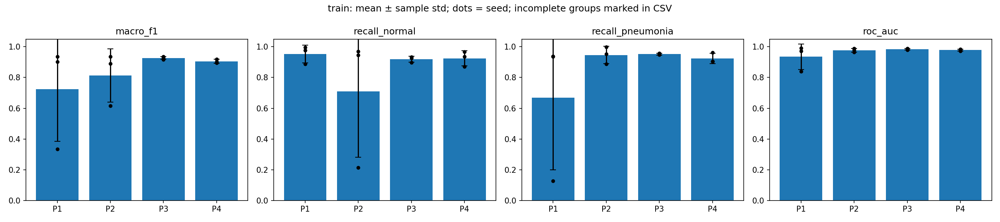

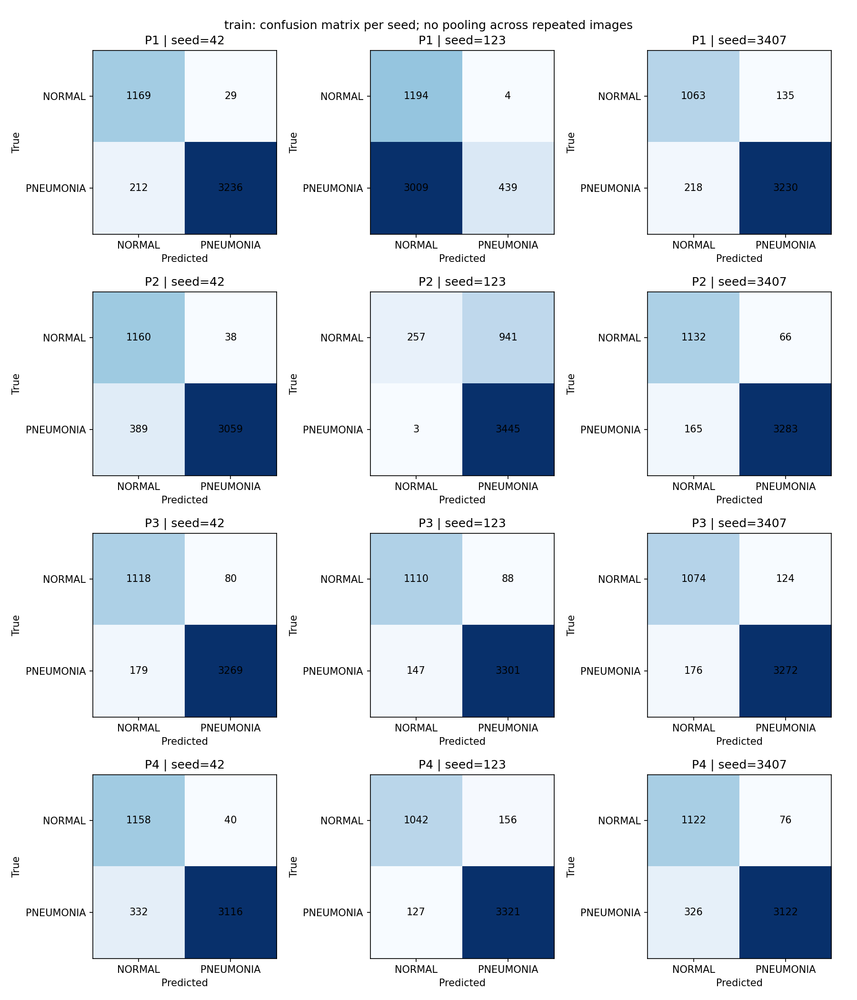

=== VAL — metrik per seed ===


pipeline,seed,split,checkpoint,accuracy,precision_pneumonia,recall_pneumonia,f1_pneumonia,precision_normal,recall_normal,f1_normal,macro_f1,roc_auc,pr_auc,samples,threshold
P1,42,val,/home/arsyadmuhammad/AI Project/Pneumonia/output_pneunet_e5_segmentation_3level/runs/full/unet_resnet34__mask__P1__seed_42/best.pt,0.919795,0.970874,0.919540,0.944510,0.798851,0.920530,0.855385,0.899947,0.981716,0.993530,586,0.5
P1,123,val,/home/arsyadmuhammad/AI Project/Pneumonia/output_pneunet_e5_segmentation_3level/runs/full/unet_resnet34_mask_ablation/unet_resnet34__mask__P1__seed_123/best.pt,0.343003,1.000000,0.114943,0.206186,0.281716,1.000000,0.439592,0.322889,0.832123,0.930436,586,0.5
P1,3407,val,/home/arsyadmuhammad/AI Project/Pneumonia/output_pneunet_e5_segmentation_3level/runs/full/unet_resnet34_mask_ablation/unet_resnet34__mask__P1__seed_3407/best.pt,0.911263,0.940230,0.940230,0.940230,0.827815,0.827815,0.827815,0.884022,0.954327,0.983641,586,0.5
P2,42,val,/home/arsyadmuhammad/AI Project/Pneumonia/output_pneunet_e5_segmentation_3level/runs/full/unet_resnet34__mask__P2__seed_42/best.pt,0.911263,0.989770,0.889655,0.937046,0.753846,0.973510,0.849711,0.893378,0.973647,0.991048,586,0.5
P2,123,val,/home/arsyadmuhammad/AI Project/Pneumonia/output_pneunet_e5_segmentation_3level/runs/full/unet_resnet34_mask_ablation/unet_resnet34__mask__P2__seed_123/best.pt,0.791809,0.780969,1.000000,0.877016,1.000000,0.192053,0.322222,0.599619,0.959686,0.984144,586,0.5
P2,3407,val,/home/arsyadmuhammad/AI Project/Pneumonia/output_pneunet_e5_segmentation_3level/runs/full/unet_resnet34_mask_ablation/unet_resnet34__mask__P2__seed_3407/best.pt,0.947099,0.974178,0.954023,0.963995,0.875000,0.927152,0.900322,0.932158,0.981761,0.994093,586,0.5
P3,42,val,/home/arsyadmuhammad/AI Project/Pneumonia/output_pneunet_e5_segmentation_3level/runs/full/unet_resnet34__mask__P3__seed_42/best.pt,0.931741,0.973621,0.933333,0.953052,0.828402,0.927152,0.875000,0.914026,0.983771,0.994592,586,0.5
P3,123,val,/home/arsyadmuhammad/AI Project/Pneumonia/output_pneunet_e5_segmentation_3level/runs/full/unet_resnet34_mask_ablation/unet_resnet34__mask__P3__seed_123/best.pt,0.948805,0.965517,0.965517,0.965517,0.900662,0.900662,0.900662,0.933090,0.987059,0.995548,586,0.5
P3,3407,val,/home/arsyadmuhammad/AI Project/Pneumonia/output_pneunet_e5_segmentation_3level/runs/full/unet_resnet34_mask_ablation/unet_resnet34__mask__P3__seed_3407/best.pt,0.935154,0.976019,0.935632,0.955399,0.834320,0.933775,0.881250,0.918325,0.977499,0.992737,586,0.5
P4,42,val,/home/arsyadmuhammad/AI Project/Pneumonia/output_pneunet_e5_segmentation_3level/runs/full/unet_resnet34_mask_ablation/unet_resnet34__mask__P4__seed_42/best.pt,0.924915,0.973366,0.924138,0.948113,0.809249,0.927152,0.864198,0.906155,0.980802,0.993281,586,0.5


=== VAL — mean ± std (n=3) ===


metric,pipeline,macro_f1,recall_normal,recall_pneumonia,roc_auc
,P1,0.7023 ± 0.3287,0.9161 ± 0.0862,0.6582 ± 0.4706,0.9227 ± 0.0796
,P2,0.8084 ± 0.1818,0.6976 ± 0.4384,0.9479 ± 0.0554,0.9717 ± 0.0112
,P3,0.9218 ± 0.0100,0.9205 ± 0.0175,0.9448 ± 0.0180,0.9828 ± 0.0049
,P4,0.8946 ± 0.0116,0.8764 ± 0.0470,0.9318 ± 0.0153,0.9713 ± 0.0087


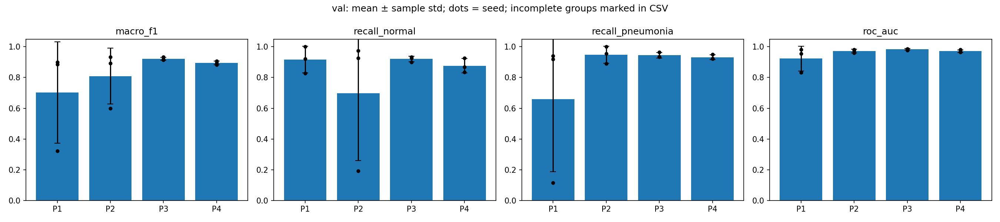

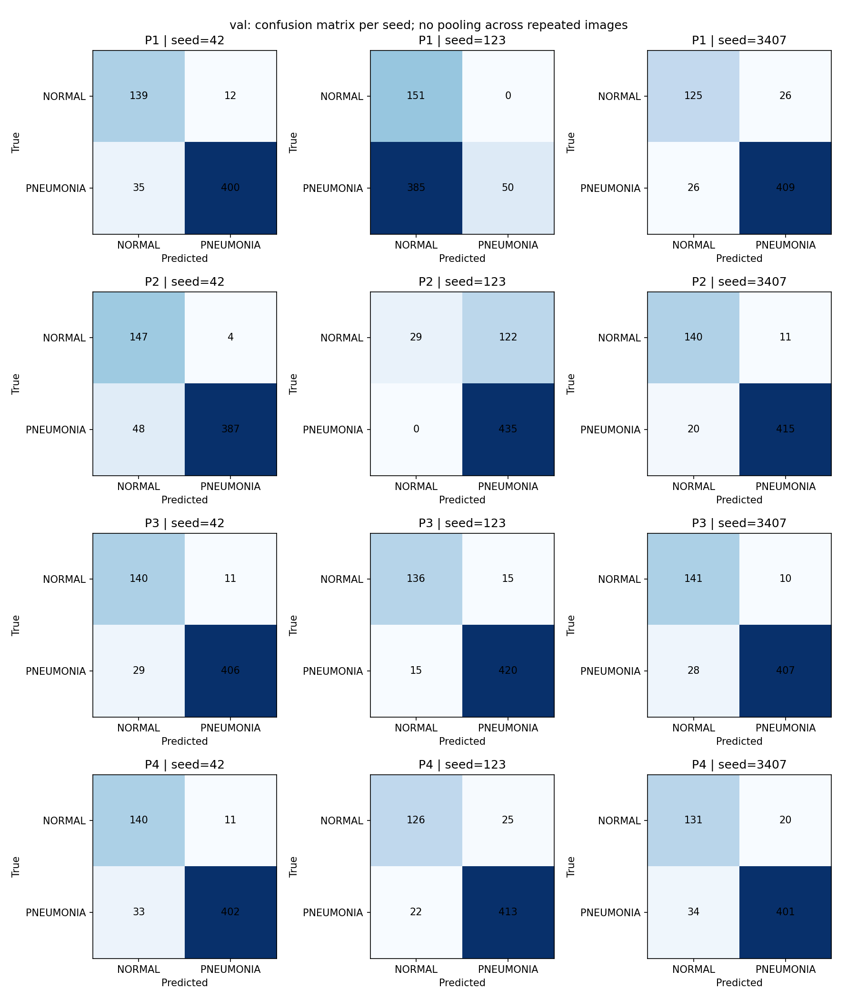

=== TEST — metrik per seed ===


pipeline,seed,split,checkpoint,accuracy,precision_pneumonia,recall_pneumonia,f1_pneumonia,precision_normal,recall_normal,f1_normal,macro_f1,roc_auc,pr_auc,samples,threshold
P1,42,test,/home/arsyadmuhammad/AI Project/Pneumonia/output_pneunet_e5_segmentation_3level/runs/full/unet_resnet34__mask__P1__seed_42/best.pt,0.955128,0.952500,0.976923,0.964557,0.959821,0.918803,0.938865,0.951711,0.993864,0.996414,624,0.5
P1,123,test,/home/arsyadmuhammad/AI Project/Pneumonia/output_pneunet_e5_segmentation_3level/runs/full/unet_resnet34_mask_ablation/unet_resnet34__mask__P1__seed_123/best.pt,0.439103,0.976190,0.105128,0.189815,0.400344,0.995726,0.571078,0.380447,0.818190,0.875592,624,0.5
P1,3407,test,/home/arsyadmuhammad/AI Project/Pneumonia/output_pneunet_e5_segmentation_3level/runs/full/unet_resnet34_mask_ablation/unet_resnet34__mask__P1__seed_3407/best.pt,0.886218,0.868360,0.964103,0.913730,0.926702,0.756410,0.832941,0.873336,0.957605,0.973260,624,0.5
P2,42,test,/home/arsyadmuhammad/AI Project/Pneumonia/output_pneunet_e5_segmentation_3level/runs/full/unet_resnet34__mask__P2__seed_42/best.pt,0.932692,0.962766,0.928205,0.945170,0.887097,0.940171,0.912863,0.929016,0.982238,0.989069,624,0.5
P2,123,test,/home/arsyadmuhammad/AI Project/Pneumonia/output_pneunet_e5_segmentation_3level/runs/full/unet_resnet34_mask_ablation/unet_resnet34__mask__P2__seed_123/best.pt,0.674679,0.657673,1.000000,0.793489,1.000000,0.132479,0.233962,0.513726,0.897430,0.902716,624,0.5
P2,3407,test,/home/arsyadmuhammad/AI Project/Pneumonia/output_pneunet_e5_segmentation_3level/runs/full/unet_resnet34_mask_ablation/unet_resnet34__mask__P2__seed_3407/best.pt,0.902244,0.874715,0.984615,0.926417,0.967568,0.764957,0.854415,0.890416,0.969494,0.981096,624,0.5
P3,42,test,/home/arsyadmuhammad/AI Project/Pneumonia/output_pneunet_e5_segmentation_3level/runs/full/unet_resnet34__mask__P3__seed_42/best.pt,0.939103,0.933498,0.971795,0.952261,0.949541,0.884615,0.915929,0.934095,0.979728,0.987128,624,0.5
P3,123,test,/home/arsyadmuhammad/AI Project/Pneumonia/output_pneunet_e5_segmentation_3level/runs/full/unet_resnet34_mask_ablation/unet_resnet34__mask__P3__seed_123/best.pt,0.935897,0.916667,0.987179,0.950617,0.975490,0.850427,0.908676,0.929647,0.985503,0.990939,624,0.5
P3,3407,test,/home/arsyadmuhammad/AI Project/Pneumonia/output_pneunet_e5_segmentation_3level/runs/full/unet_resnet34_mask_ablation/unet_resnet34__mask__P3__seed_3407/best.pt,0.935897,0.928922,0.971795,0.949875,0.949074,0.876068,0.911111,0.930493,0.982950,0.989466,624,0.5
P4,42,test,/home/arsyadmuhammad/AI Project/Pneumonia/output_pneunet_e5_segmentation_3level/runs/full/unet_resnet34_mask_ablation/unet_resnet34__mask__P4__seed_42/best.pt,0.948718,0.943069,0.976923,0.959698,0.959091,0.901709,0.929515,0.944607,0.982051,0.988699,624,0.5


=== TEST — mean ± std (n=3) ===


metric,pipeline,macro_f1,recall_normal,recall_pneumonia,roc_auc
,P1,0.7352 ± 0.3097,0.8903 ± 0.1222,0.6821 ± 0.4997,0.9232 ± 0.0927
,P2,0.7777 ± 0.2294,0.6125 ± 0.4249,0.9709 ± 0.0378,0.9497 ± 0.0457
,P3,0.9314 ± 0.0024,0.8704 ± 0.0178,0.9769 ± 0.0089,0.9827 ± 0.0029
,P4,0.9045 ± 0.0446,0.8234 ± 0.1177,0.9684 ± 0.0242,0.9690 ± 0.0170


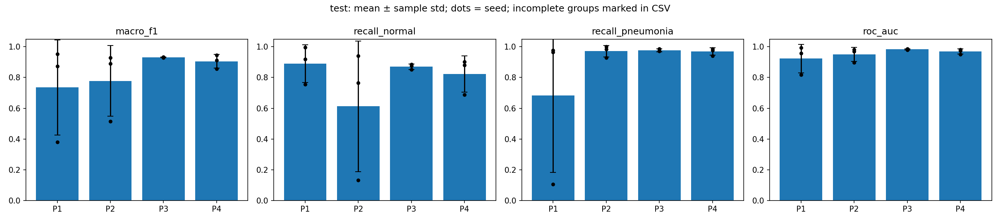

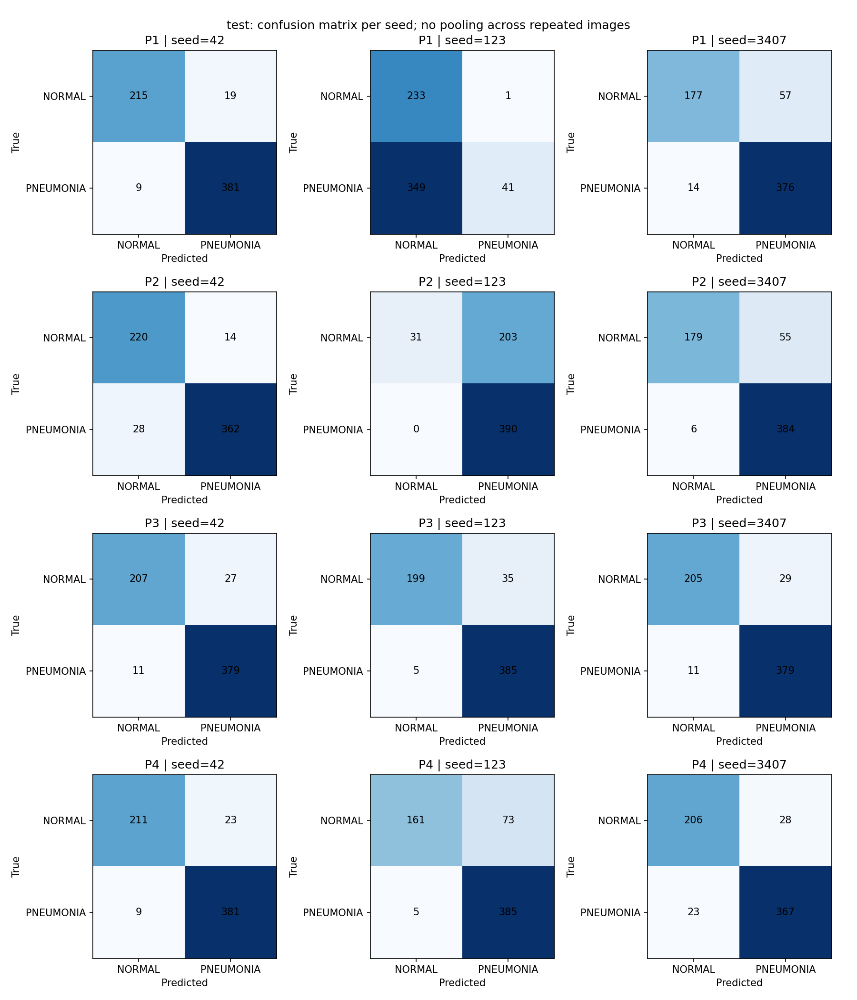

=== Kurva validation loss setiap seed ===


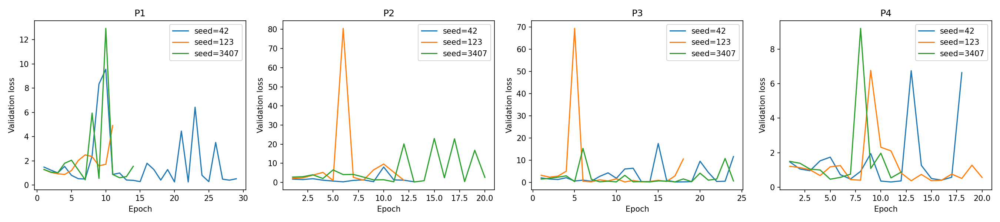

In [ ]:
# This cell does not train while RUN_MASK_ABLATION remains False.
mask_ablation_scope = mask_ablation_context()
mask_ablation_validation = mask_ablation_validate_inputs(mask_ablation_scope)
mask_ablation_inventory = mask_ablation_plan(mask_ablation_scope)
display(pd.DataFrame([mask_ablation_validation]))
display(mask_ablation_inventory)
print('REUSE:', int(mask_ablation_inventory.action.eq('REUSE').sum()),
      '| TRAIN_MISSING:', int(mask_ablation_inventory.action.eq('TRAIN_MISSING').sum()))
if RUN_MASK_ABLATION:
    mask_ablation_per_seed, mask_ablation_mean_std = run_mask_ablation_missing(mask_ablation_scope)
else:
    print('VALIDATION ONLY: tidak ada training/evaluasi ulang. Set RUN_MASK_ABLATION=True di cell baru untuk menjalankan kombinasi yang belum ada.')
